# NDI Pipeline  Month 2 Deliverable
## Arm 1: Real Public Data (DEPRESJON + PMData)
**Brief Section 4**  Shared pipeline module applied to both datasets.

### What this notebook does
1. Mounts Google Drive and loads both datasets
2. Extracts daily features from each dataset
3. Applies the five NDI pipeline components (neutrosophic decomposition, blocked TS-CV, baselines + lift, lambda grid search, SHAP)
4. Produces a side-by-side comparison of results

### Before running
- Upload `ndi_pipeline.py` to your Google Drive (e.g. `/MyDrive/ndi_project/ndi_pipeline.py`)
- Set the paths in **Cell 1** to match your Drive folder structure
- DEPRESJON: unzipped folder with `condition/`, `control/`, `scores.csv`
- PMData: folder with participant subfolders containing `fitness/` and `srp-scores.csv`

> **Version:** Final — all five components validated on DEPRESJON (n=55) and PMData (n=15). Lambda and baselines calibrated against external labels. See Cell 13 for scientific interpretation of AUROC and ρ(NDI,MADRS) results.


In [7]:
# ================================================================
# CELL 1.0  CONFIGURATION  (edit paths to match your Drive)
# Brief Section 6: all parameters in one place, fixed seed
# ================================================================

#  Google Drive paths
PIPELINE_MODULE   = "/content/drive/MyDrive/ndi_project/ndi_pipeline.py"
DEPRESJON_DIR     = "/content/drive/MyDrive/ndi_project/depresjon-dataset/data"
PMDATA_DIR        = "/content/drive/MyDrive/ndi_project/pmdata"
PMDATA_OVERVIEW   = "/content/drive/MyDrive/ndi_project/pmdata/participant-overview.xlsx"
RESULTS_DIR       = "/content/drive/MyDrive/ndi_project/results"

#  Reproducibility seed (Brief Section 6)
RANDOM_SEED = 42

#  Mount Drive
from google.colab import drive
drive.mount("/content/drive")

import os, sys
os.makedirs(RESULTS_DIR, exist_ok=True)

# Add pipeline module to path
sys.path.insert(0, os.path.dirname(PIPELINE_MODULE))

print("Drive mounted.")
print("DEPRESJON dir exists:", os.path.isdir(DEPRESJON_DIR))
print("PMData    dir exists:", os.path.isdir(PMDATA_DIR))
print("Pipeline  exists    :", os.path.isfile(PIPELINE_MODULE))


Mounted at /content/drive
Drive mounted.
DEPRESJON dir exists: True
PMData    dir exists: True
Pipeline  exists    : True


In [3]:
# Cell 1.1 --- results-capture helper (moved here so item 1 / item 3 / item 4 / item 7
#     calls earlier in the notebook can all use it) ---
import json, datetime

RESULTS_FINAL_DIR = os.path.join(os.path.dirname(RESULTS_DIR), "results_final")
os.makedirs(RESULTS_FINAL_DIR, exist_ok=True)
MANIFEST_PATH = os.path.join(RESULTS_FINAL_DIR, "manifest.json")
_manifest = []

def save_result(item_no, description, obj, filename, cell_label):
    path = os.path.join(RESULTS_FINAL_DIR, filename)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    else:
        with open(path, "w") as f:
            json.dump(obj, f, indent=2, default=str)
    _manifest.append(dict(item=item_no, description=description, cell=cell_label,
                           file=filename, saved_at=datetime.datetime.now().isoformat()))
    with open(MANIFEST_PATH, "w") as f:
        json.dump(_manifest, f, indent=2)
    print(f"[item {item_no}] saved -> {filename}")

In [4]:
import shutil, json, os, numpy as np

_parent = os.path.dirname(RESULTS_DIR)
FROZEN_V1_DIR = os.path.join(_parent, "results_final_v1_frozen_backup")

if not os.path.exists(FROZEN_V1_DIR):
    _existing_manifest = json.load(open(os.path.join(RESULTS_FINAL_DIR, "manifest.json")))
    print(f"Current manifest.json has {len(_existing_manifest)} entries, items present: "
          f"{sorted(set(m['item'] for m in _existing_manifest))}")
    print("Confirm this looks like your complete v1 record before proceeding.")
    shutil.copytree(RESULTS_FINAL_DIR, FROZEN_V1_DIR)
    print(f"Backed up to {FROZEN_V1_DIR}")
else:
    print(f"Frozen backup already exists at {FROZEN_V1_DIR} -- not overwriting.")

RESULTS_FINAL_DIR = os.path.join(_parent, "results_regen_scratch")   # this session writes here only
os.makedirs(RESULTS_FINAL_DIR, exist_ok=True)
MANIFEST_PATH = os.path.join(RESULTS_FINAL_DIR, "manifest.json")
_manifest = []

def benjamini_hochberg(pvals):   # identical to the CELL 14.9 definition -- redefined here
    pvals = np.asarray(pvals, dtype=float); n = len(pvals)
    order = np.argsort(pvals); q_raw = pvals[order] * n / (np.arange(n) + 1)
    q_sorted = np.minimum.accumulate(q_raw[::-1])[::-1]
    q = np.empty(n); q[order] = np.clip(q_sorted, 0, 1); return q

print("Frozen v1 backup:", FROZEN_V1_DIR, "| session writes ->", RESULTS_FINAL_DIR)

Frozen backup already exists at /content/drive/MyDrive/ndi_project/results_final_v1_frozen_backup -- not overwriting.
Frozen v1 backup: /content/drive/MyDrive/ndi_project/results_final_v1_frozen_backup | session writes -> /content/drive/MyDrive/ndi_project/results_regen_scratch


In [8]:
# ================================================================
# CELL 2  INSTALL DEPENDENCIES + IMPORTS
# ================================================================
import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

for pkg in ["xgboost", "shap"]:
    install(pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as tri
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings("ignore")
np.random.seed(RANDOM_SEED)

import importlib.util, sys as _sys

spec = importlib.util.spec_from_file_location("ndi_pipeline", PIPELINE_MODULE)
ndi  = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ndi)

print("ndi_pipeline loaded. Components available:")
for fn in ["neutrosophic_decompose","blocked_tscv","run_baselines",
           "lambda_grid_search","shap_attribution"]:
    print(f"  ndi.{fn}: {'OK' if hasattr(ndi, fn) else 'MISSING'}")


ndi_pipeline loaded. Components available:
  ndi.neutrosophic_decompose: OK
  ndi.blocked_tscv: OK
  ndi.run_baselines: OK
  ndi.lambda_grid_search: OK
  ndi.shap_attribution: OK


## Dataset 1  DEPRESJON

In [6]:
# ================================================================
# CELL 3 -- LOAD DEPRESJON DATASET
# Structure: depresjon-dataset/data/condition/condition_1.csv ...
#            depresjon-dataset/data/control/control_1.csv ...
#            depresjon-dataset/data/scores.csv
# scores.csv: number=condition_1/condition_2/control_1 etc.
# ================================================================
import os, glob
import pandas as pd
import numpy as np

def load_depresjon(base_dir):
    scores_path = os.path.join(base_dir, "scores.csv")
    scores      = pd.read_csv(scores_path)
    scores.columns = [c.strip().lower() for c in scores.columns]
    print("scores.csv columns:", list(scores.columns))
    print(scores.head(3))

    # Build lookup: pid_string -> (madrs1, madrs2)
    madrs_lookup = {}
    for _, row in scores.iterrows():
        key = str(row["number"]).strip()
        m1  = float(row["madrs1"]) if str(row.get("madrs1","NA")).strip() not in ["NA","nan",""] else np.nan
        m2  = float(row["madrs2"]) if str(row.get("madrs2","NA")).strip() not in ["NA","nan",""] else np.nan
        madrs_lookup[key] = (m1, m2)

    participants = []

    for group in ["condition", "control"]:
        folder = os.path.join(base_dir, group)
        csvs   = sorted(glob.glob(os.path.join(folder, "*.csv")))
        print(f"\n{group}: {len(csvs)} files found")

        for csv_path in csvs:
            pid = os.path.splitext(os.path.basename(csv_path))[0]
            try:
                df = pd.read_csv(csv_path)
                df.columns = [c.strip().lower() for c in df.columns]

                if "timestamp" not in df.columns or "activity" not in df.columns:
                    print(f"  SKIP {pid}: columns={list(df.columns)}")
                    continue

                madrs1, madrs2 = madrs_lookup.get(pid, (np.nan, np.nan))
                madrs_mean     = np.nanmean([madrs1, madrs2])

                daily = ndi.extract_daily_features(df)

                if len(daily) < 5:
                    print(f"  SKIP {pid}: only {len(daily)} days")
                    continue

                participants.append(dict(
                    pid          = pid,
                    group        = group,
                    is_depressed = int(group == "condition"),
                    madrs1       = madrs1,
                    madrs2       = madrs2,
                    madrs_mean   = madrs_mean,
                    n_days       = len(daily),
                    days_df      = daily,
                ))
                print(f"  OK {pid}: {len(daily)} days  MADRS={madrs_mean:.0f}" if not np.isnan(madrs_mean)
                      else f"  OK {pid}: {len(daily)} days  MADRS=N/A")

            except Exception as e:
                print(f"  ERROR {pid}: {e}")

    return participants

depresjon_participants = load_depresjon(DEPRESJON_DIR)

condition_p = [p for p in depresjon_participants if p["group"] == "condition"]
control_p   = [p for p in depresjon_participants if p["group"] == "control"]
print("  NOTE: madrs_mean = NaN for control participants — expected, DEPRESJON administered MADRS to condition group only.")
print(f"\nLoaded total: {len(depresjon_participants)} participants")
print(f"  Condition (depressed): {len(condition_p)}")
print(f"  Control   (healthy)  : {len(control_p)}")
if condition_p:
    print(f"  Median days condition: {np.median([p['n_days'] for p in condition_p]):.0f}")
    valid_madrs = [p['madrs_mean'] for p in condition_p if not np.isnan(p['madrs_mean'])]
    if valid_madrs:
        print(f"  MADRS range: {min(valid_madrs):.0f} to {max(valid_madrs):.0f}")
if control_p:
    print(f"  Median days control  : {np.median([p['n_days'] for p in control_p]):.0f}")

scores.csv columns: ['number', 'days', 'gender', 'age', 'afftype', 'melanch', 'inpatient', 'edu', 'marriage', 'work', 'madrs1', 'madrs2']
        number  days  gender    age  afftype  melanch  inpatient   edu  \
0  condition_1    11       2  35-39      2.0      2.0        2.0  6-10   
1  condition_2    18       2  40-44      1.0      2.0        2.0  6-10   
2  condition_3    13       1  45-49      2.0      2.0        2.0  6-10   

   marriage  work  madrs1  madrs2  
0       1.0   2.0    19.0    19.0  
1       2.0   2.0    24.0    11.0  
2       2.0   2.0    24.0    25.0  

condition: 23 files found
  OK condition_1: 17 days  MADRS=19
  OK condition_10: 16 days  MADRS=24
  OK condition_11: 17 days  MADRS=24
  OK condition_12: 16 days  MADRS=23
  OK condition_13: 19 days  MADRS=16
  OK condition_14: 16 days  MADRS=24
  OK condition_15: 16 days  MADRS=16
  OK condition_16: 30 days  MADRS=15
  OK condition_17: 16 days  MADRS=16
  OK condition_18: 16 days  MADRS=16
  OK condition_19: 16 day

In [7]:
# ================================================================
# CELL 4  BUILD DEPRESJON FEATURE MATRIX
# FIX 2: neutro_df built here is FOR VISUALISATION ONLY.
# All CV metrics rebuild features per-fold in Cell 8.
# FIX 3: calls ndi.build_neutrosophic_features (module is
# authoritative). Inline decomposition deleted.
# ================================================================

FEAT_NAMES = ndi.DEPRESJON_FEATURE_NAMES
DOMAIN_MAP = ndi.DEPRESJON_DOMAIN_MAP

def build_participant_neutrosophic(p):
    """
    For one participant: extract feature matrix, apply neutrosophic
    decomposition using full-series train_mask (visualisation only).
    WARNING: Do NOT use neutro_df from this function in any CV result.
    All CV evaluation rebuilds features inside each fold (Cell 8).
    """
    df = p["days_df"].copy().reset_index(drop=True)
    for col in FEAT_NAMES:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = 0.0

    X = df[FEAT_NAMES].values
    n = len(X)

    # Full-series train_mask: all True — avoids the ValueError in
    # build_neutrosophic_features while making clear this is in-sample.
    # VISUALISATION ONLY — do not use for any headline metric.
    train_mask_full = np.ones(n, dtype=bool)
    neutro_df = ndi.build_neutrosophic_features(
        X, FEAT_NAMES, train_mask=train_mask_full)

    result = pd.concat([df[["date"]].reset_index(drop=True),
                        neutro_df.reset_index(drop=True)], axis=1)
    result["pid"]          = p["pid"]
    result["group"]        = p["group"]
    result["is_depressed"] = p["is_depressed"]
    result["madrs_mean"]   = p["madrs_mean"]
    for col in FEAT_NAMES:
        result[col] = df[col].values
    return result

print("Computing neutrosophic features (visualisation only)...")
neutro_frames = []
for p in depresjon_participants:
    try:
        nf = build_participant_neutrosophic(p)
        neutro_frames.append(nf)
        p["neutro_df"] = nf
    except Exception as e:
        print(f"  ERROR {p['pid']}: {e}")

depresjon_all = pd.concat(neutro_frames, ignore_index=True)
print(f"Total rows: {len(depresjon_all)}")
print("NOTE: neutro_df is for visualisation only. CV metrics use per-fold features.")

Computing neutrosophic features (visualisation only)...
Total rows: 1144
NOTE: neutro_df is for visualisation only. CV metrics use per-fold features.


## Dataset 2  PMData

In [9]:
# ================================================================
# CELL 5 -- LOAD PMDATA DATASET
# Actual structure:
#   pmdata/p01/fitbit/heart_rate.json
#   pmdata/p01/fitbit/resting_heart_rate.json
#   pmdata/p01/fitbit/sleep.json
#   pmdata/p01/fitbit/sleep_score.csv
#   pmdata/p01/fitbit/steps.json
#   pmdata/p01/fitbit/lightly_active_minutes.json
#   pmdata/p01/fitbit/moderately_active_minutes.json
#   pmdata/p01/fitbit/very_active_minutes.json
#   pmdata/p01/fitbit/sedentary_minutes.json
#   pmdata/p01/pmsys/wellness.csv    <- daily mood/wellness self-report
#   pmdata/p01/pmsys/srpe.csv
#   pmdata/participant-overview.xlsx <- max HR, age, gender per participant
# ================================================================
import os, glob, json as _json
import pandas as pd
import numpy as np
import openpyxl  # for reading xlsx

#  Load participant overview
try:
    overview = pd.read_excel(PMDATA_OVERVIEW, header=1)
    overview.columns = [str(c).strip().lower().replace(" ","_")
                        for c in overview.columns]
    overview = overview.dropna(subset=[overview.columns[0]])
    print("participant-overview columns:", list(overview.columns))
    print(overview.head(3))
except Exception as e:
    print(f"Could not load participant-overview: {e}")
    overview = pd.DataFrame()

#  Helper: load one JSON Fitbit file
def load_fitbit_json(path):
    """Load a Fitbit JSON file. Returns list of {dateTime, value} dicts."""
    try:
        with open(path) as f:
            data = _json.load(f)
        if isinstance(data, list):
            return data
        return []
    except Exception:
        return []

def fitbit_to_daily(entries, value_key="value", agg="mean"):
    """Aggregate minute/entry-level Fitbit data to daily values."""
    rows = {}
    for entry in entries:
        date = str(entry.get("dateTime",""))[:10]
        val  = entry.get(value_key, entry.get("value", None))
        if date and val is not None:
            try:
                val = float(val)
                rows.setdefault(date, []).append(val)
            except (ValueError, TypeError):
                pass
    if agg == "mean":
        return {d: np.mean(v) for d,v in rows.items()}
    elif agg == "sum":
        return {d: np.sum(v) for d,v in rows.items()}
    elif agg == "max":
        return {d: np.max(v) for d,v in rows.items()}
    return rows

#  Helper: load resting heart rate JSON
def load_resting_hr(path):
    """resting_heart_rate.json has nested value.value structure."""
    entries = load_fitbit_json(path)
    rows = {}
    for entry in entries:
        date = str(entry.get("dateTime",""))[:10]
        val  = entry.get("value",{})
        if isinstance(val, dict):
            rhr = val.get("value", val.get("restingHeartRate", None))
        else:
            rhr = val
        if date and rhr is not None:
            try:
                rows[date] = float(rhr)
            except (ValueError, TypeError):
                pass
    return rows

#  Helper: load sleep.json
def load_sleep(path):
    """Extract sleep efficiency and minutes asleep from sleep.json."""
    entries = load_fitbit_json(path)
    eff_rows = {}; min_rows = {}
    for entry in entries:
        # Each entry is one sleep session
        date = str(entry.get("dateOfSleep", entry.get("dateTime","")))[:10]
        eff  = entry.get("efficiency", None)
        mins = entry.get("minutesAsleep", None)
        if date and eff is not None:
            try:
                eff_rows[date] = float(eff)
            except (ValueError, TypeError):
                pass
        if date and mins is not None:
            try:
                min_rows[date] = float(mins)
            except (ValueError, TypeError):
                pass
    return eff_rows, min_rows

#  Helper: load sleep_score.csv
def load_sleep_score(path):
    """sleep_score.csv: timestamp, overall_score, composition_score, ..."""
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip().lower() for c in df.columns]
        # Timestamp column
        ts_col = next((c for c in df.columns if "timestamp" in c or "date" in c), None)
        score_col = next((c for c in df.columns if "overall" in c or "score" in c), None)
        if ts_col and score_col:
            df["date"] = pd.to_datetime(df[ts_col]).dt.strftime("%Y-%m-%d")
            return dict(zip(df["date"], pd.to_numeric(df[score_col], errors="coerce")))
    except Exception:
        pass
    return {}

#  Helper: load wellness.csv
def load_wellness(path):
    """
    pmsys/wellness.csv: daily self-report.
    Columns typically: date, fatigue, mood, readiness, sleep_duration,
                       sleep_quality, stress, soreness
    """
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip().lower().replace(" ","_") for c in df.columns]
        if "date" not in df.columns:
            return pd.DataFrame()
        df["date"] = pd.to_datetime(df["date"]).dt.strftime("%Y-%m-%d")
        return df
    except Exception:
        return pd.DataFrame()

#  Helper: load googledocs/reporting.csv
def load_reporting(path):
    """
    reporting.csv: date, timestamp, meals, weight, glasses_of_fluid, alcohol
    """
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip().lower().replace(" ","_") for c in df.columns]
        date_col = next((c for c in df.columns if "date" in c), None)
        if date_col:
            df["date"] = pd.to_datetime(df[date_col]).dt.strftime("%Y-%m-%d")
            return df
    except Exception:
        pass
    return pd.DataFrame()

#  Main loader
def load_pmdata_participant(pid_dir):
    """
    Load all data for one PMData participant.
    Returns a daily DataFrame with all available signals.
    """
    fitbit_dir    = os.path.join(pid_dir, "fitbit")
    pmsys_dir     = os.path.join(pid_dir, "pmsys")
    googledocs_dir= os.path.join(pid_dir, "googledocs")

    daily = {}  # date -> feature dict

    def add_series(series_dict, col_name):
        for date, val in series_dict.items():
            daily.setdefault(date, {})[col_name] = val

    # Resting heart rate (most reliable HR signal for daily level)
    rhr_path = os.path.join(fitbit_dir, "resting_heart_rate.json")
    if os.path.isfile(rhr_path):
        add_series(load_resting_hr(rhr_path), "resting_hr")

    # Steps
    steps_path = os.path.join(fitbit_dir, "steps.json")
    if os.path.isfile(steps_path):
        add_series(fitbit_to_daily(load_fitbit_json(steps_path), agg="sum"), "steps")

    # Activity minutes
    for fname, col in [
        ("lightly_active_minutes.json",    "lightly_active_min"),
        ("moderately_active_minutes.json", "moderately_active_min"),
        ("very_active_minutes.json",       "very_active_min"),
        ("sedentary_minutes.json",         "sedentary_min"),
    ]:
        p = os.path.join(fitbit_dir, fname)
        if os.path.isfile(p):
            add_series(fitbit_to_daily(load_fitbit_json(p), agg="sum"), col)

    # Sleep
    sleep_path = os.path.join(fitbit_dir, "sleep.json")
    if os.path.isfile(sleep_path):
        eff, mins = load_sleep(sleep_path)
        add_series(eff,  "sleep_efficiency")
        add_series(mins, "sleep_minutes")

    # Sleep score
    ss_path = os.path.join(fitbit_dir, "sleep_score.csv")
    if os.path.isfile(ss_path):
        add_series(load_sleep_score(ss_path), "sleep_score")

    if not daily:
        return pd.DataFrame()

    # Build base daily DataFrame
    df = pd.DataFrame.from_dict(daily, orient="index")
    df.index.name = "date"
    df = df.reset_index()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    # Active minutes total
    act_cols = [c for c in ["lightly_active_min","moderately_active_min","very_active_min"] if c in df.columns]
    if act_cols:
        df["active_minutes_total"] = df[act_cols].sum(axis=1)

    # Merge wellness
    w_path = os.path.join(pmsys_dir, "wellness.csv")
    if os.path.isfile(w_path):
        well = load_wellness(w_path)
        if not well.empty:
            well["date"] = pd.to_datetime(well["date"])
            df = df.merge(well, on="date", how="left")

    # Merge reporting (weight, fluid)
    r_path = os.path.join(googledocs_dir, "reporting.csv")
    if os.path.isfile(r_path):
        rep = load_reporting(r_path)
        if not rep.empty:
            rep["date"] = pd.to_datetime(rep["date"])
            rep_agg = rep.groupby("date").agg(
                weight         = ("weight", "mean"),
                glasses_of_fluid=("glasses_of_fluid","mean") if "glasses_of_fluid" in rep.columns else ("date","count"),
            ).reset_index()
            df = df.merge(rep_agg, on="date", how="left")

    df["date"] = df["date"].dt.strftime("%Y-%m-%d")
    return df


#  Load all participants
pmdata_participants = []
participant_dirs = sorted([
    os.path.join(PMDATA_DIR, d)
    for d in os.listdir(PMDATA_DIR)
    if os.path.isdir(os.path.join(PMDATA_DIR, d)) and d.startswith("p")
])
print(f"Found {len(participant_dirs)} participant directories")

for pdir in participant_dirs:
    pid = os.path.basename(pdir)
    try:
        daily = load_pmdata_participant(pdir)
        if len(daily) < 7:
            print(f"  SKIP {pid}: only {len(daily)} days")
            continue

        # Get max HR from overview
        max_hr = np.nan
        if not overview.empty:
            hr_col = next((c for c in overview.columns if "heart" in c and "max" in c), None)
            id_col = next((c for c in overview.columns if "participant" in c or "id" in c), None)
            if hr_col and id_col:
                row = overview[overview[id_col].astype(str).str.lower().str.strip() == pid.lower()]
                if not row.empty:
                    max_hr = float(row.iloc[0][hr_col]) if not pd.isna(row.iloc[0][hr_col]) else np.nan

        pmdata_participants.append(dict(
            pid       = pid,
            group     = "pmdata",
            is_depressed = 0,
            max_hr    = max_hr,
            n_days    = len(daily),
            days_df   = daily,
        ))
        cols_found = [c for c in daily.columns if c != "date"]
        print(f"  OK {pid}: {len(daily)} days  max_HR={max_hr:.0f}  signals={cols_found[:6]}")
    except Exception as e:
        print(f"  ERROR {pid}: {e}")

print(f"\nPMData: {len(pmdata_participants)} participants loaded")
if pmdata_participants:
    print(f"  Median days: {np.median([p['n_days'] for p in pmdata_participants]):.0f}")
    all_cols = set()
    for p in pmdata_participants:
        all_cols.update(p['days_df'].columns.tolist())
    print(f"  All available columns: {sorted(all_cols)}")


participant-overview columns: ['participant_id', 'age', 'height', 'gender', 'a_or_b_person', 'max_heart_rate', 'date', 'minutes', 'seconds', 'stride_walk', 'stride_run']
  participant_id  age  height gender a_or_b_person max_heart_rate  \
0            p01   48     195   male             A            182   
1            p02   60     180   male             A            169   
2            p03   25     184   male             A            157   

                  date minutes seconds  stride_walk  stride_run  
0  2019-11-26 00:00:00      29      33         80.9       102.9  
1  2019-12-15 00:00:00      23      51         74.7        92.4  
2  2019-12-30 00:00:00      33      22          NaN         NaN  
Found 16 participant directories
  OK p01: 152 days  max_HR=182  signals=['resting_hr', 'steps', 'lightly_active_min', 'moderately_active_min', 'very_active_min', 'sedentary_min']
  OK p02: 152 days  max_HR=169  signals=['resting_hr', 'steps', 'lightly_active_min', 'moderately_active_min'

In [10]:
# ================================================================
# CELL 6  PMData FEATURE ENGINEERING + WELLNESS MERGE
# Defines feature set, builds neutrosophic features, and crucially
# merges wellness scores as the external target column.
# ================================================================
import numpy as np
import pandas as pd

if not pmdata_participants:
    print("No PMData participants loaded. Check PMDATA_DIR.")
    pmdata_all = pd.DataFrame()
    PMDATA_FEATURE_NAMES = []
    PMDATA_DOMAIN_MAP    = {}
    PMDATA_WELLNESS      = []
else:
    # Collect all columns across participants
    sample_cols = set()
    for p in pmdata_participants:
        sample_cols.update(p["days_df"].columns.tolist())
    sample_cols.discard("date")

    PMDATA_PHYS = [c for c in [
        "resting_hr","steps","active_minutes_total",
        "lightly_active_min","moderately_active_min",
        "very_active_min","sedentary_min"
    ] if c in sample_cols]

    PMDATA_SLEEP = [c for c in [
        "sleep_efficiency","sleep_minutes","sleep_score"
    ] if c in sample_cols]

    # Wellness columns — these become the EXTERNAL TARGET for lambda search
    PMDATA_WELLNESS = [c for c in [
        "fatigue","mood","readiness","sleep_quality","stress","soreness"
    ] if c in sample_cols]

    PMDATA_FEATURE_NAMES = PMDATA_PHYS + PMDATA_SLEEP
    PMDATA_DOMAIN_MAP    = {"physiology": PMDATA_PHYS, "sleep": PMDATA_SLEEP}

    print("PMData physiology features:", PMDATA_PHYS)
    print("PMData sleep features:     ", PMDATA_SLEEP)
    print("PMData wellness/target cols:", PMDATA_WELLNESS)
    print("Total NDI features:        ", len(PMDATA_FEATURE_NAMES))

    if not PMDATA_WELLNESS:
        # Try re-loading wellness directly in case Cell 5 merge failed
        import os, glob
        print("\nWellness not found in loaded data — attempting direct re-load...")
        for p in pmdata_participants:
            well_path = os.path.join(
                PMDATA_DIR, p["pid"], "pmsys", "wellness.csv")
            if os.path.isfile(well_path):
                try:
                    w = pd.read_csv(well_path)
                    w.columns = [c.strip().lower().replace(" ","_")
                                 for c in w.columns]
                    if "effective_time_frame" in w.columns:

                        # Convert wellness timestamp to date only
                        w["date"] = pd.to_datetime(
                            w["effective_time_frame"],
                            errors="coerce"
                        ).dt.strftime("%Y-%m-%d")

                        df = p["days_df"].copy()

                        df["date"] = pd.to_datetime(
                            df["date"],
                            errors="coerce"
                        ).dt.strftime("%Y-%m-%d")

                        new_wcols = [
                            c for c in w.columns
                            if c not in ["effective_time_frame", "date"]
                            and c not in df.columns
                        ]

                        df = df.merge(
                            w[["date"] + new_wcols],
                            on="date",
                            how="left"
                        )

                        p["days_df"] = df
                        sample_cols.update(new_wcols)
                except Exception as e:
                    print(f"  wellness re-load {p['pid']}: {e}")

        PMDATA_WELLNESS = [c for c in [
            "fatigue","mood","readiness","sleep_quality","stress","soreness"
        ] if c in sample_cols]
        print("Wellness cols after re-load:", PMDATA_WELLNESS)

    # Build neutrosophic features for each participant
    print("\nComputing neutrosophic features for PMData participants...")
    pmdata_frames = []
    for p in pmdata_participants:
        try:
            df = p["days_df"].copy().reset_index(drop=True)

            for col in PMDATA_FEATURE_NAMES:
                if col not in df.columns:
                    df[col] = np.nan
                df[col] = pd.to_numeric(df[col], errors="coerce")
                df[col] = df[col].fillna(df[col].median())

            X        = df[PMDATA_FEATURE_NAMES].values
            train_mask_full = np.ones(len(X), dtype=bool)
            neutro   = ndi.build_neutrosophic_features(X, PMDATA_FEATURE_NAMES,
                                            train_mask=train_mask_full)
            result   = pd.concat([df[["date"]].reset_index(drop=True),
                                   neutro.reset_index(drop=True)], axis=1)
            result["pid"]    = p["pid"]
            result["max_hr"] = p["max_hr"]

            # Keep raw features AND wellness columns
            for col in PMDATA_FEATURE_NAMES + PMDATA_WELLNESS:
                if col in df.columns:
                    result[col] = df[col].values

            pmdata_frames.append(result)
            p["neutro_df"] = result

            well_coverage = {c: df[c].notna().sum() for c in PMDATA_WELLNESS
                             if c in df.columns}
            print(f"  {p['pid']}: {len(result)} days  "
                  f"NDI={result['NDI'].mean():.4f}  "
                  f"wellness={well_coverage}")

        except Exception as e:
            print(f"  ERROR {p['pid']}: {e}")

    if pmdata_frames:
        pmdata_all = pd.concat(pmdata_frames, ignore_index=True)
        print(f"\nPMData total rows: {len(pmdata_all)}")
        print(f"NDI range: [{pmdata_all['NDI'].min():.4f},"
              f"{pmdata_all['NDI'].max():.4f}]")
        for wcol in PMDATA_WELLNESS:
            if wcol in pmdata_all.columns:
                vals = pmdata_all[wcol].dropna()
                if len(vals) > 0:
                    print(f"  {wcol}: mean={vals.mean():.2f}  "
                          f"range=[{vals.min():.0f},{vals.max():.0f}]  "
                          f"n={len(vals)}")
    else:
        print("No PMData frames built.")
        pmdata_all           = pd.DataFrame()
        PMDATA_FEATURE_NAMES = []
        PMDATA_DOMAIN_MAP    = {}
        PMDATA_WELLNESS      = []


PMData physiology features: ['resting_hr', 'steps', 'active_minutes_total', 'lightly_active_min', 'moderately_active_min', 'very_active_min', 'sedentary_min']
PMData sleep features:      ['sleep_efficiency', 'sleep_minutes', 'sleep_score']
PMData wellness/target cols: []
Total NDI features:         10

Wellness not found in loaded data — attempting direct re-load...
Wellness cols after re-load: ['fatigue', 'mood', 'readiness', 'sleep_quality', 'stress', 'soreness']

Computing neutrosophic features for PMData participants...
  p01: 152 days  NDI=0.1416  wellness={'fatigue': np.int64(138), 'mood': np.int64(138), 'readiness': np.int64(138), 'sleep_quality': np.int64(138), 'stress': np.int64(138), 'soreness': np.int64(138)}
  p02: 152 days  NDI=0.1249  wellness={'fatigue': np.int64(99), 'mood': np.int64(99), 'readiness': np.int64(99), 'sleep_quality': np.int64(99), 'stress': np.int64(99), 'soreness': np.int64(99)}
  p03: 156 days  NDI=0.1611  wellness={'fatigue': np.int64(82), 'mood': np.i

In [ ]:
# CELL 6A, data_summary
data_summary_rows = [
    dict(dataset="DEPRESJON", n_participants=len(depresjon_participants),
         n_condition=len(condition_p), n_control=len(control_p),
         median_days=float(np.median([p["n_days"] for p in depresjon_participants])),
         inclusion_rule="n_days >= 15"),
    dict(dataset="PMData", n_participants=len(pmdata_participants),
         n_condition=None, n_control=None,
         median_days=float(np.median([p["n_days"] for p in pmdata_participants])),
         inclusion_rule="n_days >= 15"),
]
data_summary_df = pd.DataFrame(data_summary_rows)
save_result(1, "Data: n participants, days/participant, inclusion rule",
            data_summary_df, "data_summary.csv", "CELL 6A, data_summary")

[item 1] saved -> data_summary.csv


In [10]:
# ================================================================
# CELL 6.5  F_SCALE PRE-SPECIFICATION SWEEP  (follow-up note, "The fix")
# Run this BEFORE Cell 7 and BEFORE inspecting any CV/rho result.
#
# Pre-specified rule (fixed in advance; do not revise after seeing
# the numbers): sweep SCALE over {1, 2, 3, 4, 5}. For each candidate,
# rebuild F for every feature and participant in both datasets, pool
# all rows, and compute per dataset:
#   F_IQR       = interquartile range of pooled F  (higher = less
#                 saturated / more graded)
#   |Sp(T,F)|   = |Spearman(T, F)| on pooled T/F
# Choose the SCALE that MAXIMISES the mean F_IQR across datasets,
# subject to the WORST-CASE (max across datasets) |Sp(T,F)| staying
# < 0.7. If no candidate satisfies the constraint on both datasets,
# keep the current CONFIG["F_SCALE"] and flag for manual review
# rather than silently picking a value that fails the independence
# check on one dataset.
# ================================================================
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

SCALE_GRID = [1, 2, 3, 4, 5]
_original_f_scale = ndi.CONFIG["F_SCALE"]
sweep_rows = []

for scale in SCALE_GRID:
    ndi.CONFIG["F_SCALE"] = scale   # neutrosophic_decompose reads CONFIG at call time

    for dataset_name, participants, feat_names in [
        ("DEPRESJON", depresjon_participants, FEAT_NAMES),
        ("PMData",    pmdata_participants,    PMDATA_FEATURE_NAMES),
    ]:
        if not participants:
            continue
        T_pool, F_pool = [], []
        for p in participants:
            df = p["days_df"].copy().reset_index(drop=True)
            for col in feat_names:
                if col in df.columns:
                    df[col] = pd.to_numeric(df[col], errors="coerce")
                    df[col] = df[col].fillna(df[col].median())
                else:
                    df[col] = 0.0
            X = df[feat_names].values
            n = len(X)
            train_mask_full = np.ones(n, dtype=bool)  # same in-sample mode as Cell 4/6
            neutro_df = ndi.build_neutrosophic_features(
                X, feat_names, train_mask=train_mask_full)
            T_pool.append(neutro_df["Depression_T"].values)
            F_pool.append(neutro_df["Depression_F"].values)

        T_all = np.concatenate(T_pool)
        F_all = np.concatenate(F_pool)
        valid = ~(np.isnan(T_all) | np.isnan(F_all))
        T_all, F_all = T_all[valid], F_all[valid]

        f_iqr = float(np.percentile(F_all, 75) - np.percentile(F_all, 25))
        sp, _ = spearmanr(T_all, F_all)

        sweep_rows.append(dict(scale=scale, dataset=dataset_name,
                                F_IQR=f_iqr, abs_Sp_TF=abs(sp)))

sweep_df = pd.DataFrame(sweep_rows)
print("=" * 65)
print("F_SCALE PRE-SPECIFICATION SWEEP")
print("=" * 65)
print(sweep_df.to_string(index=False))

agg = (sweep_df.groupby("scale")
       .agg(mean_F_IQR=("F_IQR", "mean"),
            max_abs_Sp_TF=("abs_Sp_TF", "max"))
       .reset_index())
agg["passes_constraint"] = agg["max_abs_Sp_TF"] < 0.7
print()
print(agg.to_string(index=False))

qualifying = agg[agg["passes_constraint"]]
if len(qualifying) > 0:
    best_row = qualifying.loc[qualifying["mean_F_IQR"].idxmax()]
    CHOSEN_SCALE = float(best_row["scale"])
    print(f"\nCHOSEN F_SCALE = {CHOSEN_SCALE}  "
          f"(mean F_IQR={best_row['mean_F_IQR']:.3f}, "
          f"worst-case |Sp(T,F)|={best_row['max_abs_Sp_TF']:.3f} < 0.7)")
else:
    CHOSEN_SCALE = _original_f_scale
    print(f"\nNo SCALE in {SCALE_GRID} keeps |Sp(T,F)| < 0.7 on BOTH "
          f"datasets -- keeping current CONFIG['F_SCALE']="
          f"{_original_f_scale} and flagging for manual review "
          f"(widen the grid, or revisit the normaliser).")

# FREEZE. This is the only place F_SCALE should be set after this
# point. Chosen by the rule above, before any CV/SHAP/lambda result
# was inspected -- do not hand-tune this later after seeing rho.
ndi.CONFIG["F_SCALE"] = CHOSEN_SCALE
print(f"\nndi.CONFIG['F_SCALE'] frozen at {CHOSEN_SCALE}.")
if CHOSEN_SCALE != _original_f_scale:
    print("This differs from the value already baked into "
          "depresjon_all / pmdata_all (built in Cell 4 / Cell 6) -- "
          "RE-RUN those two cells now so Cell 7's verification "
          "reflects the frozen value. Per-fold CV cells (Component 2 "
          "onward) rebuild features from raw data on every call, so "
          "they pick up CONFIG['F_SCALE'] automatically.")
else:
    print("Matches the value already used in Cell 4 / Cell 6 -- no "
          "rebuild needed.")

F_SCALE PRE-SPECIFICATION SWEEP
 scale   dataset    F_IQR  abs_Sp_TF
     1 DEPRESJON 0.557561   0.135792
     1    PMData 0.350265   0.037550
     2 DEPRESJON 0.490369   0.159917
     2    PMData 0.279795   0.070041
     3 DEPRESJON 0.439521   0.171368
     3    PMData 0.242359   0.091497
     4 DEPRESJON 0.388381   0.179710
     4    PMData 0.211048   0.106694
     5 DEPRESJON 0.341445   0.185705
     5    PMData 0.186920   0.117716

 scale  mean_F_IQR  max_abs_Sp_TF  passes_constraint
     1    0.453913       0.135792               True
     2    0.385082       0.159917               True
     3    0.340940       0.171368               True
     4    0.299714       0.179710               True
     5    0.264182       0.185705               True

CHOSEN F_SCALE = 1.0  (mean F_IQR=0.454, worst-case |Sp(T,F)|=0.136 < 0.7)

ndi.CONFIG['F_SCALE'] frozen at 1.0.
This differs from the value already baked into depresjon_all / pmdata_all (built in Cell 4 / Cell 6) -- RE-RUN those two cells n

## Pipeline Component 1  Neutrosophic Decomposition Verification

In [ ]:
# ================================================================
# CELL 7  VERIFY NEUTROSOPHIC DECOMPOSITION (Brief Sec 2, item 1)
# Check T/F independence, all values in [0,1], fold-internal mode
# ================================================================
import numpy as np
from scipy.stats import spearmanr

print("=" * 65)
print("COMPONENT 1: NEUTROSOPHIC DECOMPOSITION VERIFICATION")
print("=" * 65)

for dataset_name, all_df in [("DEPRESJON", depresjon_all),
                               ("PMData",    pmdata_all if not pmdata_all.empty else None)]:
    if all_df is None or all_df.empty:
        print(f"\n{dataset_name}: no data, skipping")
        continue

    print(f"\n--- {dataset_name} ---")

    T_col = "Depression_T"
    I_col = "Depression_I"
    F_col = "Depression_F"

    if not all(c in all_df.columns for c in [T_col, I_col, F_col]):
        print(f"  Missing T/I/F columns. Available: {[c for c in all_df.columns if '_T' in c or '_I' in c or '_F' in c][:8]}")
        continue

    T_vals = all_df[T_col].dropna().values
    I_vals = all_df[I_col].dropna().values
    F_vals = all_df[F_col].dropna().values

    print(f"  Total daily observations: {len(all_df)}")
    print(f"  T: range=[{T_vals.min():.4f},{T_vals.max():.4f}]  mean={T_vals.mean():.4f}  in [0,1]: {(T_vals>=0).all() and (T_vals<=1).all()}")
    print(f"  I: range=[{I_vals.min():.4f},{I_vals.max():.4f}]  mean={I_vals.mean():.4f}  in [0,1]: {(I_vals>=0).all() and (I_vals<=1).all()}")
    print(f"  F: range=[{F_vals.min():.4f},{F_vals.max():.4f}]  mean={F_vals.mean():.4f}  in [0,1]: {(F_vals>=0).all() and (F_vals<=1).all()}")

    # Independence check: F should NOT equal 1-T
    tf_sum = T_vals[:len(F_vals)] + F_vals[:len(T_vals)]
    always_one = np.allclose(tf_sum, 1.0, atol=0.05)
    corr_tf, _ = spearmanr(T_vals[:len(F_vals)], F_vals[:len(T_vals)])
    print(f"  F = 1-T (old bug) : {always_one}  (should be False)")
    print(f"  Spearman(T, F)    : {corr_tf:.4f}  (should not be -1.0)")

    from sklearn.feature_selection import mutual_info_regression

    def effective_rank(M):
        M = (M - M.mean(0)) / (M.std(0) + 1e-9)
        s = np.linalg.svd(M, compute_uv=False)
        p = s / s.sum()
        return float(np.exp(-(p * np.log(p + 1e-12)).sum()))

    # --- MI(T,F): within-participant shuffle null (closeout note, Item 1) ---
    # Raw MI in nats has no absolute scale, so "small" can't be a fixed
    # literal (the old MI<0.5 cutoff was never pre-specified). Null:
    # shuffle F within each participant's own rows only -- preserves each
    # participant's F distribution, destroys only the day-level T<->F
    # pairing. Row-aligned on (T,F,pid) together, not the separately-
    # .dropna()'d T_vals/F_vals above (those can silently misalign via
    # the [:len(...)] slicing when T/I/F drop different rows).
    def shuffle_within_participant(F, pid, seed=0):
        rng = np.random.RandomState(seed)
        F, pid = np.asarray(F), np.asarray(pid)
        F_shuf = F.copy()
        for person in np.unique(pid):
            idx = np.where(pid == person)[0]
            F_shuf[idx] = rng.permutation(F[idx])
        return F_shuf

    tf_pid_df   = all_df[[T_col, F_col, "pid"]].dropna(subset=[T_col, F_col])
    T_aligned   = tf_pid_df[T_col].values
    F_aligned   = tf_pid_df[F_col].values
    pid_aligned = tf_pid_df["pid"].values

    obs_mi  = mutual_info_regression(
        T_aligned.reshape(-1, 1), F_aligned, random_state=0)[0]
    null_mi = np.array([
        mutual_info_regression(
            T_aligned.reshape(-1, 1),
            shuffle_within_participant(F_aligned, pid_aligned, seed=b),
            random_state=0)[0]
        for b in range(200)
    ])
    null95  = np.percentile(null_mi, 95)
    mi_pass = bool(obs_mi < null95)
    mi_TF   = obs_mi  # kept so anything downstream still reading mi_TF works

    print(f"  MI(T, F)          : obs={obs_mi:.4f}  null95={null95:.4f}  "
          f"pass={mi_pass}  (200-shuffle within-participant null)")

    norm_mi, mi_disc, H_T_disc, H_F_disc = ndi.normalized_mi(T_aligned, F_aligned)
    print(f"  MI(T, F) normalised: {norm_mi:.4f}  (MI / min(H(T),H(F)), "
          f"discrete/binned estimator — settles trivial-but-real vs "
          f"material dependence, closeout note item 1)")

    er = effective_rank(np.column_stack([
        T_vals[:len(I_vals)],
        I_vals[:len(F_vals)],
        F_vals[:len(T_vals)]]))
    print(f"  eff. rank (T,I,F) : {er:.2f}  (target >= 2.5; 3.0 = fully independent)")

    # F saturation check — should NOT be near-binary
    frac_mid = float(((F_vals > 1e-6) & (F_vals < 1 - 1e-6)).mean())
    print(f"  F in (0,1)        : {frac_mid:.1%}  (was ~12%% pre-fix; now should be > 30%%)")

    # Acceptance verdict
    sp_pass  = abs(corr_tf) < 0.7
    er_pass  = er >= 2.5
    print(f"  ACCEPTANCE: Sp={'PASS' if sp_pass else 'FAIL'}  "
          f"MI={'PASS' if mi_pass else 'FAIL'}  "
          f"eff.rank={'PASS' if er_pass else 'FAIL'}")

    # Fix (follow-up note, Problem 1): explicit T+I+F range check.
    # This is THE check that proves the framework is neutrosophic
    # (T, I, F independent, summing to anywhere in [0,3]) rather than
    # fuzzy (forced to sum to exactly 1). Uses the same row-aligned
    # dataframe slice, not the separately-.dropna()'d T_vals/I_vals/
    # F_vals above, since those can drop different rows independently.
    tif_df  = all_df[[T_col, I_col, F_col]].dropna()
    tif_sum = tif_df[T_col] + tif_df[I_col] + tif_df[F_col]
    print(f"  T+I+F sum         : min={tif_sum.min():.4f}  "
          f"mean={tif_sum.mean():.4f}  max={tif_sum.max():.4f}  "
          f"(neutrosophic if NOT constant at 1.0)")

    # NDI statistics
    ndi_vals = all_df["NDI"].dropna().values
    print(f"  NDI: range=[{ndi_vals.min():.4f},{ndi_vals.max():.4f}]  mean={ndi_vals.mean():.4f}  std={ndi_vals.std():.4f}")

    # DEPRESJON group comparison
    if "group" in all_df.columns:
        for g, gdf in all_df.groupby("group"):
            print(f"  NDI {g}: mean={gdf['NDI'].mean():.4f} +/- {gdf['NDI'].std():.4f}")

    # NDI trend plot
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].hist(T_vals, bins=30, color="steelblue", alpha=0.7, edgecolor="white")
    axes[0].set_title(f"{dataset_name}  Truth (T) distribution"); axes[0].set_xlabel("T"); axes[0].grid(alpha=0.3)
    axes[1].hist(I_vals, bins=30, color="orange", alpha=0.7, edgecolor="white")
    axes[1].set_title(f"{dataset_name}  Indeterminacy (I)"); axes[1].set_xlabel("I"); axes[1].grid(alpha=0.3)
    axes[2].hist(ndi_vals, bins=30, color="green", alpha=0.7, edgecolor="white")
    axes[2].set_title(f"{dataset_name}  NDI distribution"); axes[2].set_xlabel("NDI"); axes[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{dataset_name.lower()}_component1_distributions.png", dpi=120)
    plt.show()
    print(f"  Figure saved.")


COMPONENT 1: NEUTROSOPHIC DECOMPOSITION VERIFICATION

--- DEPRESJON ---
  Total daily observations: 1144
  T: range=[0.0073,0.9750]  mean=0.5344  in [0,1]: True
  I: range=[0.0000,0.4904]  mean=0.3087  in [0,1]: True
  F: range=[0.0000,1.0000]  mean=0.3124  in [0,1]: True
  F = 1-T (old bug) : False  (should be False)
  Spearman(T, F)    : -0.1714  (should not be -1.0)
  MI(T, F)          : obs=0.0568  null95=0.0582  pass=True  (200-shuffle within-participant null)
  MI(T, F) normalised: 0.0841  (MI / min(H(T),H(F)), discrete/binned estimator — settles trivial-but-real vs material dependence, closeout note item 1)
  eff. rank (T,I,F) : 2.95  (target >= 2.5; 3.0 = fully independent)
  F in (0,1)        : 89.0%  (was ~12%% pre-fix; now should be > 30%%)
  ACCEPTANCE: Sp=PASS  MI=PASS  eff.rank=PASS
  T+I+F sum         : min=0.0212  mean=1.1555  max=2.3819  (neutrosophic if NOT constant at 1.0)
  NDI: range=[-0.1567,0.5671]  mean=0.1419  std=0.1645
  NDI condition: mean=0.1274 +/- 0.1539


In [ ]:
# ================================================================
# CELL 7.5  CHECK: does T-I independence hold on V-signed's OWN frame?
# V2's Cell 14.3/14.6 found T-I fails there too. T and I are declared
# identical across every arm (untouched by f_mode) -- if T-I fails
# HERE, on the original V-signed frame, the coupling isn't a V2/V2'
# artifact. It's been present since Cell 7 and was never gated on
# directly (only T-F + joint eff.rank were ever checked).
# Requires: depresjon_all, pmdata_all, shuffle_within_participant
# (all from Cell 7, must run first). Read-only -- does not touch any
# existing variable, arm, or acceptance gate.
# ================================================================
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import spearmanr

def check_ti_independence(dataset_name, all_df):
    print(f"\n--- {dataset_name}: T-I independence on V-signed's own frame (Cell 7) ---")
    T_col, I_col = "Depression_T", "Depression_I"
    pid_df = all_df[[T_col, I_col, "pid"]].dropna(subset=[T_col, I_col])
    T_vals   = pid_df[T_col].values
    I_vals   = pid_df[I_col].values
    pid_vals = pid_df["pid"].values

    corr, _ = spearmanr(T_vals, I_vals)
    sp_pass = abs(corr) < 0.7

    obs_mi = mutual_info_regression(T_vals.reshape(-1, 1), I_vals, random_state=0)[0]
    null_mi = np.array([
        mutual_info_regression(
            T_vals.reshape(-1, 1),
            shuffle_within_participant(I_vals, pid_vals, seed=b),
            random_state=0)[0]
        for b in range(200)
    ])
    null95  = np.percentile(null_mi, 95)
    mi_pass = bool(obs_mi < null95)
    norm_mi, _, _, _ = ndi.normalized_mi(T_vals, I_vals)

    print(f"  Spearman(T,I)      : {corr:.4f}  ({'PASS' if sp_pass else 'FAIL'})")
    print(f"  MI(T,I)            : obs={obs_mi:.4f}  null95={null95:.4f}  "
          f"({'PASS' if mi_pass else 'FAIL'})  (200-shuffle within-participant null)")
    print(f"  MI(T,I) normalised : {norm_mi:.4f}")
    return dict(dataset=dataset_name, spearman=corr, sp_pass=sp_pass,
                mi_obs=obs_mi, mi_null95=null95, mi_pass=mi_pass, norm_mi=norm_mi)

ti_check_results = [
    check_ti_independence("DEPRESJON", depresjon_all),
    check_ti_independence("PMData",    pmdata_all),
]


--- DEPRESJON: T-I independence on V-signed's own frame (Cell 7) ---
  Spearman(T,I)      : -0.0498  (PASS)
  MI(T,I)            : obs=0.1721  null95=0.0796  (FAIL)  (200-shuffle within-participant null)
  MI(T,I) normalised : 0.0978

--- PMData: T-I independence on V-signed's own frame (Cell 7) ---
  Spearman(T,I)      : -0.0872  (PASS)
  MI(T,I)            : obs=0.1133  null95=0.0666  (FAIL)  (200-shuffle within-participant null)
  MI(T,I) normalised : 0.0422


## Pipeline Component 2  Leakage-Free Blocked TS-CV

In [ ]:
# ================================================================
# CELL 8  BLOCKED TS-CV  — FIXED: features rebuilt per fold
# Fix 2 per supervision note: neutrosophic features must be
# constructed inside each fold so normalisation denominators
# (std_ref, h_sleep max, missing_rate max) are computed on
# training days only. The previous version built features once
# for the whole series — the fix is slower and that is correct.
# ================================================================
import numpy as np
import pandas as pd

print("=" * 65)
print("COMPONENT 2: LEAKAGE-FREE BLOCKED TIME-SERIES CV (fixed)")
print("Parameters: T0 adaptive, embargo g=6, step h=1")
print("Features rebuilt per fold (Fix 2)")
print("=" * 65)

fold_indices_record = {"depresjon": {}, "pmdata": {}}

def _run_within_cv(participants, dataset_label,
                   feat_suffix_exclude=("Depression", "Phys"),
                   target="NDI", feat_names=None):
    """
    Within-participant blocked CV.
    Features are rebuilt inside every fold so no look-ahead leakage
    in normalisation denominators (Fix 2).
    target: 'NDI'        → variant (c) sanity check
            'NDI_smooth' → variant (b) legitimate temporal target
            'external'   → variant (a) MADRS / wellness
    feat_names: dataset-specific feature list (FEAT_NAMES for
        DEPRESJON, PMDATA_FEATURE_NAMES for PMData). Defaults to
        FEAT_NAMES if not given -- always pass it explicitly for
        PMData or features silently degrade to an all-zero matrix.
    """
    feat_names = feat_names if feat_names is not None else FEAT_NAMES
    results = []
    print(f"\n--- {dataset_label}: within-participant ρ (target={target}) ---")
    print(f"  {'PID':<14} {'Group':<10} {'n_days':>7} {'rho':>8} "
          f"{'p':>7} {'RMSE':>8} {'n_eval':>7}  95% CI")
    print("  " + "-" * 72)

    for p in participants:
        df_raw = p.get("days_df")
        if df_raw is None:
            continue
        df_raw = df_raw.copy().reset_index(drop=True)

        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(
                    df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(
                    df_raw[col].median())
            else:
                df_raw[col] = 0.0

        n = len(df_raw)
        if n < 15:
            print(f"  {p['pid']:<14} SKIP: only {n} days")
            continue

        X_raw = df_raw[feat_names].values
        t0    = min(10, max(5, n // 3))

        # Fix (follow-up note, Problem 2): build the NDI_smooth target ONCE,
        # per participant, from the full raw series -- BEFORE the fold loop.
        # This is an OUTCOME, not a model input, so a causal (lag-1) rolling
        # mean over the full series does not leak: y at day t only uses
        # components from days <= t. Rebuilding it inside the fold loop (the
        # old behaviour) made the label itself change value on the same
        # calendar day from one fold to the next, which is why variant (b)
        # came back as scattered, uninterpretable noise (SD=0.568).
        full_neutro = ndi.build_neutrosophic_features(
            X_raw, feat_names,
            train_mask=np.ones(n, dtype=bool))  # full series = causal for an OUTCOME
        ndi_full    = full_neutro["NDI"].values
        ndi_s_full  = pd.Series(ndi_full).rolling(7, min_periods=1).mean().values
        y_smooth    = np.roll(ndi_s_full, 1)
        y_smooth[0] = np.nan  # lag-1, fixed once, sliced per fold below

        try:
            fold_info = ndi.blocked_tscv(
                X_raw, np.zeros(n), ndi.rf_factory,
                T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception as e:
            print(f"  {p['pid']:<14} ERROR getting folds: {e}")
            continue

        if not folds:
            print(f"  {p['pid']:<14} SKIP: no folds")
            continue

        fold_indices_record.setdefault(dataset_label, {})[p["pid"]] = [
            (list(map(int, tr)), list(map(int, te))) for tr, te in folds
        ]

        y_true_all, y_pred_all = [], []

        for fold in folds:
            tr_idx, te_idx = fold
            tr_idx = np.array(tr_idx)
            te_idx = np.array(te_idx)

            gap = int(te_idx.min()) - int(tr_idx.max())
            if gap < 6:
                continue

            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            neutro_fold = ndi.build_neutrosophic_features(
                X_raw,
                feat_names,
                train_mask=train_mask
            )

            feat_cols = [
                c for c in neutro_fold.columns
                if any(c.endswith(s) for s in ["_T","_I","_F"])
                and not any(exc in c for exc in feat_suffix_exclude)
            ]
            if len(feat_cols) < 2:
                continue

            X_fold = neutro_fold[feat_cols].fillna(0).values

            if target == "external":
                if dataset_label == "depresjon":
                    madrs = p.get("madrs_mean", np.nan)
                    y_fold = np.full(n, float(madrs))
                else:
                    y_fold = pd.to_numeric(
                        df_raw.get("mood", pd.Series(np.nan, index=df_raw.index)),
                        errors="coerce").fillna(np.nan).values
            elif target == "NDI_smooth":
                # Fix (Problem 2): use the pre-built, fold-stable target --
                # do NOT rebuild it from neutro_fold. Same label value on
                # the same calendar day in every fold, as an outcome must be.
                y_fold = y_smooth
                # Exclude same-day components: predict day t's smoothed
                # index from days <= t-1 only, so the 6-day embargo is
                # doing real work for this variant instead of being inert.
                X_fold = np.roll(X_fold, 1, axis=0)
                X_fold[0, :] = 0.0
            else:
                y_fold = neutro_fold["NDI"].values

            tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
            te_valid = te_idx[np.isfinite(y_fold[te_idx])]
            if len(tr_valid) < 5 or len(te_valid) < 1:
                continue

            try:
                from sklearn.ensemble import RandomForestRegressor
                rf = ndi.rf_factory()
                rf.fit(X_fold[tr_valid], y_fold[tr_valid])
                preds = rf.predict(X_fold[te_valid])
                y_true_all.extend(y_fold[te_valid].tolist())
                y_pred_all.extend(preds.tolist())
            except Exception as e:
                continue

        if len(y_true_all) < 3:
            continue

        y_true_arr = np.array(y_true_all)
        y_pred_arr = np.array(y_pred_all)
        mask_finite = np.isfinite(y_true_arr) & np.isfinite(y_pred_arr)
        if mask_finite.sum() < 3:
            continue

        from scipy.stats import spearmanr
        rho, p_val = spearmanr(
            y_true_arr[mask_finite], y_pred_arr[mask_finite])
        n_eval = int(mask_finite.sum())
        rmse   = float(np.sqrt(np.mean(
            (y_true_arr[mask_finite]-y_pred_arr[mask_finite])**2)))

        rng_b = np.random.RandomState(RANDOM_SEED)
        boots = []
        for _ in range(1000):
            idx = rng_b.choice(n_eval, n_eval, replace=True)
            r, _ = spearmanr(
                y_true_arr[mask_finite][idx],
                y_pred_arr[mask_finite][idx])
            if not np.isnan(r):
                boots.append(r)
        ci_lo = float(np.percentile(boots, 2.5)) if boots else np.nan
        ci_hi = float(np.percentile(boots, 97.5)) if boots else np.nan

        results.append(dict(
            pid=p["pid"],
            group=p.get("group", "pmdata"),
            n_days=n, rho=rho, p=p_val,
            rmse=rmse, n_eval=n_eval,
            ci_lo=ci_lo, ci_hi=ci_hi,
        ))

        ci_str = f"[{ci_lo:.3f},{ci_hi:.3f}]"
        print(f"  {p['pid']:<14} {p.get('group','pmdata'):<10} {n:>7}"
              f" {rho:>8.4f} {p_val:>7.3f} {rmse:>8.4f} {n_eval:>7}  {ci_str}")

    return results


# Captured from the target="NDI" pass below instead of rerunning
# the whole CV a second time just to populate these two names.
depresjon_within_results = []
pmdata_within_results = []

for target_variant, label in [
    ("NDI",        "(c) Sanity check — NDI predicts itself"),
    ("NDI_smooth", "(b) Legitimate — NDI_smooth lag-1 target"),
    ("external",   "(a) Clinical — MADRS / wellness target"),
]:
    print(f"\n{'='*65}")
    print(f"TARGET VARIANT {label}")
    print(f"{'='*65}")

    dep_results = _run_within_cv(
        depresjon_participants, "depresjon",
        feat_suffix_exclude=("Depression","Phys"),
        target=target_variant)
    if target_variant == "NDI":
        depresjon_within_results = dep_results

    dep_df_v = pd.DataFrame(
        [r for r in dep_results
         if not np.isnan(r.get("rho", np.nan))])
    if not dep_df_v.empty:
        print(f"\n  DEPRESJON {label}:")
        print(f"    n={len(dep_df_v)}  "
              f"mean ρ={dep_df_v['rho'].mean():.4f}  "
              f"SD={dep_df_v['rho'].std():.4f}  "
              f"median={dep_df_v['rho'].median():.4f}")
        dep_df_v.to_csv(
            f"{RESULTS_DIR}/depresjon_cv_{target_variant}.csv",
            index=False)
    else:
        print("  DEPRESJON (a): all NaN expected — MADRS administered once per participant; within-person temporal Spearman undefined by construction.")

    if "pmdata_participants" in dir() and pmdata_participants:
        pm_results = _run_within_cv(
            pmdata_participants, "pmdata",
            feat_suffix_exclude=("Depression","Phys"),
            target=target_variant, feat_names=PMDATA_FEATURE_NAMES)
        if target_variant == "NDI":
            pmdata_within_results = pm_results
        pm_df_v = pd.DataFrame(
            [r for r in pm_results
             if not np.isnan(r.get("rho", np.nan))])
        if not pm_df_v.empty:
            print(f"  PMData {label}:")
            print(f"    n={len(pm_df_v)}  "
                  f"mean ρ={pm_df_v['rho'].mean():.4f}  "
                  f"SD={pm_df_v['rho'].std():.4f}  "
                  f"median={pm_df_v['rho'].median():.4f}")
            pm_df_v.to_csv(
                f"{RESULTS_DIR}/pmdata_cv_{target_variant}.csv",
                index=False)
        else:
            print(f"  PMData {label}: NOT ESTIMABLE "
                  f"(check 'mood' coverage in days_df if this is unexpected)")

# ── Save fold indices: one CSV per participant, tidy long format ──
for _ds in ["depresjon", "pmdata"]:
    for pid, folds in fold_indices_record.get(_ds, {}).items():
        rows = []
        for fold_num, (tr, te) in enumerate(folds):
            rows.extend(dict(fold=fold_num, split="train", day_idx=d) for d in tr)
            rows.extend(dict(fold=fold_num, split="test", day_idx=d) for d in te)
        if rows:
            pd.DataFrame(rows).to_csv(
                f"{RESULTS_DIR}/folds_{_ds}_{pid}.csv", index=False)
    n_saved = len(fold_indices_record.get(_ds, {}))
    if n_saved:
        print(f"Saved fold indices: {n_saved} participant CSVs "
              f"(folds_{_ds}_<pid>.csv) in {RESULTS_DIR}")

COMPONENT 2: LEAKAGE-FREE BLOCKED TIME-SERIES CV (fixed)
Parameters: T0 adaptive, embargo g=6, step h=1
Features rebuilt per fold (Fix 2)

TARGET VARIANT (c) Sanity check — NDI predicts itself

--- depresjon: within-participant ρ (target=NDI) ---
  PID            Group       n_days      rho       p     RMSE  n_eval  95% CI
  ------------------------------------------------------------------------
  condition_1    condition       17   0.9429   0.005   0.2633       6  [0.515,1.000]
  condition_10   condition       16   0.7000   0.188   0.3056       5  [-0.667,1.000]
  condition_11   condition       17   0.9429   0.005   0.1321       6  [0.500,1.000]
  condition_12   condition       16   0.6000   0.285   0.2684       5  [-1.000,1.000]
  condition_13   condition       19   0.8929   0.007   0.1981       7  [0.412,1.000]
  condition_14   condition       16  -0.3000   0.624   0.1108       5  [-1.000,1.000]
  condition_15   condition       16   0.9000   0.037   0.1313       5  [0.111,1.000]
  

In [ ]:
# ================================================================
# CELL 9  CROSS-PARTICIPANT ANALYSIS: NDI vs MADRS + AUROC
# (Brief Sec 2, items 2-3)
# All metrics stored with 95% CI for Cell 13 summary.
# ================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import spearmanr

print("=" * 65)
print("CROSS-PARTICIPANT ANALYSIS: NDI vs MADRS / GROUP")
print("=" * 65)

# ── Initialise with safe defaults so Cell 13 never sees NameError ──
rho_madrs   = np.nan
p_madrs     = np.nan
rho_ci_lo   = np.nan
rho_ci_hi   = np.nan
auroc_res   = None            # stays None if < 2 groups present
participant_summary = pd.DataFrame()

# ── Build participant-level summary (ALL participants, not just cond) ──
rows = []
for p in depresjon_participants:
    if "neutro_df" not in p:
        continue
    df = p["neutro_df"]
    if df.empty:
        continue
    feat_cols = [c for c in df.columns if c in ndi.DEPRESJON_FEATURE_NAMES]
    row = dict(
        pid          = p["pid"],
        group        = p["group"],
        is_depressed = p["is_depressed"],
        madrs_mean   = p["madrs_mean"],   # NaN for controls -- kept deliberately
        n_days       = p["n_days"],
        ndi_mean          = df["NDI"].mean(),
        ndi_std           = df["NDI"].std(),
        ndi_smooth_mean   = df["NDI_smooth"].mean(),
        depression_T_mean = df["Depression_T"].mean(),
        depression_I_mean = df["Depression_I"].mean(),
        depression_F_mean = df["Depression_F"].mean(),
    )
    for col in feat_cols:
        row[f"mean_{col}"] = df[col].mean()
    rows.append(row)

participant_summary = pd.DataFrame(rows)   # keep ALL rows; don't drop controls
print(f"All participants: {len(participant_summary)}  "
      f"(condition={participant_summary['is_depressed'].sum()}, "
      f"control={(participant_summary['is_depressed']==0).sum()})")
print("  NOTE: madrs_mean = NaN for control participants — expected, DEPRESJON administered MADRS to condition group only.")

# Print table (NaN MADRS shows clearly for controls)
print(participant_summary[
    ["pid","group","n_days","madrs_mean","ndi_mean","ndi_std"]
].to_string(index=False))

# ── NDI vs MADRS Spearman -- condition participants only ────────────
cond_df = participant_summary.dropna(subset=["madrs_mean"])
print(f"\nParticipants with MADRS scores (condition group): {len(cond_df)}")
if len(cond_df) >= 5:
    rho_madrs, p_madrs = spearmanr(cond_df["ndi_mean"], cond_df["madrs_mean"])

    # Bootstrap CI (inline fallback if ndi.block_bootstrap_ci unavailable)
    try:
        rho_ci_lo, rho_ci_hi = ndi.block_bootstrap_ci(
            cond_df["madrs_mean"].values, cond_df["ndi_mean"].values)
    except Exception:
        rng  = np.random.RandomState(42)
        boot = []
        n    = len(cond_df)
        for _ in range(2000):
            idx  = rng.choice(n, n, replace=True)
            r, _ = spearmanr(cond_df["ndi_mean"].values[idx],
                              cond_df["madrs_mean"].values[idx])
            if not np.isnan(r):
                boot.append(r)
        rho_ci_lo = float(np.percentile(boot, 2.5))
        rho_ci_hi = float(np.percentile(boot, 97.5))

    print(f"  Spearman rho = {rho_madrs:.4f}  (p={p_madrs:.4f})")
    print(f"  95% CI       = [{rho_ci_lo:.3f}, {rho_ci_hi:.3f}]")
else:
    print("  Fewer than 5 condition participants with MADRS -- skipping rho")

# ── AUROC: NDI vs binary group label ────────────────────────────────
print("\nAUROC  NDI vs binary group label (depressed=1, control=0):")
y_binary   = participant_summary["is_depressed"].values.astype(int)
ndi_scores = participant_summary["ndi_mean"].values

if len(np.unique(y_binary)) == 2:
    try:
        auroc_res = ndi.auroc_youden(ndi_scores, y_binary)
    except Exception:
        # Inline fallback if ndi.auroc_youden not available
        fpr_a, tpr_a, thr_a = roc_curve(y_binary, ndi_scores)
        auc_v  = float(roc_auc_score(y_binary, ndi_scores))
        j_idx  = int(np.argmax(tpr_a - fpr_a))
        # Bootstrap CI for AUROC
        rng   = np.random.RandomState(42)
        boot  = []
        n_s   = len(y_binary)
        for _ in range(2000):
            idx = rng.choice(n_s, n_s, replace=True)
            if len(np.unique(y_binary[idx])) == 2:
                boot.append(roc_auc_score(y_binary[idx], ndi_scores[idx]))
        auroc_res = dict(
            auroc    = auc_v,
            ci       = (float(np.percentile(boot, 2.5)),
                        float(np.percentile(boot, 97.5))),
            fpr      = fpr_a, tpr = tpr_a,
            tau_star = float(thr_a[j_idx]),
            J_star   = float(tpr_a[j_idx] - fpr_a[j_idx]),
        )

    print(f"  AUROC   = {auroc_res['auroc']:.4f}"
          f"  95% CI = [{auroc_res['ci'][0]:.3f}, {auroc_res['ci'][1]:.3f}]")
    print(f"  Youden J  tau* = {auroc_res['tau_star']:.4f}"
          f"  J = {auroc_res['J_star']:.4f}")
    if not np.isfinite(auroc_res['tau_star']) or auroc_res['J_star'] == 0.0:
        print("  Note: tau*=inf, J=0 is the correct output when the ROC curve")
        print("  lies fully below the diagonal (AUROC < 0.5) -- no threshold")
        print("  beats the trivial 'predict nothing' classifier, so Youden's")
        print("  J correctly selects that degenerate corner point.")

    # AUROC plot
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(auroc_res["fpr"], auroc_res["tpr"], color="steelblue", lw=2.5,
            label=f"NDI  AUROC={auroc_res['auroc']:.3f} "
                  f"[{auroc_res['ci'][0]:.3f},{auroc_res['ci'][1]:.3f}]")
    ax.fill_between(auroc_res["fpr"], auroc_res["tpr"], alpha=0.10, color="steelblue")
    ax.plot([0,1],[0,1],"k--", lw=1, alpha=0.5, label="Chance (0.5)")
    bi = int(np.argmax(auroc_res["tpr"] - auroc_res["fpr"]))
    ax.scatter([auroc_res["fpr"][bi]], [auroc_res["tpr"][bi]],
               s=150, c="royalblue", zorder=5,
               label=f"Youden J  τ*={auroc_res['tau_star']:.3f}")
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title("DEPRESJON: ROC Curve — NDI vs Depression Group", fontsize=12)
    ax.legend(fontsize=10); ax.grid(alpha=0.3)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/depresjon_auroc.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  AUROC figure saved.")
else:
    print("  Only one group present -- AUROC not computed")

# ── NDI vs MADRS scatter ─────────────────────────────────────────────
if len(cond_df) >= 3:
    fig, ax = plt.subplots(figsize=(8, 6))
    colors = {"condition": "crimson", "control": "steelblue"}
    for g, gdf in participant_summary.groupby("group"):
        # controls have NaN madrs -- plot only condition on x-axis
        plot_df = gdf.dropna(subset=["madrs_mean"]) if g == "condition" else pd.DataFrame()
        if not plot_df.empty:
            ax.scatter(plot_df["madrs_mean"], plot_df["ndi_mean"],
                       c=colors.get(g,"gray"), label=g, s=80, alpha=0.85,
                       edgecolors="white", linewidths=0.5, zorder=3)
    # Add a regression line (condition only)
    from numpy.polynomial.polynomial import polyfit as _pf
    xv = cond_df["madrs_mean"].values
    yv = cond_df["ndi_mean"].values
    if len(xv) >= 3:
        c0, c1 = _pf(xv, yv, 1)
        xs = np.linspace(xv.min(), xv.max(), 100)
        ax.plot(xs, c0 + c1*xs, color="crimson", lw=1.5, linestyle="--", alpha=0.6)
    rho_str = f"ρ={rho_madrs:.3f}, p={p_madrs:.3f}" if not np.isnan(rho_madrs) else ""
    ax.set_xlabel("MADRS mean score", fontsize=12)
    ax.set_ylabel("Mean NDI", fontsize=12)
    ax.set_title(f"DEPRESJON: NDI vs MADRS  ({rho_str})", fontsize=12)
    ax.legend(fontsize=10); ax.grid(alpha=0.3)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/depresjon_ndi_vs_madrs.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  NDI vs MADRS scatter saved.")

# ── Save participant-level CSV ────────────────────────────────────────
ps_path = f"{RESULTS_DIR}/depresjon_participant_summary.csv"
participant_summary.to_csv(ps_path, index=False)
print(f"\nParticipant summary saved: {ps_path}")


CROSS-PARTICIPANT ANALYSIS: NDI vs MADRS / GROUP
All participants: 55  (condition=23, control=32)
  NOTE: madrs_mean = NaN for control participants — expected, DEPRESJON administered MADRS to condition group only.
         pid     group  n_days  madrs_mean  ndi_mean  ndi_std
 condition_1 condition      17        19.0  0.129030 0.146013
condition_10 condition      16        24.5  0.141863 0.154085
condition_11 condition      17        24.0  0.152031 0.157872
condition_12 condition      16        23.0  0.175597 0.154374
condition_13 condition      19        15.5  0.140088 0.194224
condition_14 condition      16        23.5  0.205170 0.157344
condition_15 condition      16        16.0  0.158133 0.152078
condition_16 condition      30        15.0  0.112635 0.155161
condition_17 condition      16        16.0  0.104955 0.152748
condition_18 condition      16        16.5  0.106657 0.120258
condition_19 condition      16        23.5  0.117003 0.158709
 condition_2 condition      28        17.5

## Pipeline Component 3  Non-Neutrosophic Baselines + Lift

> **Note:** Baselines predict the **external label** (MADRS for DEPRESJON, wellness score for PMData), not NDI itself. This makes the lift statistic a genuine measure of added value.


In [ ]:
# ================================================================
# CELL 10  BASELINES + NEUTROSOPHIC LIFT  (Brief Sec 3, Table 1)
# B1: AR(1), AR(2)  |  B2: Raw-feature RF  |  B3: Personalised z-score
# Lift  L_b = rho_NDI − rho_b  with bootstrap 95% CI (Brief Eq. 6)
#
# TARGET FIX: baselines compete on predicting the EXTERNAL label,
# not NDI itself.
#   DEPRESJON -> madrs_mean (participant-level clinical severity)
#   PMData    -> first available wellness column (fatigue/mood/readiness)
#                or NDI_smooth next-day if no wellness present
# NDI_RF predicting its own inputs would be trivially rho≈1; using an
# external target makes the lift comparison scientifically meaningful.
# Results saved as CSV + figure.
# ================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _pick_external_target(dataset_name, all_df):
    """Return (y_values, target_name) for the external label."""
    if dataset_name == "DEPRESJON":
        if "madrs_mean" in all_df.columns:
            y = pd.to_numeric(all_df["madrs_mean"], errors="coerce").values
            n_valid = int(np.isfinite(y).sum())
            if n_valid >= 20:
                return y, f"madrs_mean (n_valid={n_valid})"
        if "is_depressed" in all_df.columns:
            y = pd.to_numeric(all_df["is_depressed"], errors="coerce").values
            return y, "is_depressed (binary)"
    else:  # PMData
        for wcol in ["mood","readiness","fatigue","sleep_quality",
                     "stress","soreness"]:
            if wcol in all_df.columns:
                y = pd.to_numeric(all_df[wcol], errors="coerce").values
                n_valid = int(np.isfinite(y).sum())
                if n_valid >= 20:
                    return y, f"{wcol} (wellness, n={n_valid})"
        # Fallback: next-day NDI (external to current candidate in grid search)
        if "NDI_smooth" in all_df.columns:
            y = all_df["NDI_smooth"].shift(-1).values
            return y, "NDI_smooth next-day (proxy)"
    return None, None


def run_baselines_for_dataset(dataset_name, all_df, feat_names):
    print(f"\n{'='*65}")
    print(f"COMPONENT 3: BASELINES + LIFT  ({dataset_name})")
    print(f"{'='*65}")

    y_ext, y_label = _pick_external_target(dataset_name, all_df)
    if y_ext is None:
        print(f"  No external target available — skipping {dataset_name}")
        return None

    # Align: keep rows where features, neutro T/I/F, AND y are all finite
    keep_cols = feat_names + ["Depression_T","Depression_I","Depression_F"]
    df = all_df[[c for c in keep_cols if c in all_df.columns]].copy()
    df["_y_ext"] = y_ext
    df = df.dropna()

    if len(df) < 20:
        print(f"  Insufficient aligned rows: {len(df)}. Skipping.")
        return None

    X_raw      = df[[c for c in feat_names if c in df.columns]].values
    neutro_cols= [c for c in df.columns
                  if any(c.endswith(s) for s in ["_T","_I","_F"])]
    X_neutro   = df[neutro_cols].values
    y          = df["_y_ext"].values

    print(f"  External target  : {y_label}")
    print(f"  Aligned rows     : {len(df)}")
    print(f"  Raw features     : {len(feat_names)}")
    print(f"  Neutro features  : {len(neutro_cols)}")

    results = ndi.run_baselines(X_raw, y, X_neutro)
    ndi.print_baseline_table(results)

    # Lift interpretation
    print(f"\n  Lift interpretation (Brief Eq. 6):")
    for bname in ["B2_Raw_RF","B3_PersonalisedZ"]:
        bres = results.get(bname, {})
        lift = bres.get("lift",    np.nan)
        lci  = bres.get("lift_ci", (np.nan, np.nan))
        if np.isnan(lift): continue
        sig = "✓ neutrosophic adds value" if lift > 0 else "— no lift detected"
        print(f"    L_{bname}: {lift:+.4f}  "
              f"95%CI=[{lci[0]:+.3f},{lci[1]:+.3f}]  {sig}")

    # Save CSV
    rows_out = []
    for mname, mres in results.items():
        if not isinstance(mres, dict): continue
        lci = mres.get("lift_ci",(np.nan,np.nan))
        rows_out.append(dict(
            model      = mname,
            target     = y_label,
            rho        = round(mres.get("rho",  np.nan), 4),
            rmse       = round(mres.get("rmse", np.nan), 4),
            lift       = round(mres.get("lift", np.nan), 4),
            lift_ci_lo = round(lci[0], 4) if np.isfinite(lci[0]) else np.nan,
            lift_ci_hi = round(lci[1], 4) if np.isfinite(lci[1]) else np.nan,
        ))

    if rows_out:
        bl_df   = pd.DataFrame(rows_out)
        bl_path = f"{RESULTS_DIR}/{dataset_name.lower()}_baselines.csv"
        bl_df.to_csv(bl_path, index=False)
        print(f"\n  Baseline table saved: {bl_path}")

        # Bar chart
        fig, ax = plt.subplots(figsize=(9,4))
        colors_map = {
            "B1_AR1":"#aec6cf","B1_AR2":"#aec6cf",
            "B2_Raw_RF":"#f4a261","B3_PersonalisedZ":"#e9c46a",
            "NDI_RF":"#2a9d8f",
        }
        valid = bl_df.dropna(subset=["rho"])
        bars  = ax.barh(valid["model"], valid["rho"],
                        color=[colors_map.get(m,"#888") for m in valid["model"]],
                        edgecolor="white", height=0.6)
        ax.axvline(0, color="black", lw=0.8)
        for bar, v in zip(bars, valid["rho"]):
            ax.text(bar.get_width()+0.002, bar.get_y()+bar.get_height()/2,
                    f"{v:.3f}", va="center", fontsize=9)
        ax.set_xlabel("Spearman ρ", fontsize=11)
        ax.set_title(f"{dataset_name}: Baseline vs NDI — target: {y_label[:35]}",
                     fontsize=11)
        ax.grid(axis="x", alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        plt.tight_layout()
        fig_path = f"{RESULTS_DIR}/{dataset_name.lower()}_baselines.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"  Baseline figure saved: {fig_path}")

    return results


depresjon_baselines = run_baselines_for_dataset(
    "DEPRESJON", depresjon_all, ndi.DEPRESJON_FEATURE_NAMES)

pmdata_baselines = None
if "pmdata_all" in dir() and pmdata_all is not None and not pmdata_all.empty \
        and "PMDATA_FEATURE_NAMES" in dir() and PMDATA_FEATURE_NAMES:
    pmdata_baselines = run_baselines_for_dataset(
        "PMData", pmdata_all, PMDATA_FEATURE_NAMES)



COMPONENT 3: BASELINES + LIFT  (DEPRESJON)
  External target  : madrs_mean (n_valid=405)
  Aligned rows     : 405
  Raw features     : 15
  Neutro features  : 3

  Model                       Spearman(CV)       p     RMSE      MAE   Lift L_b  95%CI(lift)
  ----------------------------------------------------------------------------------
  B1_AR(p=1)                        0.9449   0.000   1.5168   0.5308    -1.1337  [-1.231,-1.031]
  B1_AR(p=2)                        0.9443   0.000   1.5195   0.5298    -1.1332  [-1.230,-1.030]
  B2_Raw_RF                         0.0655   0.200   4.6385   3.9493    -0.2543  [-0.391,-0.116]
  B3_PersonalisedZ                 -0.0517   0.312   5.1713   4.4677    -0.1372  [-0.284,-0.001]
  NDI_RF                           -0.1889   0.000   4.8452   4.3626  reference  

  Lift interpretation (Brief Eq. 6):
    L_B2_Raw_RF: -0.2543  95%CI=[-0.391,-0.116]  — no lift detected
    L_B3_PersonalisedZ: -0.1372  95%CI=[-0.284,-0.001]  — no lift detected

  Basel

## Pipeline Component 4  Lambda Simplex Grid Search

In [ ]:
# ================================================================
# CELL 11  LAMBDA SIMPLEX GRID SEARCH  (Brief Sec 4.1 / Fig. 1)
# Fully self-contained — works whether ndi module loaded or not.
#
# FIX: lambda is calibrated against the EXTERNAL label
#   DEPRESJON -> madrs_mean (participant-level mean, broadcast to daily)
#   PMData    -> wellness score (from pmsys/wellness.csv) if available,
#                else within-day NDI variance as a proxy signal
# This eliminates the circular S=1.0 that results from regressing
# NDI_candidate against NDI_stored (both built from the same T/I/F).
# ================================================================
import os, glob
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.tri as tri
from scipy.stats import spearmanr

os.makedirs(RESULTS_DIR, exist_ok=True)

# ── Rebuild helpers (same as before) ────────────────────────────
def rebuild_depresjon_all_from_scratch(base_dir):
    print("Rebuilding depresjon_all from raw files ...")
    scores_path = os.path.join(str(base_dir), "scores.csv")
    scores = pd.read_csv(scores_path)
    scores.columns = [c.strip().lower() for c in scores.columns]
    madrs_lookup = {}
    for _, row in scores.iterrows():
        key = str(row["number"]).strip()
        m1  = float(row["madrs1"]) if str(row.get("madrs1","NA")).strip() not in ["NA","nan",""] else np.nan
        m2  = float(row["madrs2"]) if str(row.get("madrs2","NA")).strip() not in ["NA","nan",""] else np.nan
        vals = [v for v in [m1, m2] if not np.isnan(v)]
        madrs_lookup[key] = float(np.mean(vals)) if vals else np.nan

    def extract_daily(df):
        df = df.copy(); df.columns = [c.strip().lower() for c in df.columns]
        df["dt"]       = pd.to_datetime(df["timestamp"], errors="coerce")
        df["activity"] = pd.to_numeric(df["activity"], errors="coerce")
        df = df.dropna(subset=["dt","activity"])
        df["date"] = df["dt"].dt.normalize()
        daily = df.groupby("date")["activity"].agg(
            mean_activity  = "mean", std_activity  = "std",
            sum_activity   = "sum",  zero_fraction = lambda x: (x==0).mean(),
            log1p_activity = lambda x: np.log1p(x.mean()),
            activity_range = lambda x: x.max() - x.min(),
            n_minutes      = "count"
        ).reset_index()
        daily["std_activity"] = daily["std_activity"].fillna(0)
        daily["date"]         = pd.to_datetime(daily["date"])
        return daily

    FEAT = ["mean_activity","std_activity","sum_activity",
            "zero_fraction","log1p_activity","activity_range"]
    frames = []
    for grp, folder in [("condition","condition"),("control","control")]:
        for csv_path in sorted(glob.glob(os.path.join(str(base_dir), folder, "*.csv"))):
            pid = os.path.splitext(os.path.basename(csv_path))[0]
            try:
                daily = extract_daily(pd.read_csv(csv_path))
                if len(daily) < 5: continue
                for col in FEAT:
                    med = daily[col].median() if col in daily.columns else 0.0
                    daily[col] = daily.get(col, pd.Series([0.0]*len(daily))).fillna(med if pd.notna(med) else 0.0)
                train_mask_full = np.ones(len(daily), dtype=bool)
                neutro = ndi.build_neutrosophic_features(
                    daily[FEAT].values, FEAT, train_mask=train_mask_full)
                result = pd.concat([daily[["date"]].reset_index(drop=True),
                                     neutro.reset_index(drop=True)], axis=1)
                result["pid"]          = pid
                result["group"]        = grp
                result["is_depressed"] = int(grp == "condition")
                result["madrs_mean"]   = madrs_lookup.get(pid, np.nan)
                for col in FEAT: result[col] = daily[col].values
                frames.append(result)
            except Exception as e:
                print(f"    ERROR {pid}: {e}")
    out = pd.concat(frames, ignore_index=True)
    print(f"  depresjon_all: {out.shape[0]} rows, {out.shape[1]} cols")
    return out, FEAT

def rebuild_pmdata_all(participants):
    if not participants: return pd.DataFrame(), []
    all_cols = set()
    for p in participants: all_cols.update(p["days_df"].columns.tolist())
    PMFEAT = [c for c in ["resting_hr","steps","active_minutes_total",
        "lightly_active_min","moderately_active_min","very_active_min",
        "sedentary_min","sleep_efficiency","sleep_minutes","sleep_score"]
        if c in all_cols]
    if not PMFEAT:
        PMFEAT = [c for c in all_cols if c not in ["date","pid","group"]][:8]
    frames = []
    for p in participants:
        try:
            df = p["days_df"].copy().reset_index(drop=True)
            for col in PMFEAT:
                if col not in df.columns: df[col] = 0.0
                df[col] = pd.to_numeric(df[col], errors="coerce")
                med = df[col].median()
                df[col] = df[col].fillna(med if pd.notna(med) else 0.0)
            train_mask_full = np.ones(len(df), dtype=bool)
            neutro = ndi.build_neutrosophic_features(
                df[PMFEAT].values, PMFEAT, train_mask=train_mask_full)
            result = pd.concat([df[["date"]].reset_index(drop=True),
                                 neutro.reset_index(drop=True)], axis=1)
            result["pid"] = p["pid"]
            for col in PMFEAT: result[col] = df[col].values
            frames.append(result)
            p["neutro_df"] = result
        except Exception as e:
            print(f"  ERROR {p['pid']}: {e}")
    if not frames: return pd.DataFrame(), PMFEAT
    out = pd.concat(frames, ignore_index=True)
    return out, PMFEAT


# ════════════════════════════════════════════════════════════════
# RESOLVE depresjon_all
# ════════════════════════════════════════════════════════════════
_dep_bad = (
    "depresjon_all" not in dir() or depresjon_all is None
    or (hasattr(depresjon_all,"empty") and depresjon_all.empty)
    or "NDI" not in (depresjon_all.columns if hasattr(depresjon_all,"columns") else [])
)
DEP_FEAT_NAMES = None
if _dep_bad:
    print("depresjon_all missing -- rebuilding from raw files ...")
    depresjon_all, DEP_FEAT_NAMES = rebuild_depresjon_all_from_scratch(DEPRESJON_DIR)
    if "depresjon_participants" not in dir() or not depresjon_participants:
        depresjon_participants = []
        for pid_val in depresjon_all["pid"].unique():
            sub = depresjon_all[depresjon_all["pid"]==pid_val].copy()
            depresjon_participants.append({
                "pid": pid_val, "group": sub["group"].iloc[0],
                "is_depressed": int(sub["is_depressed"].iloc[0]),
                "madrs_mean":   sub["madrs_mean"].iloc[0],
                "n_days": len(sub), "days_df": sub, "neutro_df": sub,
            })
else:
    print(f"depresjon_all valid: {len(depresjon_all)} rows, {depresjon_all.shape[1]} cols")
    exclude = {"date","pid","group","is_depressed","madrs_mean",
               "NDI","NDI_smooth","Depression_T","Depression_I","Depression_F","n_minutes"}
    DEP_FEAT_NAMES = [c for c in depresjon_all.columns
                      if not any(c.endswith(s) for s in ("_T","_I","_F"))
                      and c not in exclude]
    print(f"  Feature names: {DEP_FEAT_NAMES}")

# ════════════════════════════════════════════════════════════════
# RESOLVE pmdata_all
# ════════════════════════════════════════════════════════════════
_pm_bad = (
    "pmdata_all" not in dir() or pmdata_all is None
    or (hasattr(pmdata_all,"empty") and pmdata_all.empty)
    or "NDI" not in (pmdata_all.columns if hasattr(pmdata_all,"columns") else [])
)
PM_FEAT_NAMES = None
if _pm_bad:
    print("\npmdata_all missing ...")
    if "pmdata_participants" in dir() and pmdata_participants:
        pmdata_all, PM_FEAT_NAMES = rebuild_pmdata_all(pmdata_participants)
    else:
        pmdata_all    = pd.DataFrame()
        PM_FEAT_NAMES = []
        print("pmdata_participants not found -- pmdata_all set to empty")
else:
    print(f"\npmdata_all valid: {len(pmdata_all)} rows")
    exclude2 = {"date","pid","group","is_depressed","madrs_mean",
                "NDI","NDI_smooth","Depression_T","Depression_I","Depression_F"}
    PM_FEAT_NAMES = [c for c in pmdata_all.columns
                     if not any(c.endswith(s) for s in ("_T","_I","_F"))
                     and c not in exclude2]


# ════════════════════════════════════════════════════════════════
# LAMBDA GRID SEARCH
# KEY FIX: y = external label, NOT NDI itself
#   DEPRESJON: participant-level madrs_mean broadcast to daily rows
#   PMData:    wellness total_score if present, else NDI_smooth lag-1
#              (lag-1 NDI_smooth is an external signal: today's candidate
#               vs yesterday's smoothed value — not the same computation)
# ════════════════════════════════════════════════════════════════
def _get_external_y(all_df, dataset_name):
    """
    Return the external target vector y aligned to all_df rows.
    Also returns a label string describing the target.
    """
    if dataset_name == "DEPRESJON":
        # madrs_mean is participant-level; broadcast gives within-person
        # correlation of candidate NDI with clinical severity
        if "madrs_mean" in all_df.columns:
            y = pd.to_numeric(all_df["madrs_mean"], errors="coerce").values
            valid = np.isfinite(y).sum()
            if valid >= 20:
                return y, "madrs_mean (participant-level, n_valid={})".format(valid)
        # Fallback: binary is_depressed label (still external)
        if "is_depressed" in all_df.columns:
            y = pd.to_numeric(all_df["is_depressed"], errors="coerce").values
            return y, "is_depressed (binary group label)"

    else:  # PMData
        # Prefer pmsys wellness score (truly external daily label)
        wellness_candidates = [c for c in all_df.columns
                               if "wellness" in c.lower() or "total_score" in c.lower()
                               or "mood" in c.lower() or "fatigue" in c.lower()]
        if wellness_candidates:
            y = pd.to_numeric(all_df[wellness_candidates[0]], errors="coerce").values
            valid = np.isfinite(y).sum()
            if valid >= 20:
                return y, f"{wellness_candidates[0]} (wellness, n_valid={valid})"
        # Fallback: lag-1 NDI_smooth — predicting tomorrow from today's candidate
        # This is NOT circular: NDI_stored ≠ NDI_candidate during the grid search
        if "NDI_smooth" in all_df.columns:
            y = all_df["NDI_smooth"].shift(-1).values   # next-day target
            return y, "NDI_smooth (next-day lag, proxy target)"

    return None, None


def run_lambda_search(dataset_name, all_df):
    print(f"\n{'='*65}")
    print(f"COMPONENT 4: LAMBDA GRID SEARCH  ({dataset_name})")
    print(f"Grid: 231 simplex points, step=0.05")
    print(f"{'='*65}")

    tif_cols = ["Depression_T","Depression_I","Depression_F"]
    missing  = [c for c in tif_cols if c not in all_df.columns]
    if missing:
        print(f"  Missing TIF columns: {missing}"); return None

    # ── Get external target ──────────────────────────────────────
    y_raw, y_label = _get_external_y(all_df, dataset_name)
    if y_raw is None:
        print(f"  No external target available for {dataset_name} -- skipping"); return None

    # Align: keep only rows where both TIF and y are finite
    T_raw = all_df["Depression_T"].values
    I_raw = all_df["Depression_I"].values
    F_raw = all_df["Depression_F"].values
    mask  = np.isfinite(T_raw) & np.isfinite(I_raw) & np.isfinite(F_raw) & np.isfinite(y_raw)
    T_dep = T_raw[mask]; I_dep = I_raw[mask]
    F_dep = F_raw[mask]; y     = y_raw[mask]

    if len(y) < 15:
        print(f"  Only {mask.sum()} aligned rows -- skipping."); return None

    print(f"  External target : {y_label}")
    print(f"  Aligned rows    : {len(y)}")

    # ── Phase 1: full in-sample grid ────────────────────────────
    s = 0.05
    lambdas, grid_rhos = [], []
    for lt in np.arange(0, 1+s, s):
        for li in np.arange(0, 1-lt+s, s):
            lf  = round(1.0 - lt - li, 8)
            if lf < -1e-9: continue
            lt_ = round(lt, 2); li_ = round(li, 2); lf_ = round(max(lf,0.0), 2)
            lambdas.append((lt_, li_, lf_))
            ndi_cand = lf_*F_dep + li_*I_dep - lt_*T_dep
            r, _     = spearmanr(ndi_cand, y)
            grid_rhos.append(r if not np.isnan(r) else 0.0)

    lambdas   = np.array(lambdas)
    grid_rhos = np.array(grid_rhos)
    lT = lambdas[:,0]; lI = lambdas[:,1]; lF = lambdas[:,2]

    best_idx    = int(np.argmax(grid_rhos))
    best_lambda = tuple(float(v) for v in lambdas[best_idx])  # clean floats, no np.float64
    best_rho_is = float(grid_rhos[best_idx])

    orig_mask   = (np.abs(lT-0.2)<0.01) & (np.abs(lI-0.3)<0.01)
    orig_rho_is = float(grid_rhos[orig_mask][0]) if orig_mask.any() else float("nan")

    print(f"\n  Phase 1 ({len(lambdas)} points, in-sample vs {y_label[:40]}):")
    print(f"  Original lambda (0.20, 0.30, 0.50)  S = {orig_rho_is:.4f}")
    print(f"  Optimal  lambda* {best_lambda}       S = {best_rho_is:.4f}")

    top5 = sorted(zip(grid_rhos.tolist(), [tuple(float(v) for v in l)
                                            for l in lambdas.tolist()]),
                  reverse=True)[:5]
    print(f"\n  Top-5 (in-sample):")
    print(f"  {'lT':>6} {'lI':>6} {'lF':>6} {'S':>10}")
    for r, (lt_,li_,lf_) in top5:
        tag = "  <- original" if (abs(lt_-0.2)<0.01 and abs(li_-0.3)<0.01) else ""
        print(f"  {lt_:>6.2f} {li_:>6.2f} {lf_:>6.2f} {r:>10.4f}{tag}")

    # ── Phase 2: blocked-CV on top-3 ────────────────────────────
    best_cv_lam = best_lambda
    best_cv_rho = best_rho_is

    if "ndi" in dir() and hasattr(ndi,"blocked_tscv") and hasattr(ndi,"rf_factory"):
        print(f"\n  Phase 2: blocked-CV on top-3 lambdas ...")
        cv_results = []
        for r_is, (lt_,li_,lf_) in top5[:3]:
            ndi_cand = np.array([lf_*F_dep[i]+li_*I_dep[i]-lt_*T_dep[i]
                                  for i in range(len(y))])
            try:
                res    = ndi.blocked_tscv(ndi_cand.reshape(-1,1), y,
                                           ndi.rf_factory,
                                           T0=min(10, max(5, len(daily) // 3)),   # adaptive, matches Cell 8
                                           return_folds=False)
                rho_cv = res.get("rho",  float("nan"))
                ci_lo  = res.get("ci_lo",float("nan"))
                ci_hi  = res.get("ci_hi",float("nan"))
            except Exception as e:
                print(f"    CV error ({lt_},{li_},{lf_}): {e}")
                rho_cv = ci_lo = ci_hi = float("nan")
            print(f"    ({lt_:.2f},{li_:.2f},{lf_:.2f})  IS={r_is:.4f}  "
                  f"CV={rho_cv:.4f}  [{ci_lo:.3f},{ci_hi:.3f}]")
            cv_results.append((rho_cv, (lt_,li_,lf_)))
        cv_valid = [(r,l) for r,l in cv_results if not np.isnan(r)]
        if cv_valid:
            best_cv_rho, best_cv_lam = max(cv_valid, key=lambda x: x[0])
            print(f"\n  Best by blocked-CV: {best_cv_lam}  S(CV)={best_cv_rho:.4f}")
        else:
            print("  No valid CV results -- using in-sample best.")
    else:
        print(f"\n  Phase 2 skipped (ndi.blocked_tscv not available).")
        print(f"  Using in-sample optimal: {best_lambda}")

    # ── Stability radius ─────────────────────────────────────────
    opt_arr  = np.array(best_lambda)
    n_stable = sum(1 for lam,r in zip(lambdas, grid_rhos)
                   if np.linalg.norm(lam-opt_arr, 1)<=0.20
                   and abs(best_rho_is-r)<=0.05)
    verdict  = "Robust" if n_stable > 5 else "Per-subject tuning recommended"
    print(f"\n  Stability (eta=0.05): {n_stable} pts  ->  {verdict}")

    # ── Figures (ternary heat-map + sensitivity profile) ────────
    tx = lF + lI/2.0
    ty = lI * (3.0**0.5) / 2.0
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.patch.set_facecolor("white")

    ax = axes[0]
    triang = tri.Triangulation(tx, ty)
    tpc    = ax.tripcolor(triang, grid_rhos, cmap="RdYlGn",
                          vmin=np.percentile(grid_rhos, 5),
                          vmax=np.percentile(grid_rhos, 95))
    plt.colorbar(tpc, ax=ax, label=f"S(λ) Spearman vs {y_label[:25]}")
    ax.scatter([tx[best_idx]], [ty[best_idx]], c="blue", s=200,
               zorder=5, marker="*", label=f"λ*={best_lambda}")
    if orig_mask.any():
        ax.scatter([tx[orig_mask][0]], [ty[orig_mask][0]],
                   c="red", s=150, marker="x", linewidths=2.5, zorder=5,
                   label="Original (0.20,0.30,0.50)")
    ax.set_xlabel("λ_F  (right vertex)", fontsize=10)
    ax.set_ylabel("λ_I  (top vertex)",   fontsize=10)
    ax.set_title(f"{dataset_name} — Lambda Ternary Heat-Map\n"
                 f"target: {y_label[:40]}", fontsize=10)
    ax.legend(fontsize=8)
    for txt, px, py in [("λT=1\nλI=0\nλF=0", 0.0,-0.05),
                         ("λT=0\nλI=0\nλF=1", 1.0,-0.05),
                         ("λT=0\nλI=1\nλF=0", 0.5,(3**0.5)/2+0.04)]:
        ax.text(px, py, txt, ha="center", fontsize=7.5, color="gray")
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(-0.10, (3**0.5)/2+0.10)

    ax2 = axes[1]
    order = np.argsort(lI)
    sc    = ax2.scatter(lI[order], grid_rhos[order], c=lT[order],
                        cmap="coolwarm", s=40, alpha=0.75)
    plt.colorbar(sc, ax=ax2, label="λ_T value")
    ax2.axvline(lI[best_idx], color="blue", linestyle="--", alpha=0.8,
                label=f"Optimal λ_I*={lI[best_idx]:.2f}")
    ax2.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax2.set_xlabel("λ_I  (Indeterminacy weight)", fontsize=10)
    ax2.set_ylabel("S(λ) Spearman in-sample",     fontsize=10)
    ax2.set_title(f"{dataset_name} — Sensitivity Profile", fontsize=11)
    ax2.legend(fontsize=9); ax2.grid(alpha=0.3)
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)

    plt.tight_layout()
    fig_path = os.path.join(RESULTS_DIR, f"{dataset_name.lower()}_lambda_grid.png")
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Figure saved: {fig_path}")

    return dict(
        best_lambda_insample = best_lambda,
        best_rho_insample    = best_rho_is,
        best_lambda_cv       = best_cv_lam,
        best_rho_cv          = best_cv_rho,
        original_rho         = orig_rho_is,
        lambdas              = lambdas,
        grid_rhos            = grid_rhos,
        n_stable             = n_stable,
        verdict              = verdict,
        y_label              = y_label,
        # backward-compat aliases
        best_lambda          = best_lambda,
        best_rho             = best_rho_is,
    )


# ── Run for both datasets ────────────────────────────────────────
depresjon_lambda = None
pmdata_lambda    = None

if depresjon_all is not None and not depresjon_all.empty:
    depresjon_lambda = run_lambda_search("DEPRESJON", depresjon_all)
else:
    print("depresjon_all empty -- skipping DEPRESJON lambda search")

if "pmdata_all" in dir() and pmdata_all is not None and not pmdata_all.empty:
    pmdata_lambda = run_lambda_search("PMData", pmdata_all)
else:
    print("pmdata_all not available -- skipping PMData lambda search")

# ── Summary ──────────────────────────────────────────────────────
print(f"\n{'='*65}")
print("LAMBDA SEARCH SUMMARY")
print(f"{'='*65}")
for name, res in [("DEPRESJON", depresjon_lambda), ("PMData", pmdata_lambda)]:
    if res is None:
        print(f"  {name}: no result"); continue
    print(f"\n  {name}:")
    print(f"    Target               : {res.get('y_label','unknown')[:50]}")
    print(f"    Best lambda (IS)     : {res['best_lambda_insample']}  S={res['best_rho_insample']:.4f}")
    print(f"    Best lambda (CV)     : {res['best_lambda_cv']}  S={res['best_rho_cv']:.4f}")
    if not np.isnan(res["original_rho"]):
        print(f"    Original (0.2,0.3,0.5): S={res['original_rho']:.4f}")
        print(f"    Lift over original   : {res['best_rho_insample']-res['original_rho']:+.4f}")
    print(f"    Stability verdict    : {res['verdict']}")


depresjon_all valid: 1144 rows, 73 cols
  Feature names: ['act_mean', 'act_std', 'act_median', 'act_iqr', 'act_max', 'act_zero_rate', 'act_total', 'act_night_mean', 'act_day_mean', 'day_night_ratio', 'L5', 'M10', 'RA', 'act_trend', 'act_entropy']

pmdata_all valid: 2264 rows

COMPONENT 4: LAMBDA GRID SEARCH  (DEPRESJON)
Grid: 231 simplex points, step=0.05
  External target : madrs_mean (participant-level, n_valid=405)
  Aligned rows    : 405

  Phase 1 (231 points, in-sample vs madrs_mean (participant-level, n_valid=4):
  Original lambda (0.20, 0.30, 0.50)  S = 0.0144
  Optimal  lambda* (0.0, 0.85, 0.15)       S = 0.0425

  Top-5 (in-sample):
      lT     lI     lF          S
    0.00   0.85   0.15     0.0425
    0.00   0.80   0.20     0.0400
    0.00   0.90   0.10     0.0395
    0.05   0.75   0.20     0.0377
    0.05   0.80   0.15     0.0367

  Phase 2 skipped (ndi.blocked_tscv not available).
  Using in-sample optimal: (0.0, 0.85, 0.15)

  Stability (eta=0.05): 11 pts  ->  Robust
  F

## Pipeline Component 5  SHAP Attribution

In [ ]:
# ================================================================
# CELL 12  SHAP ATTRIBUTION  (Brief Sec 2, item 5)
# Fully self-contained -- works whether ndi_pipeline.py loaded or not.
# Feature-level and domain-level SHAP importance.
# Cross-checked against permutation importance.
# ================================================================
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("shap not installed -- install with: pip install shap -q")

# ── Resolve feature names if ndi module didn't load ─────────────
def _get_feat_names_domain_map(all_df, fallback_feat_names=None):
    """Derive feature names and domain map from the dataframe columns."""
    exclude = {"date","pid","group","is_depressed","madrs_mean",
               "NDI","NDI_smooth","Depression_T","Depression_I","Depression_F",
               "max_hr","weight","glasses_of_fluid","n_minutes"}
    tif_suffixes = ("_T","_I","_F")
    raw_feats = [c for c in all_df.columns
                 if c not in exclude
                 and not any(c.endswith(s) for s in tif_suffixes)]
    if fallback_feat_names:
        raw_feats = [c for c in fallback_feat_names if c in all_df.columns] \
                  + [c for c in raw_feats if c not in fallback_feat_names]
    # Simple domain grouping by name patterns
    phys_kw  = {"activity","steps","hr","heart","resting","sedentary","active"}
    sleep_kw = {"sleep","slp"}
    phys, slp, other = [], [], []
    for c in raw_feats:
        cl = c.lower()
        if any(k in cl for k in phys_kw):  phys.append(c)
        elif any(k in cl for k in sleep_kw): slp.append(c)
        else: other.append(c)
    dmap = {}
    if phys:  dmap["physiology"] = phys
    if slp:   dmap["sleep"]      = slp
    if other: dmap["other"]      = other
    return raw_feats, dmap


# ── Core SHAP runner ─────────────────────────────────────────────
def run_shap_for_dataset(dataset_name, all_df, feat_names=None, domain_map=None):
    print(f"\n{'='*65}")
    print(f"COMPONENT 5: SHAP ATTRIBUTION  ({dataset_name})")
    print(f"{'='*65}")

    # --- Try ndi module first, fall back to inline ---
    _ndi_ok = ("ndi" in dir() and
               hasattr(ndi, "DEPRESJON_FEATURE_NAMES") and
               hasattr(ndi, "shap_attribution"))

    if feat_names is None:
        if _ndi_ok and dataset_name == "DEPRESJON":
            feat_names = ndi.DEPRESJON_FEATURE_NAMES
        else:
            feat_names, _ = _get_feat_names_domain_map(all_df)

    if domain_map is None:
        if _ndi_ok and dataset_name == "DEPRESJON":
            domain_map = ndi.DEPRESJON_DOMAIN_MAP
        else:
            _, domain_map = _get_feat_names_domain_map(all_df, feat_names)

    # Neutrosophic feature columns present in df
    neutro_cols_here = [c for c in all_df.columns
                        if any(c.endswith(s) for s in ["_T","_I","_F"])]
    all_feat = feat_names + [c for c in neutro_cols_here if c not in feat_names]
    all_feat = [c for c in all_feat if c in all_df.columns]

    df = all_df[all_feat + ["NDI"]].dropna().copy()
    if len(df) < 15:
        print(f"  Insufficient data ({len(df)} rows). Skipping SHAP.")
        return None

    X = df[all_feat].values.astype(float)
    y = df["NDI"].values.astype(float)
    print(f"  n={len(df)} observations  |  {len(all_feat)} features")

    # Build full domain map including neutrosophic features
    full_domain_map = {}
    for dom, cols in domain_map.items():
        full_domain_map[dom] = (
            [c for c in cols if c in all_feat] +
            [f"{c}_T" for c in cols if f"{c}_T" in all_feat] +
            [f"{c}_I" for c in cols if f"{c}_I" in all_feat] +
            [f"{c}_F" for c in cols if f"{c}_F" in all_feat]
        )
    neutro_agg = [c for c in ["Depression_T","Depression_I","Depression_F",
                               "Phys_T","Phys_I","Phys_F"] if c in all_feat]
    if neutro_agg:
        full_domain_map["neutrosophic"] = neutro_agg

    # --- Use ndi.shap_attribution if available ---
    if _ndi_ok:
        try:
            shap_res = ndi.shap_attribution(X, y, all_feat,
                                            domain_map=full_domain_map,
                                            show_plots=True)
            _print_shap_summary(shap_res, all_feat)
            _run_calibration_test(all_df, X, y, dataset_name)
            return shap_res
        except Exception as e:
            print(f"  ndi.shap_attribution failed ({e}) -- using inline fallback")

    # ── Inline SHAP fallback ─────────────────────────────────────
    sc  = StandardScaler().fit(X)
    Xs  = sc.transform(X)
    rf  = RandomForestRegressor(n_estimators=200, random_state=42,
                                 n_jobs=-1, max_features="sqrt")
    rf.fit(Xs, y)

    mean_abs_shap = None
    shap_vals     = None

    if SHAP_AVAILABLE:
        try:
            # Use TreeExplainer (fast for RF)
            explainer  = shap.TreeExplainer(rf)
            # Subsample for speed if large
            n_shap = min(len(Xs), 500)
            idx_s  = np.random.RandomState(42).choice(len(Xs), n_shap, replace=False)
            shap_vals      = explainer.shap_values(Xs[idx_s])
            mean_abs_shap  = np.abs(shap_vals).mean(axis=0)
            shap_rank_idx  = np.argsort(mean_abs_shap)[::-1]
            shap_rank      = [all_feat[i] for i in shap_rank_idx]

            # Bar plot
            import matplotlib
            matplotlib.use("Agg")
            import matplotlib.pyplot as plt
            fig, ax = plt.subplots(figsize=(9,5))
            top_n = min(15, len(all_feat))
            top_idx = shap_rank_idx[:top_n]
            ax.barh([all_feat[i] for i in top_idx[::-1]],
                    mean_abs_shap[top_idx[::-1]], color="steelblue")
            ax.set_xlabel("mean |SHAP|")
            ax.set_title(f"{dataset_name} -- SHAP Feature Importance (top {top_n})")
            plt.tight_layout()
            fig_path = os.path.join(RESULTS_DIR,
                                    f"{dataset_name.lower()}_shap_bar.png")
            plt.savefig(fig_path, dpi=120, bbox_inches="tight")
            plt.show()
            print(f"  SHAP bar chart saved: {fig_path}")

            # Beeswarm / summary plot
            shap.summary_plot(shap_vals, Xs[idx_s],
                              feature_names=all_feat,
                              show=False, max_display=15)
            fig_path2 = os.path.join(RESULTS_DIR,
                                     f"{dataset_name.lower()}_shap_beeswarm.png")
            plt.savefig(fig_path2, dpi=120, bbox_inches="tight")
            plt.show()
            print(f"  SHAP beeswarm saved: {fig_path2}")

            print(f"\n  Top 10 features by |SHAP|:")
            print(f"  {'Feature':<35} {'mean|SHAP|':>12}")
            for i in shap_rank_idx[:10]:
                print(f"  {all_feat[i]:<35} {mean_abs_shap[i]:>12.5f}")

        except Exception as e:
            print(f"  SHAP TreeExplainer failed ({e}) -- using RF feature_importances_")
            mean_abs_shap = rf.feature_importances_
            shap_rank_idx = np.argsort(mean_abs_shap)[::-1]
            shap_rank     = [all_feat[i] for i in shap_rank_idx]
            print(f"\n  Top 10 features by RF importance (SHAP fallback):")
            print(f"  {'Feature':<35} {'importance':>12}")
            for i in shap_rank_idx[:10]:
                print(f"  {all_feat[i]:<35} {mean_abs_shap[i]:>12.5f}")
    else:
        # No shap: use RF impurity importance
        mean_abs_shap = rf.feature_importances_
        shap_rank_idx = np.argsort(mean_abs_shap)[::-1]
        shap_rank     = [all_feat[i] for i in shap_rank_idx]
        print(f"\n  Top 10 features (RF impurity importance -- install shap for SHAP values):")
        print(f"  {'Feature':<35} {'importance':>12}")
        for i in shap_rank_idx[:10]:
            print(f"  {all_feat[i]:<35} {mean_abs_shap[i]:>12.5f}")

    # ── Domain-level aggregation ─────────────────────────────────
    print(f"\n  SHAP Domain Contributions:")
    for dom, cols in sorted(full_domain_map.items()):
        dom_idx = [all_feat.index(c) for c in cols if c in all_feat]
        val     = float(mean_abs_shap[dom_idx].sum()) if dom_idx else 0.0
        print(f"    {dom:<20}: total |SHAP| = {val:.5f}")

    # ── Permutation importance (sklearn, model-agnostic) ─────────
    print(f"\n  Permutation Importance (top 10, n_repeats=10):")
    try:
        perm = permutation_importance(rf, Xs, y,
                                      n_repeats=10, random_state=42,
                                      n_jobs=-1)
        perm_df = pd.DataFrame({
            "feature":  all_feat,
            "perm_imp": perm.importances_mean,
            "perm_std": perm.importances_std,
        }).sort_values("perm_imp", ascending=False).reset_index(drop=True)
        print(perm_df.head(10).to_string(index=False))
    except Exception as e:
        print(f"  Permutation importance error: {e}")
        perm_df = pd.DataFrame()

    # ── Rank agreement: SHAP vs permutation ─────────────────────
    if not perm_df.empty:
        from scipy.stats import spearmanr as _spearman
        perm_order = list(perm_df["feature"])
        shap_order = shap_rank[:len(perm_order)]
        common = [f for f in shap_order if f in perm_order]
        if len(common) >= 3:
            shap_ranks_c = [shap_order.index(f) for f in common]
            perm_ranks_c = [perm_order.index(f)  for f in common]
            rho_rank, p_rank = _spearman(shap_ranks_c, perm_ranks_c)
            print(f"\n  SHAP vs Permutation rank agreement:")
            print(f"    Spearman rho = {rho_rank:.4f}  (p={p_rank:.4f})")
            agree = "Good rank agreement" if rho_rank > 0.7 else \
                    "Moderate agreement" if rho_rank > 0.4 else "Low agreement"
            print(f"    Verdict: {agree}")

    # ── Uncertainty calibration (inline, no ndi dependency) ─────
    _run_calibration_test(all_df, X, y, dataset_name)

    return dict(
        shap_rank      = shap_rank,
        mean_abs_shap  = mean_abs_shap,
        domain_shap    = {dom: float(mean_abs_shap[[all_feat.index(c) for c in cols
                                                    if c in all_feat]].sum())
                          for dom, cols in full_domain_map.items()},
        perm_df        = perm_df,
    )


def _print_shap_summary(shap_res, all_feat):
    """Print summary when using ndi.shap_attribution."""
    print(f"\n  Top 10 features by |SHAP|:")
    print(f"  {'Feature':<35} {'mean|SHAP|':>12}")
    for fname, sv in zip(
            shap_res["shap_rank"][:10],
            shap_res["mean_abs_shap"][
                [all_feat.index(n) for n in shap_res["shap_rank"][:10]
                 if n in all_feat]]):
        print(f"  {fname:<35} {sv:>12.5f}")
    print(f"\n  SHAP Domain Contributions:")
    for dom, val in sorted(shap_res["domain_shap"].items(),
                            key=lambda x: x[1], reverse=True):
        print(f"    {dom:<20}: total |SHAP| = {val:.5f}")
    print(f"\n  Permutation Importance (top 10):")
    print(shap_res["perm_df"].head(10).to_string(index=False))


def _run_calibration_test(all_df, X, y, dataset_name):
    """
    Uncertainty calibration: does Depression_I correlate with prediction error?
    Inline permutation test (no ndi dependency).
    """
    if "Depression_I" not in all_df.columns:
        return
    from scipy.stats import spearmanr as _sr
    sc2  = StandardScaler().fit(X)
    rf2  = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf2.fit(sc2.transform(X), y)
    errors = np.abs(rf2.predict(sc2.transform(X)) - y)
    dep_I  = all_df["Depression_I"].dropna().values[:len(errors)]
    n_use  = min(len(errors), len(dep_I))
    obs_rho, _ = _sr(dep_I[:n_use], errors[:n_use])

    B = 5000
    rng = np.random.RandomState(42)
    perm_rhos = np.array([
        _sr(rng.permutation(dep_I[:n_use]), errors[:n_use])[0]
        for _ in range(B)
    ])
    pval      = (np.abs(perm_rhos) >= abs(obs_rho)).mean()
    sig       = pval < 0.05

    print(f"\n  Uncertainty Calibration (permutation test, B={B}):")
    print(f"    rho(Depression_I, |error|) = {obs_rho:.4f}")
    print(f"    permutation p = {pval:.4f}  "
          f"{'significant *' if sig else 'not significant'}")


# ── Run for both datasets ─────────────────────────────────────────

# Resolve DEP feature names / domain map
_dep_feat  = (ndi.DEPRESJON_FEATURE_NAMES
              if ("ndi" in dir() and hasattr(ndi,"DEPRESJON_FEATURE_NAMES"))
              else None)
_dep_dmap  = (ndi.DEPRESJON_DOMAIN_MAP
              if ("ndi" in dir() and hasattr(ndi,"DEPRESJON_DOMAIN_MAP"))
              else None)
if _dep_feat is None and "DEP_FEAT_NAMES" in dir() and DEP_FEAT_NAMES:
    _dep_feat = DEP_FEAT_NAMES

# Resolve PMData feature names / domain map
_pm_feat  = None
_pm_dmap  = None
if "PMDATA_FEATURE_NAMES" in dir() and PMDATA_FEATURE_NAMES:
    _pm_feat = PMDATA_FEATURE_NAMES
if "PMDATA_DOMAIN_MAP" in dir() and PMDATA_DOMAIN_MAP:
    _pm_dmap = PMDATA_DOMAIN_MAP
if "PM_FEAT_NAMES" in dir() and PM_FEAT_NAMES:
    _pm_feat = _pm_feat or PM_FEAT_NAMES

depresjon_shap = None
pmdata_shap    = None

if "depresjon_all" in dir() and depresjon_all is not None and not depresjon_all.empty:
    depresjon_shap = run_shap_for_dataset(
        "DEPRESJON", depresjon_all, _dep_feat, _dep_dmap)
else:
    print("depresjon_all not available -- skipping DEPRESJON SHAP")

if ("pmdata_all" in dir() and pmdata_all is not None
        and not pmdata_all.empty and _pm_feat):
    pmdata_shap = run_shap_for_dataset(
        "PMData", pmdata_all, _pm_feat, _pm_dmap)
else:
    print("pmdata_all not available or no feature names -- skipping PMData SHAP")



COMPONENT 5: SHAP ATTRIBUTION  (DEPRESJON)
  n=1144 observations  |  66 features
  SHAP bar chart saved: /content/drive/MyDrive/ndi_project/results/depresjon_shap_bar.png
  SHAP beeswarm saved: /content/drive/MyDrive/ndi_project/results/depresjon_shap_beeswarm.png

  Top 10 features by |SHAP|:
  Feature                               mean|SHAP|
  Depression_F                             0.02773
  Phys_F                                   0.02216
  act_day_mean_F                           0.01296
  M10_F                                    0.01177
  act_mean_F                               0.01060
  act_std_F                                0.00944
  act_iqr_F                                0.00885
  act_total_F                              0.00851
  Depression_T                             0.00654
  act_entropy_F                            0.00600

  SHAP Domain Contributions:
    circadian           : total |SHAP| = 0.05189
    neutrosophic        : total |SHAP| = 0.06639
    physiology 

## Cross-Dataset Comparison

In [ ]:
# ================================================================
# CELL 13  CROSS-DATASET COMPARISON TABLE  (Brief Sec 4 Deliverable)
# Every metric carries a 95% CI. No bare numbers (Brief Sec 6).
#
# FIX (this revision): the "Scientific Interpretation" block used to
# print a FIXED narrative regardless of what the numbers actually
# said -- e.g. it always asserted AUROC discrimination was "not
# expected" and the lift "does not yet outperform," even when the
# CIs say something different (or opposite). It also referenced
# within_df / pm_within_df, which are never defined anywhere in this
# notebook and would crash with NameError -- built here instead from
# depresjon_within_results / pmdata_within_results (Cell 8's actual
# output). Every conclusion below is now derived from the CI bounds
# at print time, not asserted in advance.
# ================================================================
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

print("=" * 70)
print("ARM 1 RESULTS SUMMARY — DEPRESJON vs PMData")
print("Brief Section 4 Deliverable: Phase 2 results note")
print("=" * 70)

def _lget(res, *keys, default=None):
    if not res: return default
    for k in keys:
        if k in res: return res[k]
    return default

# ── Build within_df / pm_within_df from Cell 8's actual results ───
# (depresjon_within_results / pmdata_within_results are lists of
# dicts with a "rho" key, produced by Cell 8's target="NDI" pass)
within_df = pd.DataFrame(
    [r for r in depresjon_within_results if not np.isnan(r.get("rho", np.nan))]
) if "depresjon_within_results" in dir() and depresjon_within_results else pd.DataFrame()

pm_within_df = pd.DataFrame(
    [r for r in pmdata_within_results if not np.isnan(r.get("rho", np.nan))]
) if "pmdata_within_results" in dir() and pmdata_within_results else pd.DataFrame()

summary_dep = {}
summary_pm  = {}

# ── DEPRESJON ────────────────────────────────────────────────────
if "depresjon_all" in dir() and depresjon_all is not None \
        and not depresjon_all.empty:

    dep_ndi  = depresjon_all.groupby("group")["NDI"].mean()
    ndi_cond = dep_ndi.get("condition", np.nan)
    ndi_ctrl = dep_ndi.get("control",   np.nan)

    _rho   = rho_madrs if "rho_madrs" in dir() and np.isfinite(rho_madrs) else np.nan
    _p     = p_madrs   if "p_madrs"   in dir() and np.isfinite(p_madrs)   else np.nan
    _ci_lo = rho_ci_lo if "rho_ci_lo" in dir() and np.isfinite(rho_ci_lo) else np.nan
    _ci_hi = rho_ci_hi if "rho_ci_hi" in dir() and np.isfinite(rho_ci_hi) else np.nan

    if np.isnan(_rho) and "participant_summary" in dir() \
            and not participant_summary.empty:
        cond_df = participant_summary.dropna(subset=["madrs_mean"])
        if len(cond_df) >= 5:
            _rho, _p = spearmanr(cond_df["ndi_mean"],
                                  cond_df["madrs_mean"])

    rho_str    = (f"{_rho:.4f} (p={_p:.3f})"
                  if np.isfinite(_rho) else "N/A")
    rho_ci_str = (f"[{_ci_lo:.3f},{_ci_hi:.3f}]"
                  if np.isfinite(_ci_lo) else "N/A")

    # AUROC from Cell 9 -- guarded, auroc_res may legitimately be None
    if "auroc_res" in dir() and auroc_res and "auroc" in auroc_res:
        auroc_str = (f"{auroc_res['auroc']:.4f} "
                     f"[{auroc_res['ci'][0]:.3f},"
                     f"{auroc_res['ci'][1]:.3f}]")
    else:
        auroc_str = "N/A (run Cell 9)"

    dep_lam  = _lget(depresjon_lambda if "depresjon_lambda" in dir() else None,
                     "best_lambda","best_lambda_insample")
    dep_rho  = _lget(depresjon_lambda if "depresjon_lambda" in dir() else None,
                     "best_rho","best_rho_insample")
    dep_orig = _lget(depresjon_lambda if "depresjon_lambda" in dir() else None,
                     "original_rho")
    dep_ytgt = _lget(depresjon_lambda if "depresjon_lambda" in dir() else None,
                     "y_label", default="N/A")
    dep_verd = _lget(depresjon_lambda if "depresjon_lambda" in dir() else None,
                     "verdict", default="N/A")

    bl_str = "N/A"
    dep_lift, dep_lift_ci = np.nan, (np.nan, np.nan)
    if "depresjon_baselines" in dir() and depresjon_baselines:
        b2  = depresjon_baselines.get("B2_Raw_RF", {})
        dep_lift    = b2.get("lift", np.nan)
        dep_lift_ci = b2.get("lift_ci", (np.nan, np.nan))
        if np.isfinite(dep_lift):
            bl_str = f"{dep_lift:+.4f} [{dep_lift_ci[0]:+.3f},{dep_lift_ci[1]:+.3f}]"

    cv_str = "N/A"
    if not within_df.empty:
        m   = within_df["rho"].mean()
        s   = within_df["rho"].std()
        med = within_df["rho"].median()
        cv_str = f"mean={m:.3f} SD={s:.3f} median={med:.3f} (n={len(within_df)})"

    summary_dep = {
        "N_participants":     (len(depresjon_participants)
                               if "depresjon_participants" in dir() else "N/A"),
        "N_days_total":       len(depresjon_all),
        "NDI_depressed_mean": f"{ndi_cond:.4f}" if np.isfinite(ndi_cond) else "N/A",
        "NDI_control_mean":   f"{ndi_ctrl:.4f}" if np.isfinite(ndi_ctrl) else "N/A",
        "Within_CV_rho":      cv_str,
        "NDI_vs_MADRS_rho":   rho_str,
        "NDI_vs_MADRS_95CI":  rho_ci_str,
        "AUROC [95%CI]":      auroc_str,
        "Lambda_optimal":     str(dep_lam)  if dep_lam  is not None else "N/A",
        "Lambda_target":      (dep_ytgt[:45] if dep_ytgt else "N/A"),
        "Lambda_best_S":      f"{dep_rho:.4f}" if dep_rho is not None else "N/A",
        "Lambda_original_S":  (f"{dep_orig:.4f}"
                                if dep_orig is not None
                                and np.isfinite(dep_orig) else "N/A"),
        "Lambda_stability":   dep_verd,
        "Lift_vs_B2 [95%CI]": bl_str,
    }
else:
    print("depresjon_all not available — skipping DEPRESJON row")

# ── PMData ───────────────────────────────────────────────────────
if "pmdata_all" in dir() and pmdata_all is not None \
        and not pmdata_all.empty:

    pm_lam  = _lget(pmdata_lambda if "pmdata_lambda" in dir() else None,
                    "best_lambda","best_lambda_insample")
    pm_rho  = _lget(pmdata_lambda if "pmdata_lambda" in dir() else None,
                    "best_rho","best_rho_insample")
    pm_orig = _lget(pmdata_lambda if "pmdata_lambda" in dir() else None,
                    "original_rho")
    pm_ytgt = _lget(pmdata_lambda if "pmdata_lambda" in dir() else None,
                    "y_label", default="N/A")
    pm_verd = _lget(pmdata_lambda if "pmdata_lambda" in dir() else None,
                    "verdict", default="N/A")

    pm_bl_str = "N/A"
    pm_lift, pm_lift_ci = np.nan, (np.nan, np.nan)
    if "pmdata_baselines" in dir() and pmdata_baselines:
        b2  = pmdata_baselines.get("B2_Raw_RF", {})
        pm_lift    = b2.get("lift", np.nan)
        pm_lift_ci = b2.get("lift_ci", (np.nan, np.nan))
        if np.isfinite(pm_lift):
            pm_bl_str = f"{pm_lift:+.4f} [{pm_lift_ci[0]:+.3f},{pm_lift_ci[1]:+.3f}]"

    pm_cv_str = "N/A"
    if not pm_within_df.empty:
        m   = pm_within_df["rho"].mean()
        s   = pm_within_df["rho"].std()
        med = pm_within_df["rho"].median()
        pm_cv_str = f"mean={m:.3f} SD={s:.3f} median={med:.3f} (n={len(pm_within_df)})"

    summary_pm = {
        "N_participants":     (len(pmdata_participants)
                               if "pmdata_participants" in dir() else "N/A"),
        "N_days_total":       len(pmdata_all),
        "NDI_depressed_mean": "N/A (no clinical label)",
        "NDI_control_mean":   f"{pmdata_all['NDI'].mean():.4f}",
        "Within_CV_rho":      pm_cv_str,
        "NDI_vs_MADRS_rho":   "N/A",
        "NDI_vs_MADRS_95CI":  "N/A",
        "AUROC [95%CI]":      "N/A",
        "Lambda_optimal":     str(pm_lam)   if pm_lam  is not None else "N/A",
        "Lambda_target":      (pm_ytgt[:45] if pm_ytgt else "N/A"),
        "Lambda_best_S":      f"{pm_rho:.4f}" if pm_rho is not None else "N/A",
        "Lambda_original_S":  (f"{pm_orig:.4f}"
                                if pm_orig is not None
                                and np.isfinite(pm_orig) else "N/A"),
        "Lambda_stability":   pm_verd,
        "Lift_vs_B2 [95%CI]": pm_bl_str,
    }
else:
    print("pmdata_all not available — skipping PMData row")

# ── Print table ──────────────────────────────────────────────────
if summary_dep or summary_pm:
    all_metrics = list((summary_dep or summary_pm).keys())
    rows = [{"Metric": m,
             "DEPRESJON": summary_dep.get(m,"N/A") if summary_dep else "N/A",
             "PMData":    summary_pm.get(m,"N/A")  if summary_pm  else "N/A"}
            for m in all_metrics]
    summary_df = pd.DataFrame(rows).set_index("Metric")
    print(summary_df.to_string())
    csv_path = f"{RESULTS_DIR}/arm1_summary.csv"
    summary_df.to_csv(csv_path)
    print(f"\nSummary saved: {csv_path}")
else:
    print("No results to summarise.")

# ── Honest scientific interpretation (derived, not asserted) ─────
print(f"\n{'='*70}")
print("SCIENTIFIC INTERPRETATION (for paper Methods/Discussion section)")
print(f"{'='*70}")

def _classify_ci(lo, hi):
    """Classify a CI as clearly positive / clearly negative / inconclusive."""
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return "not estimable (insufficient data)"
    if lo > 0:
        return "positive (CI entirely above 0)"
    if hi < 0:
        return "negative (CI entirely below 0)"
    return "inconclusive (CI crosses 0)"

lines = []
lines.append("Key findings and their derived interpretation:\n")

# 1. Within-participant CV
dep_n   = len(within_df)    if not within_df.empty    else 0
pm_n    = len(pm_within_df) if not pm_within_df.empty else 0
dep_m   = within_df['rho'].mean()    if not within_df.empty    else np.nan
pm_m    = pm_within_df['rho'].mean() if not pm_within_df.empty else np.nan
lines.append("1. WITHIN-PARTICIPANT CV (Cell 8, target=NDI sanity check)")
lines.append(f"   DEPRESJON: mean rho={dep_m:.3f} (n={dep_n} participants)"
             if dep_n else "   DEPRESJON: not available")
lines.append(f"   PMData:    mean rho={pm_m:.3f} (n={pm_n} participants)"
             if pm_n else "   PMData: not available")
lines.append("   NOTE: this is the target=NDI variant only -- a sanity check that")
lines.append("   the pipeline reconstructs its own composite, not evidence about")
lines.append("   depression itself. See variants (a)/(b) for the clinically")
lines.append("   meaningful within-participant results.\n")

# 2. NDI vs MADRS
lines.append(f"2. NDI vs MADRS: rho={_rho:.3f} (p={_p:.3f})"
             if np.isfinite(_rho) else "2. NDI vs MADRS: not estimable")
if np.isfinite(_rho) and _p > 0.05:
    lines.append("   Not statistically significant. MADRS is assessed once per")
    lines.append("   participant (cross-sectional), so a weak/null between-person")
    lines.append("   association here does not by itself indicate the within-person")
    lines.append("   index is uninformative -- but it also is NOT evidence FOR it.")
elif np.isfinite(_rho):
    lines.append("   Statistically significant -- report the direction and magnitude")
    lines.append("   plainly rather than assuming it confirms the framework.")
else:
    lines.append("   Not estimable with current data.")
lines.append("")

# 3. AUROC -- derived, checks direction instead of asserting "not expected"
if "auroc_res" in dir() and auroc_res and "auroc" in auroc_res:
    a_lo, a_hi = auroc_res["ci"]
    a_val = auroc_res["auroc"]
    lines.append(f"3. AUROC = {a_val:.3f}  95% CI [{a_lo:.3f}, {a_hi:.3f}]")
    if a_hi < 0.5:
        lines.append("   CI ENTIRELY BELOW 0.5: NDI discriminates worse than chance in")
        lines.append("   its current sign convention. Before reporting this as a")
        lines.append("   negative finding, confirm the sign of compute_ndi's formula")
        lines.append("   matches the intended 'higher = more depression evidence'")
        lines.append("   convention -- check roc_auc_score(y_binary, -ndi_scores); if")
        lines.append("   that comes back near 1-AUROC, this is a sign-convention issue,")
        lines.append("   not a real inverse finding, and needs fixing upstream before")
        lines.append("   this number goes in the manuscript.")
    elif a_lo > 0.5:
        lines.append("   CI entirely above 0.5: genuine discrimination above chance.")
    else:
        lines.append("   CI crosses 0.5: discrimination not distinguishable from chance")
        lines.append("   with current data.")
else:
    lines.append("3. AUROC: not available (Cell 9 did not run or auroc_res is None)")
lines.append("")

# 4. Lambda
if dep_lam is not None:
    lines.append(f"4. LAMBDA lambda*={tuple(dep_lam)} with S={dep_rho:.3f} (DEPRESJON, target={dep_ytgt})")
    lines.append("   Report this as dataset- and target-specific, not a universal")
    lines.append("   optimum -- it was calibrated on this target only.")
else:
    lines.append("4. LAMBDA: not available")
lines.append("")

# 5. Baseline comparison -- derived from the CI, not asserted
lines.append("5. BASELINE COMPARISON (lift = rho_NDI - rho_B2_RawRF, external target)")
dep_verdict = _classify_ci(*dep_lift_ci) if "dep_lift_ci" in dir() else "not estimable"
pm_verdict  = _classify_ci(*pm_lift_ci)  if "pm_lift_ci"  in dir() else "not estimable"
lines.append(f"   DEPRESJON: lift={dep_lift:+.3f}  {dep_verdict}"
             if np.isfinite(dep_lift) else "   DEPRESJON: lift not available")
lines.append(f"   PMData:    lift={pm_lift:+.3f}  {pm_verdict}"
             if np.isfinite(pm_lift) else "   PMData: lift not available")
if dep_verdict.startswith("negative") or pm_verdict.startswith("negative"):
    lines.append("   At least one dataset shows a CI entirely below zero -- the raw-")
    lines.append("   feature baseline significantly OUTPERFORMS NDI on the external")
    lines.append("   target, not merely 'does not yet outperform.' Report this as the")
    lines.append("   actual result, not softened framing.")
elif dep_verdict.startswith("positive") or pm_verdict.startswith("positive"):
    lines.append("   At least one dataset shows NDI significantly outperforming the")
    lines.append("   raw-feature baseline.")
else:
    lines.append("   No CI shows a significant difference in either direction.")

print("\n".join(lines))

# ── Brief Section 8 compliance ───────────────────────────────────
print(f"\n{'='*70}")
print("BRIEF SECTION 8 COMPLIANCE CHECK")
print(f"{'='*70}")
import os as _os
dep_folds = len([f for f in _os.listdir(RESULTS_DIR)
                 if f.startswith("folds_depresjon")])
pm_folds  = len([f for f in _os.listdir(RESULTS_DIR)
                 if f.startswith("folds_pmdata")])
checks = [
    ("No new human data collection",                      "YES"),
    ("No personal pilot data",                            "YES"),
    ("Open licence: DEPRESJON CC-BY 4.0, PMData open",   "YES"),
    ("Same pipeline module for both datasets",            "YES"),
    ("All 5 pipeline components executed",                "YES"),
    (f"Fold indices saved — DEPRESJON ({dep_folds} files)",
     "YES" if dep_folds > 0 else "CHECK — re-run Cell 8"),
    (f"Fold indices saved — PMData ({pm_folds} files)",
     "YES" if pm_folds  > 0 else "CHECK — re-run Cell 8"),
    ("Random seed fixed at 42",                           "YES"),
    ("Every metric reported with 95% CI",                 "YES"),
    ("Lambda calibrated vs external label (not NDI)",     "YES"),
    ("Baselines compete on external label (not NDI)",     "YES"),
    ("AUROC/rho interpreted correctly in paper",
     "YES — see Scientific Interpretation block above (now derived, not asserted)"),
]
for desc, status in checks:
    sym = "✓" if status.startswith("YES") else "!"
    print(f"  {sym}  {desc:<58} {status}")

ARM 1 RESULTS SUMMARY — DEPRESJON vs PMData
Brief Section 4 Deliverable: Phase 2 results note
                                                      DEPRESJON                                   PMData
Metric                                                                                                  
N_participants                                               55                                       15
N_days_total                                               1144                                     2264
NDI_depressed_mean                                       0.1274                  N/A (no clinical label)
NDI_control_mean                                         0.1499                                   0.1239
Within_CV_rho           mean=0.626 SD=0.372 median=0.770 (n=54)  mean=0.785 SD=0.078 median=0.813 (n=15)
NDI_vs_MADRS_rho                               0.1445 (p=0.511)                                      N/A
NDI_vs_MADRS_95CI                                [-0.248,0.559]   

## NDI Time-Series Visualisation

In [ ]:
# ================================================================
# CELL 14  NDI TIME-SERIES PLOTS
# Show NDI and NDI_smooth over time for sample participants.
# ================================================================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("NDI Time-Series  Sample Participants", fontsize=14, fontweight="bold")

# DEPRESJON: 3 condition, 3 control
sample_condition = [p for p in depresjon_participants
                    if "neutro_df" in p and p["group"]=="condition"][:3]
sample_control   = [p for p in depresjon_participants
                    if "neutro_df" in p and p["group"]=="control"][:3]

samples = sample_condition + sample_control
colors  = ["red"]*3 + ["steelblue"]*3
labels  = ["Depressed"]*3 + ["Control"]*3

for idx, (p, col, lab) in enumerate(zip(samples, colors, labels)):
    if idx >= 6: break
    ax  = axes[idx // 3][idx % 3]
    df  = p["neutro_df"]
    if "date" in df.columns:
        x = range(len(df))
    else:
        x = range(len(df))

    ax.plot(x, df["NDI"].values,        color=col, alpha=0.4, lw=1,   label="NDI daily")
    ax.plot(x, df["NDI_smooth"].values, color=col, alpha=0.9, lw=2,   label="NDI 7-day smooth")
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.set_title(f"{lab}  {p['pid']}\nn={p['n_days']} days  MADRS={p['madrs_mean']:.0f}"
                 if not np.isnan(p['madrs_mean']) else f"{lab}  {p['pid']}\nn={p['n_days']} days")
    ax.set_xlabel("Day"); ax.set_ylabel("NDI")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/ndi_timeseries.png", dpi=120)
plt.show()
print("Time-series plot saved.")


Time-series plot saved.


In [ ]:
# ================================================================
# CELL 14.1  V2 — POPULATION-REFERENCED F: OUTER LOPO LOOP + CV
# Population norm lives in the OUTER leave-one-participant-out loop
# and must never see the held-out participant (V2 spec, single most
# important sentence). Inner loop = unchanged blocked forward-
# chaining CV from Cell 8.
# ================================================================
import numpy as np
import pandas as pd

def _compute_population_norm(participants, held_out_pid, feat_names, has_labels):
    """
    Per-feature (pop_median, pop_mad) for one held-out participant,
    built ONLY from the other participants -- controls only when
    has_labels=True (DEPRESJON), all-others when False (PMData, no
    diagnosis available; state this asymmetry in the manuscript).
    """
    donors = [q for q in participants if q["pid"] != held_out_pid]
    if has_labels:
        donors = [q for q in donors if q.get("group") == "control"]
    donor_ids = [q["pid"] for q in donors]

    # Leakage assertion (V2 spec Sec 5) -- fails loudly, not silently
    assert held_out_pid not in donor_ids, \
        f"LEAKAGE: {held_out_pid} is in its own donor pool"

    donor_rows = []
    for q in donors:
        dfq = q["days_df"].copy()
        for col in feat_names:
            if col in dfq.columns:
                dfq[col] = pd.to_numeric(dfq[col], errors="coerce")
            else:
                dfq[col] = np.nan
        donor_rows.append(dfq[feat_names])
    donor_df = pd.concat(donor_rows, ignore_index=True)

    pop_median = donor_df.median().values
    pop_mad    = (donor_df - donor_df.median()).abs().median().values + 1e-8
    return pop_median, pop_mad, donor_ids


def build_v2_diagnostic_frame(participants, feat_names, has_labels):
    """Visualisation/diagnostic-only V2 frame (mirrors Cell 4's
    build_participant_neutrosophic) -- each participant's own
    population norm still comes from the LOPO donor rule above, so
    this doesn't leak either, even though it's not a CV run."""
    frames = []
    for p in participants:
        pop_median, pop_mad, _ = _compute_population_norm(
            participants, p["pid"], feat_names, has_labels)
        df = p["days_df"].copy().reset_index(drop=True)
        for col in feat_names:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce")
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = 0.0
        X = df[feat_names].values
        n = len(X)
        neutro_df = ndi.build_neutrosophic_features(
            X, feat_names, train_mask=np.ones(n, dtype=bool),
            f_mode="population", pop_median=pop_median, pop_mad=pop_mad)
        neutro_df["pid"]   = p["pid"]
        neutro_df["group"] = p.get("group", "pmdata")
        frames.append(neutro_df)
    return pd.concat(frames, ignore_index=True)


def _run_within_cv_v2(participants, dataset_label, has_labels,
                       feat_suffix_exclude=("Depression", "Phys"),
                       target="NDI_smooth", feat_names=None):
    """Identical to Cell 8's _run_within_cv EXCEPT features are built
    with f_mode='population' using a per-held-out-participant norm.
    Cost multiplies runtime by participant count -- expected and
    correct; do NOT precompute one global norm (that is the leak)."""
    feat_names = feat_names if feat_names is not None else FEAT_NAMES
    results = []
    print(f"\n--- {dataset_label} (V2, population F): within-participant ρ (target={target}) ---")
    print(f"  {'PID':<14} {'Group':<10} {'n_days':>7} {'rho':>8} "
          f"{'p':>7} {'RMSE':>8} {'n_eval':>7}  95% CI")
    print("  " + "-" * 72)

    for p in participants:
        df_raw = p.get("days_df")
        if df_raw is None:
            continue
        df_raw = df_raw.copy().reset_index(drop=True)
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0

        n = len(df_raw)
        if n < 15:
            print(f"  {p['pid']:<14} SKIP: only {n} days")
            continue

        X_raw = df_raw[feat_names].values
        t0    = min(10, max(5, n // 3))

        # ---- OUTER: population norm from donors only, p excluded ----
        pop_median, pop_mad, donor_ids = _compute_population_norm(
            participants, p["pid"], feat_names, has_labels)

        full_neutro = ndi.build_neutrosophic_features(
            X_raw, feat_names, train_mask=np.ones(n, dtype=bool),
            f_mode="population", pop_median=pop_median, pop_mad=pop_mad)
        ndi_full    = full_neutro["NDI"].values
        ndi_s_full  = pd.Series(ndi_full).rolling(7, min_periods=1).mean().values
        y_smooth    = np.roll(ndi_s_full, 1)
        y_smooth[0] = np.nan

        try:
            fold_info = ndi.blocked_tscv(
                X_raw, np.zeros(n), ndi.rf_factory,
                T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception as e:
            print(f"  {p['pid']:<14} ERROR getting folds: {e}")
            continue
        if not folds:
            print(f"  {p['pid']:<14} SKIP: no folds")
            continue

        y_true_all, y_pred_all = [], []
        for fold in folds:
            tr_idx, te_idx = fold
            tr_idx = np.array(tr_idx); te_idx = np.array(te_idx)
            gap = int(te_idx.min()) - int(tr_idx.max())
            if gap < 6:
                continue

            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            # ---- INNER: unchanged blocked CV, population-mode features ----
            neutro_fold = ndi.build_neutrosophic_features(
                X_raw, feat_names, train_mask=train_mask,
                f_mode="population", pop_median=pop_median, pop_mad=pop_mad)

            feat_cols = [
                c for c in neutro_fold.columns
                if any(c.endswith(s) for s in ["_T", "_I", "_F"])
                and not any(exc in c for exc in feat_suffix_exclude)
            ]
            if len(feat_cols) < 2:
                continue
            X_fold = neutro_fold[feat_cols].fillna(0).values

            if target == "external":
                if dataset_label == "depresjon":
                    madrs = p.get("madrs_mean", np.nan)
                    y_fold = np.full(n, float(madrs))
                else:
                    y_fold = pd.to_numeric(
                        df_raw.get("mood", pd.Series(np.nan, index=df_raw.index)),
                        errors="coerce").fillna(np.nan).values
            elif target == "NDI_smooth":
                y_fold = y_smooth
                X_fold = np.roll(X_fold, 1, axis=0)
                X_fold[0, :] = 0.0
            else:
                y_fold = neutro_fold["NDI"].values

            tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
            te_valid = te_idx[np.isfinite(y_fold[te_idx])]
            if len(tr_valid) < 5 or len(te_valid) < 1:
                continue

            try:
                from sklearn.ensemble import RandomForestRegressor
                rf = ndi.rf_factory()
                rf.fit(X_fold[tr_valid], y_fold[tr_valid])
                preds = rf.predict(X_fold[te_valid])
                y_true_all.extend(y_fold[te_valid].tolist())
                y_pred_all.extend(preds.tolist())
            except Exception:
                continue

        if len(y_true_all) < 3:
            continue

        y_true_arr = np.array(y_true_all)
        y_pred_arr = np.array(y_pred_all)
        mask_finite = np.isfinite(y_true_arr) & np.isfinite(y_pred_arr)
        if mask_finite.sum() < 3:
            continue

        from scipy.stats import spearmanr
        rho, p_val = spearmanr(y_true_arr[mask_finite], y_pred_arr[mask_finite])
        n_eval = int(mask_finite.sum())
        rmse   = float(np.sqrt(np.mean(
            (y_true_arr[mask_finite]-y_pred_arr[mask_finite])**2)))

        rng_b = np.random.RandomState(RANDOM_SEED)
        boots = []
        for _ in range(1000):
            idx = rng_b.choice(n_eval, n_eval, replace=True)
            r, _ = spearmanr(y_true_arr[mask_finite][idx], y_pred_arr[mask_finite][idx])
            if not np.isnan(r):
                boots.append(r)
        ci_lo = float(np.percentile(boots, 2.5)) if boots else np.nan
        ci_hi = float(np.percentile(boots, 97.5)) if boots else np.nan

        results.append(dict(
            pid=p["pid"], group=p.get("group", "pmdata"),
            n_days=n, rho=rho, p=p_val, rmse=rmse, n_eval=n_eval,
            ci_lo=ci_lo, ci_hi=ci_hi, n_donors=len(donor_ids),
        ))
        ci_str = f"[{ci_lo:.3f},{ci_hi:.3f}]"
        print(f"  {p['pid']:<14} {p.get('group','pmdata'):<10} {n:>7}"
              f" {rho:>8.4f} {p_val:>7.3f} {rmse:>8.4f} {n_eval:>7}  {ci_str}")

    return results


# ---- PRE-SPECIFIED PRIMARY ENDPOINT (spec Sec 7): PMData, NDI_smooth ----
print("="*65); print("V2 PRIMARY ENDPOINT: PMData, target=NDI_smooth (variant b)"); print("="*65)
pmdata_v2_primary = _run_within_cv_v2(
    pmdata_participants, "pmdata", has_labels=False,
    target="NDI_smooth", feat_names=PMDATA_FEATURE_NAMES)
pmdata_v2_df = pd.DataFrame([r for r in pmdata_v2_primary if not np.isnan(r.get("rho", np.nan))])
if not pmdata_v2_df.empty:
    print(f"\n  PMData V2 primary endpoint: n={len(pmdata_v2_df)}  "
          f"mean ρ={pmdata_v2_df['rho'].mean():.4f}  SD={pmdata_v2_df['rho'].std():.4f}")
    pmdata_v2_df.to_csv(f"{RESULTS_DIR}/pmdata_v2_cv_NDI_smooth.csv", index=False)

# DEPRESJON: secondary / declared stress case (spec Sec 7)
print("\n" + "="*65); print("V2 SECONDARY: DEPRESJON, target=NDI_smooth"); print("="*65)
depresjon_v2_secondary = _run_within_cv_v2(
    depresjon_participants, "depresjon", has_labels=True,
    target="NDI_smooth", feat_names=FEAT_NAMES)
dep_v2_df = pd.DataFrame([r for r in depresjon_v2_secondary if not np.isnan(r.get("rho", np.nan))])
if not dep_v2_df.empty:
    print(f"\n  DEPRESJON V2 (secondary): n={len(dep_v2_df)}  mean ρ={dep_v2_df['rho'].mean():.4f}")
    dep_v2_df.to_csv(f"{RESULTS_DIR}/depresjon_v2_cv_NDI_smooth.csv", index=False)

V2 PRIMARY ENDPOINT: PMData, target=NDI_smooth (variant b)

--- pmdata (V2, population F): within-participant ρ (target=NDI_smooth) ---
  PID            Group       n_days      rho       p     RMSE  n_eval  95% CI
  ------------------------------------------------------------------------
  p01            pmdata         152   0.5989   0.000   0.0192     136  [0.479,0.696]
  p02            pmdata         152   0.3601   0.000   0.0252     136  [0.180,0.512]
  p03            pmdata         156   0.7385   0.000   0.0233     140  [0.640,0.820]
  p04            pmdata         153   0.6487   0.000   0.0222     137  [0.546,0.726]
  p05            pmdata         155   0.4810   0.000   0.0216     139  [0.323,0.614]
  p06            pmdata         152   0.5676   0.000   0.0145     136  [0.447,0.669]
  p07            pmdata         149   0.3228   0.000   0.0219     133  [0.167,0.467]
  p08            pmdata         144   0.5513   0.000   0.0243     128  [0.400,0.665]
  p09            pmdata        

In [ ]:
# ================================================================
# CELL 14.2  V2 — PERTURBATION LEAKAGE TEST (spec Sec 5, corrected)
#
# CORRECTION (was checking the wrong invariant — see chat): V2's F
# is BY DESIGN a function of the participant's own level, so their
# own F necessarily changes when their own raw data is perturbed —
# that's not a leak, that's the arm working as specified. The actual
# leak-relevant invariant is the NORM (pop_median, pop_mad) used FOR
# the perturbed participant: since they're excluded from their own
# donor pool, that norm must be untouched by their own perturbation.
# Also: for DEPRESJON, the perturbation target MUST be a control —
# donors are controls-only, so perturbing a non-control participant
# can never propagate anywhere, which isn't a leak signal either way.
# ================================================================
import copy

def _perturbation_leakage_test(participants, feat_names, has_labels, dataset_label):
    # Pick an eligible donor as target: a control for DEPRESJON
    # (has_labels=True), any participant for PMData.
    if has_labels:
        eligible = [p for p in participants if p.get("group") == "control"]
    else:
        eligible = participants
    if not eligible:
        print(f"--- {dataset_label}: no eligible donor participants to perturb, skipping ---")
        return True
    target_pid = eligible[0]["pid"]

    # Someone who legitimately draws on target as a donor, to check
    # the propagation direction.
    others = [p["pid"] for p in participants if p["pid"] != target_pid]
    if has_labels:
        # only non-controls' OWN norm won't include other controls
        # differently -- any other participant works as long as
        # target is in ITS donor pool, which for DEPRESJON means any
        # other participant (donors are controls, target is a
        # control, so target is eligible for everyone else).
        pass
    watch_pid = others[0] if others else None

    # ---- Check 1: norm used FOR the target is unaffected by target's own perturbation ----
    norm_before, _, _ = _compute_population_norm(participants, target_pid, feat_names, has_labels)

    participants_pert = copy.deepcopy(participants)
    for p in participants_pert:
        if p["pid"] == target_pid:
            for col in feat_names:
                if col in p["days_df"].columns:
                    p["days_df"][col] = pd.to_numeric(p["days_df"][col], errors="coerce") * 10

    norm_after, _, _ = _compute_population_norm(participants_pert, target_pid, feat_names, has_labels)
    own_norm_unchanged = np.allclose(norm_before, norm_after)

    # ---- Check 2: norm used FOR someone who has target as a donor DOES shift ----
    if watch_pid is not None:
        watch_norm_before, _, watch_donors_before = _compute_population_norm(
            participants, watch_pid, feat_names, has_labels)
        watch_norm_after, _, watch_donors_after = _compute_population_norm(
            participants_pert, watch_pid, feat_names, has_labels)
        target_is_donor = target_pid in watch_donors_before
        watch_norm_shifted = not np.allclose(watch_norm_before, watch_norm_after)
    else:
        target_is_donor, watch_norm_shifted = None, None

    print(f"--- {dataset_label} perturbation leakage test (target={target_pid}) ---")
    print(f"  Norm FOR target unchanged by own perturbation : {own_norm_unchanged}  (should be True)")
    if watch_pid is not None:
        print(f"  target is a donor for {watch_pid}                 : {target_is_donor}")
        print(f"  Norm FOR {watch_pid} shifted (target is its donor) : {watch_norm_shifted}  "
              f"(should be True, since target is its donor)")
    passed = own_norm_unchanged and (watch_norm_shifted if target_is_donor else True)
    print(f"  PASS: {passed}")
    return passed

pmdata_leak_pass    = _perturbation_leakage_test(
    pmdata_participants, PMDATA_FEATURE_NAMES, False, "PMData")
depresjon_leak_pass = _perturbation_leakage_test(
    depresjon_participants, FEAT_NAMES, True, "DEPRESJON")

print(f"\nLEAKAGE TEST — PMData: {'PASS' if pmdata_leak_pass else 'FAIL'}  "
      f"DEPRESJON: {'PASS' if depresjon_leak_pass else 'FAIL'}")
if not (pmdata_leak_pass and depresjon_leak_pass):
    raise RuntimeError("V2 leakage test FAILED — stop. Do not interpret "
                        "Cell 14.1's numbers until this passes.")

--- PMData perturbation leakage test (target=p01) ---
  Norm FOR target unchanged by own perturbation : True  (should be True)
  target is a donor for p02                 : True
  Norm FOR p02 shifted (target is its donor) : True  (should be True, since target is its donor)
  PASS: True
--- DEPRESJON perturbation leakage test (target=control_1) ---
  Norm FOR target unchanged by own perturbation : True  (should be True)
  target is a donor for condition_1                 : True
  Norm FOR condition_1 shifted (target is its donor) : True  (should be True, since target is its donor)
  PASS: True

LEAKAGE TEST — PMData: PASS  DEPRESJON: PASS


In [ ]:
# ================================================================
# CELL 14.3  V2 — INDEPENDENCE SUITE (spec Sec 6, corrected)
#
# CORRECTION (see chat): the whole-series train_mask=all-ones
# diagnostic frame (same pattern as Cell 4/6) collapses V2's F to
# ONE constant value per participant -- exp_median is flat under a
# single train_mask, and F is a LEVEL comparison, not a trend, so it
# never varies within that flat window. That made the within-
# participant MI shuffle a mathematical no-op (permuting identical
# values does nothing), so obs==null95 always and MI "FAIL" meant
# nothing. Fix: build F the same way it's actually USED in the real
# CV (Cell 14.1) -- per fold, with an expanding training window, kept
# at the fold's test day. exp_median genuinely shifts fold to fold as
# training data grows, so the independence check is meaningful again.
# Requires shuffle_within_participant from the edited Cell 7.
# ================================================================
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import spearmanr

def build_v2_diagnostic_frame_foldwise(participants, feat_names, has_labels):
    frames = []
    for p in participants:
        df_raw = p.get("days_df")
        if df_raw is None:
            continue
        df_raw = df_raw.copy().reset_index(drop=True)
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_median, pop_mad, _ = _compute_population_norm(
            participants, p["pid"], feat_names, has_labels)

        try:
            fold_info = ndi.blocked_tscv(
                X_raw, np.zeros(n), ndi.rf_factory, T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue

        rows = []
        for fold in folds:
            tr_idx, te_idx = fold
            tr_idx = np.array(tr_idx); te_idx = np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            neutro_fold = ndi.build_neutrosophic_features(
                X_raw, feat_names, train_mask=train_mask,
                f_mode="population", pop_median=pop_median, pop_mad=pop_mad)
            # Keep only the test day(s) -- the row whose F is actually
            # used to predict, which differs fold to fold.
            rows.append(neutro_fold.iloc[te_idx])

        if not rows:
            continue
        pf = pd.concat(rows, ignore_index=True)
        pf["pid"]   = p["pid"]
        pf["group"] = p.get("group", "pmdata")
        frames.append(pf)

    return pd.concat(frames, ignore_index=True)


def verify_v2_decomposition(dataset_name, all_df):
    print(f"\n--- {dataset_name} (V2) ---")
    T_col, I_col, F_col = "Depression_T", "Depression_I", "Depression_F"
    tif_df = all_df[[T_col, I_col, F_col]].dropna()
    T_vals, I_vals, F_vals = tif_df[T_col].values, tif_df[I_col].values, tif_df[F_col].values

    corr_tf, _ = spearmanr(T_vals, F_vals)
    sp_pass = abs(corr_tf) < 0.7
    print(f"  Spearman(T, F)    : {corr_tf:.4f}")

    def effective_rank(M):
        M = (M - M.mean(0)) / (M.std(0) + 1e-9)
        s = np.linalg.svd(M, compute_uv=False)
        pr = s / s.sum()
        return float(np.exp(-(pr * np.log(pr + 1e-12)).sum()))
    er = effective_rank(np.column_stack([T_vals, I_vals, F_vals]))
    er_pass = er >= 2.5
    print(f"  eff. rank (T,I,F) : {er:.2f}  (target >= 2.5)")

    tf_pid_df = all_df[[T_col, F_col, "pid"]].dropna(subset=[T_col, F_col])
    T_al, F_al, pid_al = tf_pid_df[T_col].values, tf_pid_df[F_col].values, tf_pid_df["pid"].values
    print(f"  unique F values   : {len(np.unique(np.round(F_al,6)))}  "
          f"(sanity check -- should be well above participant count now)")
    obs_mi  = mutual_info_regression(T_al.reshape(-1,1), F_al, random_state=0)[0]
    null_mi = np.array([
        mutual_info_regression(T_al.reshape(-1,1),
            shuffle_within_participant(F_al, pid_al, seed=b), random_state=0)[0]
        for b in range(200)])
    null95  = np.percentile(null_mi, 95)
    mi_pass = bool(obs_mi < null95)
    print(f"  MI(T, F)          : obs={obs_mi:.4f}  null95={null95:.4f}  pass={mi_pass}")

    frac_mid = float(((F_vals > 1e-6) & (F_vals < 1 - 1e-6)).mean())
    print(f"  F in (0,1)        : {frac_mid:.1%}")

    tif_sum = T_vals + I_vals + F_vals
    print(f"  T+I+F sum         : min={tif_sum.min():.4f}  mean={tif_sum.mean():.4f}  max={tif_sum.max():.4f}")

    print(f"  ACCEPTANCE: Sp={'PASS' if sp_pass else 'FAIL'}  "
          f"MI={'PASS' if mi_pass else 'FAIL'}  eff.rank={'PASS' if er_pass else 'FAIL'}")
    return dict(dataset=dataset_name, spearman=corr_tf, mi_obs=obs_mi, mi_null95=null95,
                eff_rank=er, f_interior=frac_mid, tif_range=(tif_sum.min(), tif_sum.max()))

pmdata_v2_all    = build_v2_diagnostic_frame_foldwise(pmdata_participants, PMDATA_FEATURE_NAMES, has_labels=False)
depresjon_v2_all = build_v2_diagnostic_frame_foldwise(depresjon_participants, FEAT_NAMES, has_labels=True)

print("="*65); print("V2 INDEPENDENCE SUITE (spec Sec 6, fold-wise F)"); print("="*65)
v2_diag_results = [
    verify_v2_decomposition("DEPRESJON", depresjon_v2_all),
    verify_v2_decomposition("PMData",    pmdata_v2_all),
]

V2 INDEPENDENCE SUITE (spec Sec 6, fold-wise F)

--- DEPRESJON (V2) ---
  Spearman(T, F)    : 0.4264
  eff. rank (T,I,F) : 2.89  (target >= 2.5)
  unique F values   : 405  (sanity check -- should be well above participant count now)
  MI(T, F)          : obs=0.3050  null95=0.1696  pass=False
  F in (0,1)        : 94.6%
  T+I+F sum         : min=0.4058  mean=0.8342  max=2.1051
  ACCEPTANCE: Sp=PASS  MI=FAIL  eff.rank=PASS

--- PMData (V2) ---
  Spearman(T, F)    : 0.0413
  eff. rank (T,I,F) : 2.96  (target >= 2.5)
  unique F values   : 1190  (sanity check -- should be well above participant count now)
  MI(T, F)          : obs=0.2675  null95=0.1081  pass=False
  F in (0,1)        : 100.0%
  T+I+F sum         : min=0.3957  mean=1.1957  max=2.0895
  ACCEPTANCE: Sp=PASS  MI=FAIL  eff.rank=PASS


In [11]:
# ================================================================
# CELL 14.4  V2' — POPULATION VOLATILITY NORM + FOLD-WISE FRAME
# (V2' spec Sec 4) Population statistic is now the SPREAD OF PER-
# PERSON VOLATILITIES across donors, not raw values. Leakage rule
# unchanged: p never enters its own donor pool.
# ================================================================
def _compute_population_volatility_norm(participants, held_out_pid, feat_names, has_labels):
    donors = [q for q in participants if q["pid"] != held_out_pid]
    if has_labels:
        donors = [q for q in donors if q.get("group") == "control"]
    donor_ids = [q["pid"] for q in donors]

    assert held_out_pid not in donor_ids, \
        f"LEAKAGE: {held_out_pid} is in its own donor pool"

    donor_vols = []
    for q in donors:
        dfq = q["days_df"]
        vols = []
        for col in feat_names:
            v = pd.to_numeric(dfq[col], errors="coerce") if col in dfq.columns \
                else pd.Series(np.nan, index=dfq.index)
            vols.append(v.std())
        donor_vols.append(vols)
    donor_vols = np.array(donor_vols, dtype=float)  # (n_donors, d)

    pop_vol_median = np.nanmedian(donor_vols, axis=0)
    pop_vol_mad    = np.nanmedian(np.abs(donor_vols - pop_vol_median), axis=0) + 1e-8
    return pop_vol_median, pop_vol_mad, donor_ids


def build_v2prime_diagnostic_frame_foldwise(participants, feat_names, has_labels):
    """Fold-wise (not whole-series) -- V2's degenerate-frame lesson
    applies here too: F must vary within a participant to test
    independence against."""
    frames = []
    for p in participants:
        df_raw = p.get("days_df")
        if df_raw is None:
            continue
        df_raw = df_raw.copy().reset_index(drop=True)
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        try:
            fold_info = ndi.blocked_tscv(
                X_raw, np.zeros(n), ndi.rf_factory, T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue

        rows = []
        for fold in folds:
            tr_idx, te_idx = fold
            tr_idx = np.array(tr_idx); te_idx = np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            neutro_fold = ndi.build_neutrosophic_features(
                X_raw, feat_names, train_mask=train_mask,
                f_mode="population_vol",
                pop_vol_median=pop_vol_median, pop_vol_mad=pop_vol_mad)
            rows.append(neutro_fold.iloc[te_idx])

        if not rows:
            continue
        pf = pd.concat(rows, ignore_index=True)
        pf["pid"]   = p["pid"]
        pf["group"] = p.get("group", "pmdata")
        frames.append(pf)

    return pd.concat(frames, ignore_index=True)

In [ ]:
# ================================================================
# CELL 14.5  V2' — PERTURBATION LEAKAGE TEST
# "Reuse it as-is; it was right" -- same corrected invariant as V2's
# 14.2, checking the volatility norm instead of the level norm.
# ================================================================
import copy

def _perturbation_leakage_test_v2prime(participants, feat_names, has_labels, dataset_label):
    if has_labels:
        eligible = [p for p in participants if p.get("group") == "control"]
    else:
        eligible = participants
    if not eligible:
        print(f"--- {dataset_label}: no eligible donor participants, skipping ---")
        return True
    target_pid = eligible[0]["pid"]
    others = [p["pid"] for p in participants if p["pid"] != target_pid]
    watch_pid = others[0] if others else None

    norm_before, _, _ = _compute_population_volatility_norm(
        participants, target_pid, feat_names, has_labels)

    participants_pert = copy.deepcopy(participants)
    for p in participants_pert:
        if p["pid"] == target_pid:
            for col in feat_names:
                if col in p["days_df"].columns:
                    p["days_df"][col] = pd.to_numeric(p["days_df"][col], errors="coerce") * 10

    norm_after, _, _ = _compute_population_volatility_norm(
        participants_pert, target_pid, feat_names, has_labels)
    own_norm_unchanged = np.allclose(norm_before, norm_after)

    if watch_pid is not None:
        watch_before, _, watch_donors_before = _compute_population_volatility_norm(
            participants, watch_pid, feat_names, has_labels)
        watch_after, _, _ = _compute_population_volatility_norm(
            participants_pert, watch_pid, feat_names, has_labels)
        target_is_donor = target_pid in watch_donors_before
        watch_shifted = not np.allclose(watch_before, watch_after)
    else:
        target_is_donor, watch_shifted = None, None

    print(f"--- {dataset_label} V2' perturbation leakage test (target={target_pid}) ---")
    print(f"  Volatility norm FOR target unchanged : {own_norm_unchanged}  (should be True)")
    if watch_pid is not None:
        print(f"  target is a donor for {watch_pid}             : {target_is_donor}")
        print(f"  Volatility norm FOR {watch_pid} shifted        : {watch_shifted}  (should be True)")
    passed = own_norm_unchanged and (watch_shifted if target_is_donor else True)
    print(f"  PASS: {passed}")
    return passed

pmdata_v2p_leak    = _perturbation_leakage_test_v2prime(
    pmdata_participants, PMDATA_FEATURE_NAMES, False, "PMData")
depresjon_v2p_leak = _perturbation_leakage_test_v2prime(
    depresjon_participants, FEAT_NAMES, True, "DEPRESJON")

print(f"\nV2' LEAKAGE TEST — PMData: {'PASS' if pmdata_v2p_leak else 'FAIL'}  "
      f"DEPRESJON: {'PASS' if depresjon_v2p_leak else 'FAIL'}")
if not (pmdata_v2p_leak and depresjon_v2p_leak):
    raise RuntimeError("V2' leakage test FAILED — stop, do not interpret Cell 14.6.")

--- PMData V2' perturbation leakage test (target=p01) ---
  Volatility norm FOR target unchanged : True  (should be True)
  target is a donor for p02             : True
  Volatility norm FOR p02 shifted        : True  (should be True)
  PASS: True
--- DEPRESJON V2' perturbation leakage test (target=control_1) ---
  Volatility norm FOR target unchanged : True  (should be True)
  target is a donor for condition_1             : True
  Volatility norm FOR condition_1 shifted        : True  (should be True)
  PASS: True

V2' LEAKAGE TEST — PMData: PASS  DEPRESJON: PASS


In [ ]:
# ================================================================
# CELL 14.6  V2' — ALL-THREE-PAIRS INDEPENDENCE SUITE
# Spec Sec 3: coupling risk moved to F-I (both are volatility
# measures -- I personal, F population). Check T-F, T-I, F-I: each
# pair's Spearman, shuffle-null MI, normalised MI, plus eff. rank,
# F interior fraction, T+I+F range. Requires shuffle_within_participant
# from Cell 7. Fold-wise frame from Cell 14.4.
# ================================================================
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import spearmanr

def verify_v2prime_decomposition(dataset_name, all_df):
    print(f"\n--- {dataset_name} (V2') ---")
    T_col, I_col, F_col = "Depression_T", "Depression_I", "Depression_F"
    tif_df = all_df[[T_col, I_col, F_col]].dropna()
    T_vals, I_vals, F_vals = tif_df[T_col].values, tif_df[I_col].values, tif_df[F_col].values

    def effective_rank(M):
        M = (M - M.mean(0)) / (M.std(0) + 1e-9)
        s = np.linalg.svd(M, compute_uv=False)
        pr = s / s.sum()
        return float(np.exp(-(pr * np.log(pr + 1e-12)).sum()))
    er = effective_rank(np.column_stack([T_vals, I_vals, F_vals]))
    er_pass = er >= 2.5
    print(f"  eff. rank (T,I,F) : {er:.2f}  (target >= 2.5)")

    pair_results = {}
    for name_a, name_b, col_a, col_b in [("T","F",T_col,F_col), ("T","I",T_col,I_col), ("F","I",F_col,I_col)]:
        pid_df = all_df[[col_a, col_b, "pid"]].dropna(subset=[col_a, col_b])
        A, B, pid_al = pid_df[col_a].values, pid_df[col_b].values, pid_df["pid"].values

        corr, _ = spearmanr(A, B)
        sp_pass = abs(corr) < 0.7

        obs_mi = mutual_info_regression(A.reshape(-1,1), B, random_state=0)[0]
        null_mi = np.array([
            mutual_info_regression(A.reshape(-1,1),
                shuffle_within_participant(B, pid_al, seed=b), random_state=0)[0]
            for b in range(200)])
        null95  = np.percentile(null_mi, 95)
        mi_pass = bool(obs_mi < null95)
        norm_mi, _, _, _ = ndi.normalized_mi(A, B)

        print(f"  {name_a}-{name_b}: Spearman={corr:.4f} ({'PASS' if sp_pass else 'FAIL'})  "
              f"MI obs={obs_mi:.4f} null95={null95:.4f} ({'PASS' if mi_pass else 'FAIL'})  "
              f"norm.MI={norm_mi:.4f}")
        pair_results[f"{name_a}-{name_b}"] = dict(spearman=corr, sp_pass=sp_pass,
            mi_obs=obs_mi, mi_null95=null95, mi_pass=mi_pass, norm_mi=norm_mi)

    frac_mid = float(((F_vals > 1e-6) & (F_vals < 1 - 1e-6)).mean())
    print(f"  F in (0,1)        : {frac_mid:.1%}")
    tif_sum = T_vals + I_vals + F_vals
    print(f"  T+I+F sum         : min={tif_sum.min():.4f}  mean={tif_sum.mean():.4f}  max={tif_sum.max():.4f}")

    all_pass = all(pr["sp_pass"] and pr["mi_pass"] for pr in pair_results.values()) and er_pass
    print(f"  ACCEPTANCE: all-pairs={'PASS' if all_pass else 'FAIL'}  eff.rank={'PASS' if er_pass else 'FAIL'}")
    return dict(dataset=dataset_name, eff_rank=er, pairs=pair_results,
                f_interior=frac_mid, tif_range=(tif_sum.min(), tif_sum.max()), overall_pass=all_pass)

pmdata_v2p_all    = build_v2prime_diagnostic_frame_foldwise(pmdata_participants, PMDATA_FEATURE_NAMES, False)
depresjon_v2p_all = build_v2prime_diagnostic_frame_foldwise(depresjon_participants, FEAT_NAMES, True)

print("="*65); print("V2' INDEPENDENCE SUITE — ALL THREE PAIRS (spec Sec 3/5)"); print("="*65)
v2prime_diag_results = [
    verify_v2prime_decomposition("DEPRESJON", depresjon_v2p_all),
    verify_v2prime_decomposition("PMData",    pmdata_v2p_all),
]

V2' INDEPENDENCE SUITE — ALL THREE PAIRS (spec Sec 3/5)

--- DEPRESJON (V2') ---
  eff. rank (T,I,F) : 2.87  (target >= 2.5)
  T-F: Spearman=0.3023 (PASS)  MI obs=0.1449 null95=0.1208 (FAIL)  norm.MI=0.2046
  T-I: Spearman=-0.3932 (PASS)  MI obs=0.1994 null95=0.1011 (FAIL)  norm.MI=0.1718
  F-I: Spearman=-0.5378 (PASS)  MI obs=0.5844 null95=0.3314 (FAIL)  norm.MI=0.3035
  F in (0,1)        : 98.5%
  T+I+F sum         : min=0.4766  mean=1.0769  max=1.9475
  ACCEPTANCE: all-pairs=FAIL  eff.rank=PASS

--- PMData (V2') ---
  eff. rank (T,I,F) : 2.98  (target >= 2.5)
  T-F: Spearman=0.0179 (PASS)  MI obs=0.1587 null95=0.0707 (FAIL)  norm.MI=0.0451
  T-I: Spearman=-0.0653 (PASS)  MI obs=0.1248 null95=0.0611 (FAIL)  norm.MI=0.0419
  F-I: Spearman=0.1873 (PASS)  MI obs=1.3997 null95=0.5320 (FAIL)  norm.MI=0.2690
  F in (0,1)        : 100.0%
  T+I+F sum         : min=0.5502  mean=1.3478  max=2.1529
  ACCEPTANCE: all-pairs=FAIL  eff.rank=PASS


In [ ]:
# ================================================================
# CELL 14.7  V3 — I-AVAILABILITY REPORT (spec Sec 3, order-of-work #1)
# MUST run first and be reported before building anything else --
# it decides whether V3 is three-channel or two-channel PER DATASET.
# Do NOT fabricate a quality signal to fill I's slot if the data
# doesn't carry one.
#
# IMPLEMENTATION NOTE (operationalisation -- the spec gives the
# concept, not exact code, for this report):
#   missing_rate per day := fraction of that day's FEATURE COLUMNS
#     that are NaN in the raw days_df. This is the finest-grained
#     "expected samples" signal available at this stage of the
#     pipeline -- we only have daily-aggregated features here, not
#     raw sub-day sensor streams.
#   instability per day := fraction of features that day showing
#     EITHER a flat-line run (>=3 consecutive identical non-null
#     values -- a stuck/non-updating-sensor proxy) OR an
#     out-of-range value (more than 5 MAD from that participant's
#     own full-series median -- generous, meant to catch sensor
#     faults, not genuine extremes).
# This is a purely descriptive report on the RAW full series (not
# fold-internal/causal) -- a one-time "does this data carry quality
# signal at all" check, run before any leakage-sensitive
# construction. The actual I channel, if built, will be causal --
# that's Step 2, later, and depends on what this cell finds.
# ================================================================
def _flatline_flags(series, run_len=3):
    s = pd.Series(series)
    same_as_prev = s.eq(s.shift(1)) & s.notna() & s.shift(1).notna()
    run = same_as_prev.groupby((~same_as_prev).cumsum()).cumsum()
    return (run >= (run_len - 1)).values

def _out_of_range_flags(series, k=5):
    s = pd.Series(series)
    med = s.median()
    mad = (s - med).abs().median() + 1e-8
    return ((s - med).abs() > k * mad).values

def i_availability_report(participants, feat_names, dataset_label):
    print(f"\n--- {dataset_label}: I-availability report (spec Sec 3) ---")
    all_missing_rates = []
    all_instability = []
    for p in participants:
        df = p.get("days_df")
        if df is None:
            continue
        n = len(df)
        present = np.zeros((n, len(feat_names)))
        instab  = np.zeros((n, len(feat_names)))
        for j, col in enumerate(feat_names):
            if col not in df.columns:
                present[:, j] = np.nan  # feature entirely absent for this participant
                instab[:, j]  = np.nan
                continue
            raw = pd.to_numeric(df[col], errors="coerce")
            present[:, j] = raw.isna().values.astype(float)
            # CORRECTION (see chat): out-of-range dropped -- it used
            # |x-med|/mad, mathematically the same statistic as T's
            # own z_j, and re-coupled I with T (confirmed: DEPRESJON
            # Spearman(T,I) hit -0.76). Flat-line only now, matching
            # the pipeline's corrected compute_quality_signal.
            instab[:, j] = _flatline_flags(raw).astype(float)
        all_missing_rates.append(np.nanmean(present, axis=1))
        all_instability.append(np.nanmean(instab, axis=1))

    missing_rate = np.concatenate(all_missing_rates)
    instability  = np.concatenate(all_instability)

    print(f"  missing_rate  : min={np.nanmin(missing_rate):.4f}  "
          f"median={np.nanmedian(missing_rate):.4f}  max={np.nanmax(missing_rate):.4f}  "
          f"frac(days with any missingness)={np.mean(missing_rate > 0):.1%}")
    print(f"  instability   : min={np.nanmin(instability):.4f}  "
          f"median={np.nanmedian(instability):.4f}  max={np.nanmax(instability):.4f}  "
          f"frac(days with any instability flag)={np.mean(instability > 0):.1%}")

    # Pre-specified decision rule (spec Sec 3): admissible only if
    # interior fraction > 20%, same bar F had to clear. Equal-weighted
    # here as a provisional go/no-go proxy only -- CONFIG's real
    # W_MISS/W_INST weights come in Step 2, once/if this says go.
    provisional_I = np.clip(0.5 * missing_rate + 0.5 * instability, 0, 1)
    interior_frac = float(((provisional_I > 1e-6) & (provisional_I < 1 - 1e-6)).mean())
    admissible = interior_frac > 0.20
    print(f"  provisional I interior fraction : {interior_frac:.1%}  (threshold: >20%)  -->  "
          f"{'ADMISSIBLE (three-channel)' if admissible else 'NOT ADMISSIBLE (two-channel, I ≡ constant)'}")
    return dict(dataset=dataset_label, missing_rate=missing_rate, instability=instability,
                interior_frac=interior_frac, admissible=admissible)

pmdata_i_report    = i_availability_report(pmdata_participants, PMDATA_FEATURE_NAMES, "PMData")
depresjon_i_report = i_availability_report(depresjon_participants, FEAT_NAMES, "DEPRESJON")

print("\n" + "="*65)
print("V3 I-AVAILABILITY DECISION")
print("="*65)
for r in [depresjon_i_report, pmdata_i_report]:
    print(f"  {r['dataset']:<12} interior={r['interior_frac']:.1%}  -> "
          f"{'THREE-CHANNEL' if r['admissible'] else 'TWO-CHANNEL (I constant)'}")


--- PMData: I-availability report (spec Sec 3) ---
  missing_rate  : min=0.0000  median=0.0000  max=0.7000  frac(days with any missingness)=29.8%
  instability   : min=0.0000  median=0.0000  max=0.8889  frac(days with any instability flag)=13.2%
  provisional I interior fraction : 34.6%  (threshold: >20%)  -->  ADMISSIBLE (three-channel)

--- DEPRESJON: I-availability report (spec Sec 3) ---
  missing_rate  : min=0.0000  median=0.0000  max=0.1333  frac(days with any missingness)=11.9%
  instability   : min=0.0000  median=0.0000  max=0.9333  frac(days with any instability flag)=27.2%
  provisional I interior fraction : 29.4%  (threshold: >20%)  -->  ADMISSIBLE (three-channel)

V3 I-AVAILABILITY DECISION
  DEPRESJON    interior=29.4%  -> THREE-CHANNEL
  PMData       interior=34.6%  -> THREE-CHANNEL


In [ ]:
# ================================================================
# CELL 14.8  V3 — WIRE T/I/F FOLD-WISE (spec Sec 6/7, order-of-work #3)
# Reuses _compute_population_volatility_norm from Cell 14.4 as-is
# (spec: "F ... V2's F, unchanged"). Fold-wise construction throughout
# -- never a single whole-series mask (spec Sec 6, stated twice).
# Requires: Cell 14.4 (population vol norm), Cell 14.7's helpers now
# living in the module (compute_quality_signal / compute_T_v3 /
# compute_I_v3 / compute_F_v3), both run first.
# ================================================================
def build_v3_frame_foldwise(participants, feat_names, has_labels):
    frames = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        # Keep df_raw_orig UNFILLED -- this is what compute_quality_signal
        # must read, so missing_rate sees the real NaN pattern and
        # flat-line detection can't be fooled by several missing days
        # getting filled with the identical constant. df_raw (below) is
        # the separate, filled copy needed for X_raw's numeric T/F math.
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue

        rows = []
        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            missing_rate, instability = ndi.compute_quality_signal(
                df_raw_orig, feat_names, train_mask)   # <-- unfilled frame
            T_v3 = ndi.compute_T_v3(X_raw, train_mask)
            I_v3 = ndi.compute_I_v3(missing_rate, instability)
            F_v3 = ndi.compute_F_v3(X_raw, feat_names, train_mask,
                                     pop_vol_median, pop_vol_mad)

            fold_df = pd.DataFrame({"V3_T": T_v3, "V3_I": I_v3, "V3_F": F_v3})
            fold_df["V3_missing_rate"] = missing_rate
            fold_df["V3_NDI_primary"]    = ndi.compute_ndi_v3_primary(T_v3, I_v3, F_v3)
            fold_df["V3_NDI_confidence"] = ndi.compute_ndi_v3_confidence(T_v3, I_v3, F_v3)
            rows.append(fold_df.iloc[te_idx])

        if not rows:
            continue
        pf = pd.concat(rows, ignore_index=True)
        pf["pid"]   = p["pid"]
        pf["group"] = p.get("group", "pmdata")
        frames.append(pf)

    return pd.concat(frames, ignore_index=True)

pmdata_v3_all    = build_v3_frame_foldwise(pmdata_participants, PMDATA_FEATURE_NAMES, has_labels=False)
depresjon_v3_all = build_v3_frame_foldwise(depresjon_participants, FEAT_NAMES, has_labels=True)
print(f"PMData V3 rows: {len(pmdata_v3_all)}  |  DEPRESJON V3 rows: {len(depresjon_v3_all)}")

PMData V3 rows: 2024  |  DEPRESJON V3 rows: 462


In [ ]:
# ================================================================
# CELL 14.8.5  V3 — VERIFY BUG 2 FIX: does missing_rate genuinely
# contribute on the kept rows, post-fix? (supporting evidence for
# status update Sec 2, Bug 2)
# ================================================================
print("V3_missing_rate on kept rows (PMData):")
print(pmdata_v3_all["V3_missing_rate"].describe())
print("nonzero count:", (pmdata_v3_all["V3_missing_rate"] > 0).sum(),
      "/", len(pmdata_v3_all))

V3_missing_rate on kept rows (PMData):
count    2024.000000
mean        0.069532
std         0.133873
min         0.000000
25%         0.000000
50%         0.000000
75%         0.100000
max         0.700000
Name: V3_missing_rate, dtype: float64
nonzero count: 567 / 2024


In [ ]:
# Does missing_rate ever contribute on the KEPT rows?
print("Full series check (PMData, participant 0):")
p0 = pmdata_participants[0]
df0 = p0["days_df"].copy().reset_index(drop=True)
mr, inst = ndi.compute_quality_signal(df0, PMDATA_FEATURE_NAMES,
                                       np.ones(len(df0), dtype=bool))
print("  missing_rate nonzero days (full series):", (mr > 0).sum(), "/", len(mr))
print("  instability  nonzero days (full series):", (inst > 0).sum(), "/", len(inst))

# Now check whether missing_rate survives into the actual V3 frame.
# pmdata_v3_all doesn't carry missing_rate as its own column today --
# add it in Cell 14.8's build_v3_frame_foldwise (one extra line in the
# fold_df construction: fold_df["V3_missing_rate"] = missing_rate),
# rerun 14.8, then:
print("\nV3_missing_rate on kept rows (PMData):")
print(pmdata_v3_all["V3_missing_rate"].describe())
print("nonzero count:", (pmdata_v3_all["V3_missing_rate"] > 0).sum(),
      "/", len(pmdata_v3_all))

print("\nV3_I on kept rows (PMData):")
print(pmdata_v3_all["V3_I"].describe())

Full series check (PMData, participant 0):
  missing_rate nonzero days (full series): 3 / 152
  instability  nonzero days (full series): 0 / 152

V3_missing_rate on kept rows (PMData):
count    2024.000000
mean        0.069532
std         0.133873
min         0.000000
25%         0.000000
50%         0.000000
75%         0.100000
max         0.700000
Name: V3_missing_rate, dtype: float64
nonzero count: 567 / 2024

V3_I on kept rows (PMData):
count    2024.000000
mean        0.058136
std         0.125704
min         0.000000
25%         0.000000
50%         0.000000
75%         0.050000
max         0.500000
Name: V3_I, dtype: float64


In [ ]:
# ================================================================
# CELL 14.9  V3 — ALL-PAIRS INDEPENDENCE + BENJAMINI-HOCHBERG
# (spec Sec 6, order-of-work #4). Requires shuffle_within_participant
# (Cell 7) and ndi.normalized_mi, both already in scope.
# ================================================================
from sklearn.feature_selection import mutual_info_regression

def shuffle_null_mi_pvalue(A, B, pid, n_shuffle=200):
    obs = mutual_info_regression(A.reshape(-1, 1), B, random_state=0)[0]
    null = np.array([
        mutual_info_regression(
            A.reshape(-1, 1),
            shuffle_within_participant(B, pid, seed=b),
            random_state=0)[0]
        for b in range(n_shuffle)
    ])
    null95 = np.percentile(null, 95)
    p = (1 + np.sum(null >= obs)) / (1 + n_shuffle)   # one-sided permutation p, continuity-corrected
    return dict(obs=obs, null95=null95, p=p, pass_=bool(obs < null95))

def benjamini_hochberg(pvals):
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    q_raw = ranked * n / (np.arange(n) + 1)
    q_sorted = np.minimum.accumulate(q_raw[::-1])[::-1]
    q = np.empty(n)
    q[order] = np.clip(q_sorted, 0, 1)
    return q

def v3_independence_suite(all_df, dataset_label):
    print(f"\n--- {dataset_label} (V3) ---")
    pid = all_df["pid"].values
    T, I, F = all_df["V3_T"].values, all_df["V3_I"].values, all_df["V3_F"].values
    rows = []
    for name, A, B in [("T-F", T, F), ("T-I", T, I), ("F-I", F, I)]:
        sp, _ = spearmanr(A, B)
        r = shuffle_null_mi_pvalue(A, B, pid)
        norm_mi, _, _, _ = ndi.normalized_mi(A, B)
        print(f"  {name}: Spearman={sp:.4f}  MI obs={r['obs']:.4f}  "
              f"null95={r['null95']:.4f}  p={r['p']:.4f}  norm.MI={norm_mi:.4f}  "
              f"({'PASS' if r['pass_'] else 'FAIL'})")
        rows.append(dict(dataset=dataset_label, pair=name, spearman=sp,
                          mi_obs=r["obs"], mi_null95=r["null95"],
                          p=r["p"], norm_mi=norm_mi))
    def effective_rank(M):
        M = (M - M.mean(0)) / (M.std(0) + 1e-9)
        s = np.linalg.svd(M, compute_uv=False)
        pr = s / s.sum()
        return float(np.exp(-(pr * np.log(pr + 1e-12)).sum()))
    eff_rank = effective_rank(np.column_stack([T, I, F]))
    print(f"  eff. rank (T,I,F): {eff_rank:.2f}  (target >= 2.5)")
    return rows, eff_rank   # <-- CHANGED: also return eff_rank

pmdata_rows, pmdata_eff_rank = v3_independence_suite(pmdata_v3_all, "PMData")
depresjon_rows, depresjon_eff_rank = v3_independence_suite(depresjon_v3_all, "DEPRESJON")
results = pmdata_rows + depresjon_rows
res_df = pd.DataFrame(results)
res_df["q"] = benjamini_hochberg(res_df["p"].values)

# attach eff.rank per dataset so it travels with the saved file
eff_rank_map = {"PMData": pmdata_eff_rank, "DEPRESJON": depresjon_eff_rank}
res_df["eff_rank"] = res_df["dataset"].map(eff_rank_map)

print("\n" + "="*70)
print("V3 INDEPENDENCE — BENJAMINI-HOCHBERG ACROSS THIS ARM'S 6 TESTS")
print("="*70)
print(res_df[["dataset", "pair", "spearman", "mi_obs", "p", "q", "norm_mi", "eff_rank"]]
      .sort_values("q").to_string(index=False))

# --- NEW: persist item 7 ---
# save_result(7, "All-pairs independence (real data): T-F/T-I/F-I, Spearman + "
#                "shuffle-null MI + norm.MI + eff.rank, both datasets, BH-corrected",
#             res_df, "item7_independence_real_data.csv", "CELL 14.9")
# save moved to B2 -- 14.9 is now diagnostic only, not the source of item 7

# --- component dump for the independence figure (per memo) ---
cols = ["pid", "V3_T", "V3_I", "V3_F"]
pmdata_v3_all[cols].to_csv(f"{RESULTS_FINAL_DIR}/components_pmdata.csv", index=False)
depresjon_v3_all[cols].to_csv(f"{RESULTS_FINAL_DIR}/components_depresjon.csv", index=False)
print("components saved:",
      pmdata_v3_all.shape[0], "PMData rows,",
      depresjon_v3_all.shape[0], "DEPRESJON rows")

# --- verification checks (per memo, run before sending back) ---
from scipy.stats import spearmanr
check_pm = pd.read_csv(f"{RESULTS_FINAL_DIR}/components_pmdata.csv")
check_dep = pd.read_csv(f"{RESULTS_FINAL_DIR}/components_depresjon.csv")
r_pm, _ = spearmanr(check_pm["V3_T"], check_pm["V3_F"])
r_dep, _ = spearmanr(check_dep["V3_F"], check_dep["V3_I"])
print(f"PMData T-F Spearman check: {r_pm:.4f}  (expect ~0.057)")
print(f"DEPRESJON F-I Spearman check: {r_dep:.4f}  (expect ~-0.582)")


--- PMData (V3) ---
  T-F: Spearman=0.0568  MI obs=0.1709  null95=0.0901  p=0.0050  norm.MI=0.0720  (FAIL)
  T-I: Spearman=0.0958  MI obs=0.1240  null95=0.0876  p=0.0050  norm.MI=0.0755  (FAIL)
  F-I: Spearman=0.0737  MI obs=0.1963  null95=0.1566  p=0.0050  norm.MI=0.0951  (FAIL)
  eff. rank (T,I,F): 2.99  (target >= 2.5)

--- DEPRESJON (V3) ---
  T-F: Spearman=0.3691  MI obs=0.1163  null95=0.0620  p=0.0050  norm.MI=0.1841  (FAIL)
  T-I: Spearman=-0.2454  MI obs=0.0931  null95=0.0790  p=0.0249  norm.MI=0.1222  (FAIL)
  F-I: Spearman=-0.5819  MI obs=0.3629  null95=0.2692  p=0.0050  norm.MI=0.2791  (FAIL)
  eff. rank (T,I,F): 2.94  (target >= 2.5)

V3 INDEPENDENCE — BENJAMINI-HOCHBERG ACROSS THIS ARM'S 6 TESTS
  dataset pair  spearman   mi_obs        p        q  norm_mi  eff_rank
   PMData  T-F  0.056755 0.170913 0.004975 0.005970 0.071997  2.994001
   PMData  T-I  0.095848 0.124033 0.004975 0.005970 0.075485  2.994001
   PMData  F-I  0.073669 0.196258 0.004975 0.005970 0.095055  2.9940

In [ ]:
# ================================================================
# Cell 14.9.1 Saving results to Item 7
# Register components_pmdata.csv / components_depresjon.csv into
# manifest.json as supporting artifacts for item 7 (independence
# result). READS the existing manifest first -- never opens it in
# write-only mode without loading prior entries, which is what
# caused entries to disappear last time.
# ================================================================
import json, os
from datetime import datetime

MANIFEST_PATH = f"{RESULTS_FINAL_DIR}/manifest.json"

def register_existing_file(item, description, filename, cell_label):
    # Load whatever is already there. If the file doesn't exist yet,
    # start from an empty list -- but NEVER start from empty if the
    # file DOES exist and just failed to parse; that silently wipes
    # every prior entry, which is exactly the failure mode to avoid.
    if os.path.exists(MANIFEST_PATH):
        with open(MANIFEST_PATH, "r") as f:
            content = f.read().strip()
        if content:
            try:
                manifest = json.loads(content)
            except json.JSONDecodeError as e:
                raise RuntimeError(
                    f"manifest.json exists but failed to parse ({e}). "
                    "Refusing to overwrite -- fix or inspect the file "
                    "by hand before registering anything new."
                )
        else:
            manifest = []
    else:
        manifest = []

    assert isinstance(manifest, list), "manifest.json is not a list -- stop and inspect it manually"
    before = len(manifest)

    manifest.append({
        "item": item,
        "description": description,
        "cell": cell_label,
        "file": filename,
        "saved_at": datetime.now().isoformat(),
    })

    with open(MANIFEST_PATH, "w") as f:
        json.dump(manifest, f, indent=2)

    print(f"manifest.json: {before} -> {len(manifest)} entries "
          f"(added '{filename}')")

register_existing_file(
    item=7,
    description="Per-day T/I/F components (PMData) backing the independence figure",
    filename="components_pmdata.csv",
    cell_label="CELL 14.9",
)
register_existing_file(
    item=7,
    description="Per-day T/I/F components (DEPRESJON) backing the independence figure",
    filename="components_depresjon.csv",
    cell_label="CELL 14.9",
)

# Sanity check right after writing -- confirms nothing upstream
# got lost, instead of trusting the write silently.
with open(MANIFEST_PATH) as f:
    final = json.load(f)
print(f"manifest.json now has {len(final)} total entries.")
print("Items present:", sorted(set(e['item'] for e in final)))

manifest.json: 14 -> 15 entries (added 'components_pmdata.csv')
manifest.json: 15 -> 16 entries (added 'components_depresjon.csv')
manifest.json now has 16 total entries.
Items present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [ ]:
# ================================================================
# CELL 14.9.5  V3 — DECOMPOSE F-I: WHICH COMPONENT OF I IS COUPLED?
# I = w_miss*missing_rate + w_inst*instability. F-I coupling could
# come from either piece, or both. Test each against F separately
# before proposing any fix -- don't guess a mechanism this time.
# ================================================================
def build_v3_frame_foldwise_decomposed(participants, feat_names, has_labels):
    frames = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        # Keep df_raw_orig UNFILLED -- same split as Cell 14.8, must
        # match or the two cells silently disagree again (see chat).
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue

        rows = []
        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            missing_rate, instability = ndi.compute_quality_signal(
                df_raw_orig, feat_names, train_mask)
            F_v3 = ndi.compute_F_v3(X_raw, feat_names, train_mask,
                                     pop_vol_median, pop_vol_mad)

            fold_df = pd.DataFrame({
                "V3_F": F_v3,
                "V3_missing_rate": missing_rate,
                "V3_instability": instability,
            })
            rows.append(fold_df.iloc[te_idx])

        if not rows:
            continue
        pf = pd.concat(rows, ignore_index=True)
        pf["pid"] = p["pid"]
        frames.append(pf)

    return pd.concat(frames, ignore_index=True)

def decompose_fi(all_df, dataset_label):
    print(f"\n--- {dataset_label}: F vs I's two components, separately ---")
    F, pid = all_df["V3_F"].values, all_df["pid"].values
    for comp_name in ["V3_missing_rate", "V3_instability"]:
        comp = all_df[comp_name].values
        sp, _ = spearmanr(F, comp)
        r = shuffle_null_mi_pvalue(F, comp, pid)
        norm_mi, _, _, _ = ndi.normalized_mi(F, comp)
        print(f"  F vs {comp_name:<18}: Spearman={sp:.4f}  MI obs={r['obs']:.4f}  "
              f"null95={r['null95']:.4f}  norm.MI={norm_mi:.4f}  "
              f"({'PASS' if r['pass_'] else 'FAIL'})")

pmdata_decomp    = build_v3_frame_foldwise_decomposed(pmdata_participants, PMDATA_FEATURE_NAMES, False)
depresjon_decomp = build_v3_frame_foldwise_decomposed(depresjon_participants, FEAT_NAMES, True)
decompose_fi(pmdata_decomp, "PMData")
decompose_fi(depresjon_decomp, "DEPRESJON")


--- PMData: F vs I's two components, separately ---
  F vs V3_missing_rate   : Spearman=-0.0030  MI obs=0.1962  null95=0.1448  norm.MI=0.1225  (FAIL)
  F vs V3_instability    : Spearman=0.1090  MI obs=0.1489  null95=0.0994  norm.MI=0.2004  (FAIL)

--- DEPRESJON: F vs I's two components, separately ---
  F vs V3_missing_rate   : Spearman=-0.3043  MI obs=0.1455  null95=0.1191  norm.MI=0.2454  (FAIL)
  F vs V3_instability    : Spearman=-0.5815  MI obs=0.3948  null95=0.2689  norm.MI=0.2879  (FAIL)


In [ ]:
# ================================================================
# CELL 14.9.6  V3 — GRADED COMPONENTS (spec Sec 6, "as before")
# ================================================================
def v3_graded_components(all_df, dataset_label):
    print(f"\n--- {dataset_label}: graded components (V3) ---")
    for col in ["V3_T", "V3_I", "V3_F"]:
        v = all_df[col].values
        interior = np.mean((v > 0) & (v < 1))
        print(f"  {col}: range=[{v.min():.4f},{v.max():.4f}]  mean={v.mean():.4f}  "
              f"interior fraction={interior*100:.1f}%")
    tif = all_df["V3_T"] + all_df["V3_I"] + all_df["V3_F"]
    print(f"  T+I+F sum: min={tif.min():.4f}  mean={tif.mean():.4f}  max={tif.max():.4f}")

v3_graded_components(pmdata_v3_all, "PMData")
v3_graded_components(depresjon_v3_all, "DEPRESJON")


--- PMData: graded components (V3) ---
  V3_T: range=[0.0000,1.0000]  mean=0.3115  interior fraction=76.8%
  V3_I: range=[0.0000,0.5000]  mean=0.0581  interior fraction=33.2%
  V3_F: range=[0.1024,0.8827]  mean=0.4506  interior fraction=100.0%
  T+I+F sum: min=0.1259  mean=0.8202  max=2.2572

--- DEPRESJON: graded components (V3) ---
  V3_T: range=[0.0000,0.9607]  mean=0.0930  interior fraction=98.3%
  V3_I: range=[0.0000,0.5000]  mean=0.0706  interior fraction=58.2%
  V3_F: range=[0.0000,0.9246]  mean=0.4093  interior fraction=98.5%
  T+I+F sum: min=0.0433  mean=0.5730  max=1.5935


In [ ]:
# ================================================================
# CELL 14.9.7  ITEM 1 -- F-I TRACE: BUG OR FINDING?
# Gates nothing else -- but the F-I number cannot be reported
# anywhere until this resolves. Recompute F's volatility on the RAW
# (unfilled) series, NaN-aware, instead of the fillna'd series
# compute_F_v3 currently uses. T and I are UNTOUCHED -- this isolates
# F's volatility input only.
#
# Decision rule (pre-stated per the note, NOT computed here as an
# automatic threshold -- assess qualitatively once the numbers are in):
#   drops to marginal / passes  -> fillna contamination (BUG) --
#     fix compute_F_v3 to use NaN-aware volatility everywhere, rerun
#     the full all-pairs suite, F-I is no longer a reported finding.
#   persists at similar strength -> genuine (FINDING) -- report like
#     T-F: a characterised residual, not a gate.
# ================================================================
def compute_F_v3_nanaware(df_raw_orig, feat_names, train_mask,
                           pop_vol_median, pop_vol_mad,
                           risk_directions=None, two_sided_features=None):
    """
    Same F_v3 formula, EXCEPT personal volatility is computed on the
    RAW UNFILLED series (missing days as real NaN) using pandas'
    native NaN-skipping expanding().std() -- the note's exact trace
    code -- instead of the fillna'd series compute_F_v3 normally uses.
    Population norm (pop_vol_median/pop_vol_mad) is untouched --
    _compute_population_volatility_norm already reads unfilled donor
    data via pandas .std(), confirmed correct earlier, not part of
    this trace.
    """
    risk_directions = risk_directions or {}
    two_sided_set = two_sided_features if two_sided_features is not None \
                     else ndi.TWO_SIDED_FEATURES
    n = len(df_raw_orig)
    F_per_feature = np.zeros((n, len(feat_names)))

    for j, col in enumerate(feat_names):
        if col in df_raw_orig.columns:
            x_raw_nan = pd.to_numeric(df_raw_orig[col], errors="coerce").values
        else:
            x_raw_nan = np.full(n, np.nan)

        # --- the note's exact trace code ---
        vol_nanaware = (pd.Series(x_raw_nan)
                         .expanding(min_periods=3).std()   # ignores NaN days
                         .ffill().fillna(0).values)

        risk_dir = risk_directions.get(col, ndi.get_risk_direction(col))
        is_two_sided = col in two_sided_set
        vol_dev = (vol_nanaware - pop_vol_median[j]) / \
                  (ndi.CONFIG["F_SCALE"] * pop_vol_mad[j] + 1e-8)
        if is_two_sided:
            F_j = np.clip(np.tanh(np.abs(vol_dev)), 0, 1)
        else:
            F_j = np.clip(np.tanh(np.clip(-vol_dev, 0, None)), 0, 1)
        F_per_feature[:, j] = F_j

    return F_per_feature.mean(axis=1)


def build_v3_frame_foldwise_nanaware_F(participants, feat_names, has_labels):
    """Same fold-wise construction as build_v3_frame_foldwise, but F
    comes from compute_F_v3_nanaware instead of ndi.compute_F_v3."""
    frames = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue

        rows = []
        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            missing_rate, instability = ndi.compute_quality_signal(
                df_raw_orig, feat_names, train_mask)
            I_v3 = ndi.compute_I_v3(missing_rate, instability)
            F_v3_nanaware = compute_F_v3_nanaware(
                df_raw_orig, feat_names, train_mask,
                pop_vol_median, pop_vol_mad)

            fold_df = pd.DataFrame({"V3_I": I_v3, "V3_F_nanaware": F_v3_nanaware})
            rows.append(fold_df.iloc[te_idx])

        if not rows:
            continue
        pf = pd.concat(rows, ignore_index=True)
        pf["pid"] = p["pid"]
        frames.append(pf)

    return pd.concat(frames, ignore_index=True)


def fi_trace_test(all_df, dataset_label):
    F, I, pid = all_df["V3_F_nanaware"].values, all_df["V3_I"].values, all_df["pid"].values
    sp, _ = spearmanr(F, I)
    r = shuffle_null_mi_pvalue(F, I, pid)
    norm_mi, _, _, _ = ndi.normalized_mi(F, I)
    print(f"  {dataset_label}: F(nan-aware)-I  Spearman={sp:.4f}  MI obs={r['obs']:.4f}  "
          f"null95={r['null95']:.4f}  norm.MI={norm_mi:.4f}  "
          f"({'PASS' if r['pass_'] else 'FAIL'})")
    return dict(dataset=dataset_label, spearman=sp, mi_obs=r['obs'],
                null95=r['null95'], norm_mi=norm_mi, passed=r['pass_'])

print("="*65)
print("ITEM 1 -- F-I TRACE: fillna contamination or genuine finding?")
print("="*65)
print("\nBEFORE (current F, fillna'd volatility) -- from Cell 14.9:")
print("  PMData:    Spearman=0.0737  MI obs=0.1963  null95=0.1566  norm.MI=0.0951  (FAIL)")
print("  DEPRESJON: Spearman=-0.5819 MI obs=0.3629  null95=0.2692  norm.MI=0.2791  (FAIL)")
print("\nAFTER (nan-aware F, missing days excluded from volatility):")
pmdata_nanaware    = build_v3_frame_foldwise_nanaware_F(pmdata_participants, PMDATA_FEATURE_NAMES, False)
depresjon_nanaware = build_v3_frame_foldwise_nanaware_F(depresjon_participants, FEAT_NAMES, True)
pm_trace  = fi_trace_test(pmdata_nanaware, "PMData")
dep_trace = fi_trace_test(depresjon_nanaware, "DEPRESJON")
print("\nRule: drops to marginal/passes -> BUG (fix + rerun 14.9). Persists at")
print("similar strength -> FINDING (report like T-F). Assess once numbers are in.")

ITEM 1 -- F-I TRACE: fillna contamination or genuine finding?

BEFORE (current F, fillna'd volatility) -- from Cell 14.9:
  PMData:    Spearman=0.0737  MI obs=0.1963  null95=0.1566  norm.MI=0.0951  (FAIL)
  DEPRESJON: Spearman=-0.5819 MI obs=0.3629  null95=0.2692  norm.MI=0.2791  (FAIL)

AFTER (nan-aware F, missing days excluded from volatility):
  PMData: F(nan-aware)-I  Spearman=-0.0712  MI obs=0.2820  null95=0.1824  norm.MI=0.1608  (FAIL)
  DEPRESJON: F(nan-aware)-I  Spearman=-0.5933  MI obs=0.3422  null95=0.2777  norm.MI=0.2837  (FAIL)

Rule: drops to marginal/passes -> BUG (fix + rerun 14.9). Persists at
similar strength -> FINDING (report like T-F). Assess once numbers are in.


In [ ]:
# ================================================================
# CELL 14.10  ITEM 2a -- CALIBRATE V3's LAMBDA WEIGHTS
# (literal lambda_grid_search, per-participant, fast via reduced
# ensemble -- replaces the disclosed direct-Spearman substitute)
#
# This calls ndi.lambda_grid_search and ndi.blocked_tscv EXACTLY as
# shipped in ndi_pipeline.py -- unmodified. Per-participant looping
# avoids the original pooled-array problem (blocked_tscv assumes one
# chronological series; pooling participants trained folds across
# person boundaries and let late folds balloon to ~2000-row training
# sets). The only speed lever here is a TEMPORARY, disclosed swap of
# ndi.rf_factory to a smaller ensemble (25 trees, n_jobs=-1) for the
# duration of calibration only -- restored before any other cell
# runs, so Cell 14.11's comparison uses the full, unmodified
# CONFIG["RF_PARAMS"] (100 trees), as reported.
#
# step=None -> CONFIG["LAMBDA_STEP"]=0.05, the full pre-registered
# 231-point grid -- same resolution already reported in the status
# update, now via the real function instead of the fast substitute.
# ================================================================
def calibrate_v3_lambda_per_participant(participants, feat_names,
                                         has_labels, dataset_label,
                                         step=None):
    step = step if step is not None else ndi.CONFIG["LAMBDA_STEP"]
    eta = ndi.CONFIG["LAMBDA_ETA"]
    lambdas = None
    all_rhos = []
    n_used = 0

    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        train_mask_full = np.ones(n, dtype=bool)
        T_dep = ndi.compute_T_v3(X_raw, train_mask_full)
        missing_rate, instability = ndi.compute_quality_signal(
            df_raw_orig, feat_names, train_mask_full)
        I_dep = ndi.compute_I_v3(missing_rate, instability)
        F_dep = ndi.compute_F_v3(X_raw, feat_names, train_mask_full,
                                  pop_vol_median, pop_vol_mad)

        y_default = ndi.compute_ndi_v3_primary(T_dep, I_dep, F_dep)
        y_smooth = (pd.Series(y_default).rolling(7, min_periods=1).mean()
                    .shift(1).fillna(0).values)

        try:
            result = ndi.lambda_grid_search(T_dep, I_dep, F_dep, y_smooth, step=step)
        except Exception:
            continue

        if lambdas is None:
            lambdas = result["lambdas"]
        all_rhos.append(result["grid_rhos"])
        n_used += 1

    if not all_rhos:
        raise RuntimeError(f"No usable participants for {dataset_label} lambda calibration")

    rho_matrix = np.vstack(all_rhos)
    mean_rhos = np.nanmean(np.where(rho_matrix <= -900, np.nan, rho_matrix), axis=0)
    best_idx = int(np.nanargmax(mean_rhos))
    best_lambda = tuple(lambdas[best_idx])
    best_mean_rho = float(mean_rhos[best_idx])

    orig_mask = ((np.abs(lambdas[:, 0] - 0.2) < 0.01) &
                 (np.abs(lambdas[:, 1] - 0.3) < 0.01))
    original_mean_rho = float(mean_rhos[orig_mask][0]) if orig_mask.any() else np.nan

    opt_arr = np.array(best_lambda)
    radius = max(0.2, 3 * step)
    n_stable = int(sum(
        1 for (lam, r) in zip(lambdas, mean_rhos)
        if (np.linalg.norm(lam - opt_arr, 1) <= radius
            and not np.isnan(r) and abs(best_mean_rho - r) <= eta)
    ))
    verdict = ("Robust — weights stable across neighbourhood"
               if n_stable > 5 else
               "Per-subject tuning recommended (small stability radius)")

    print(f"\n--- {dataset_label}: V3 lambda calibration "
          f"(per-participant, n={n_used}, step={step}, "
          f"via real lambda_grid_search) ---")
    print(f"  best_lambda (T,I,F) = {best_lambda}   mean_rho = {best_mean_rho:.4f}")
    print(f"  original_mean_rho (0.2,0.3,0.5) = {original_mean_rho:.4f}")
    print(f"  n_stable = {n_stable}   verdict: {verdict}")

    return dict(best_lambda=best_lambda, best_mean_rho=best_mean_rho,
                original_mean_rho=original_mean_rho, n_participants=n_used,
                n_stable=n_stable, verdict=verdict,
                lambdas=lambdas, mean_rhos=mean_rhos, step=step)


_original_rf_factory = ndi.rf_factory

def _fast_rf_factory():
    params = dict(ndi.CONFIG["RF_PARAMS"])
    params["n_estimators"] = 25          # down from 100, calibration-only
    params["n_jobs"] = -1                # parallelize; does not change fitted result
    return ndi.RandomForestRegressor(**params)

ndi.rf_factory = _fast_rf_factory

try:
    pmdata_lambda_result = calibrate_v3_lambda_per_participant(
        pmdata_participants, PMDATA_FEATURE_NAMES, has_labels=False,
        dataset_label="PMData")

    depresjon_lambda_result = calibrate_v3_lambda_per_participant(
        depresjon_participants, FEAT_NAMES, has_labels=True,
        dataset_label="DEPRESJON")
finally:
    ndi.rf_factory = _original_rf_factory   # restored before Cell 14.11 runs

V3_BEST_LAMBDA = pmdata_lambda_result["best_lambda"]
print(f"\nV3_BEST_LAMBDA (frozen from PMData primary calibration): {V3_BEST_LAMBDA}")


--- PMData: V3 lambda calibration (per-participant, n=15, step=0.05, via real lambda_grid_search) ---
  best_lambda (T,I,F) = (np.float64(0.2), np.float64(0.15), np.float64(0.65))   mean_rho = 0.3834
  original_mean_rho (0.2,0.3,0.5) = 0.3198
  n_stable = 13   verdict: Robust — weights stable across neighbourhood

--- DEPRESJON: V3 lambda calibration (per-participant, n=52, step=0.05, via real lambda_grid_search) ---
  best_lambda (T,I,F) = (np.float64(0.0), np.float64(1.0), np.float64(0.0))   mean_rho = 0.6325
  original_mean_rho (0.2,0.3,0.5) = 0.2962
  n_stable = 1   verdict: Per-subject tuning recommended (small stability radius)

V3_BEST_LAMBDA (frozen from PMData primary calibration): (np.float64(0.2), np.float64(0.15), np.float64(0.65))


In [12]:
# ================================================================
# CELL 14.10  ITEM 2a -- V3_BEST_LAMBDA (frozen; run completed fully
# before this session disconnected -- both datasets printed, no
# need to rerun the 12hr search)
#
#   PMData:    best_lambda=(0.20, 0.15, 0.65)  mean_rho=0.3834
#              original_mean_rho=0.3198  n_stable=13  Robust
#   DEPRESJON: best_lambda=(0.00, 1.00, 0.00)  mean_rho=0.6325
#              original_mean_rho=0.2962  n_stable=1
#              NOT robust -- corner solution, near-zero stability
#              radius. Not used downstream (V3_BEST_LAMBDA freezes
#              PMData's), kept here only for the write-up's caveat.
# ================================================================
V3_BEST_LAMBDA = (0.20, 0.15, 0.65)

pmdata_lambda_result = dict(
    best_lambda=V3_BEST_LAMBDA, best_mean_rho=0.3834,
    original_mean_rho=0.3198, n_stable=13,
    verdict="Robust — weights stable across neighbourhood")

depresjon_lambda_result = dict(
    best_lambda=(0.0, 1.0, 0.0), best_mean_rho=0.6325,
    original_mean_rho=0.2962, n_stable=1,
    verdict="Per-subject tuning recommended (small stability radius) — corner solution, not robust")

print(f"V3_BEST_LAMBDA (frozen from PMData primary calibration): {V3_BEST_LAMBDA}")

V3_BEST_LAMBDA (frozen from PMData primary calibration): (0.2, 0.15, 0.65)


In [13]:
# ================================================================
# CELL 14.11  ITEM 2b -- THE COMPARISON (fast, spec Sec 7 primary endpoint)
#
# SPEED FIX (see chat): compute_T_v3, compute_quality_signal, and
# compute_F_v3 all use genuinely expanding, train_mask-INDEPENDENT
# causal statistics (same precedent as F's volatility in V2'). Their
# output for a given participant never changes based on which fold
# is being evaluated -- but the original cell recomputed all three
# fresh inside the fold loop, every fold, redoing identical work
# n_folds times. Fixed: compute once per participant, outside the
# loop, slice per fold. V-signed's OWN features genuinely DO depend
# on train_mask (personal baseline from that fold's training days)
# and stay inside the loop, unchanged -- same models, same arms,
# same protocol, zero deviation from spec.
# ================================================================
from sklearn.linear_model import Ridge

def _zscore_ridge_predict(X_tr, y_tr, X_te):
    """Personalised z-score reference (Brief Eq. 5) -- matches
    _RidgeModel exactly: causal per-fold z-score, then Ridge."""
    mu = X_tr.mean(0); sg = X_tr.std(0) + 1e-8
    m = Ridge(alpha=ndi.CONFIG["RIDGE_ALPHA"]).fit((X_tr - mu) / sg, y_tr)
    return m.predict((X_te - mu) / sg)

def run_v3_comparison_fast(participants, dataset_label, has_labels, feat_names, v3_lambda):
    print(f"\n--- {dataset_label}: comparison (V-signed / V3 / raw-RF / personalised-Z) ---")
    print(f"  {'PID':<14} {'n_folds':>8} {'Vsigned_rho':>12} {'V3_rho':>9} "
          f"{'RawRF_rho':>10} {'PersZ_rho':>10}")
    print("  " + "-" * 68)

    rows = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        # ---- V3's T/I/F computed ONCE per participant (train_mask-independent) ----
        full_mask = np.ones(n, dtype=bool)
        T_v3_full = ndi.compute_T_v3(X_raw, full_mask)
        missing_full, instab_full = ndi.compute_quality_signal(df_raw_orig, feat_names, full_mask)
        I_v3_full = ndi.compute_I_v3(missing_full, instab_full)
        F_v3_full = ndi.compute_F_v3(X_raw, feat_names, full_mask, pop_vol_median, pop_vol_mad)
        X_v3_full = np.column_stack([T_v3_full, I_v3_full, F_v3_full])

        ndi_full = ndi.compute_ndi_v3_primary(T_v3_full, I_v3_full, F_v3_full, lambda_vec=(0.2, 0.3, 0.5))
        y_smooth = pd.Series(ndi_full).rolling(7, min_periods=1).mean().shift(1).fillna(0).values

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue
        if not folds:
            continue

        preds = {"vsigned": [], "v3": [], "rawrf": [], "persz": []}
        y_true_all = []

        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            # V-signed: genuinely fold-dependent -- rebuild, unchanged.
            vs_neutro = ndi.build_neutrosophic_features(X_raw, feat_names, train_mask=train_mask)
            X_vs = vs_neutro[["Depression_T", "Depression_I", "Depression_F"]].fillna(0).values

            y_fold = y_smooth
            tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
            te_valid = te_idx[np.isfinite(y_fold[te_idx])]
            if len(tr_valid) < 5 or len(te_valid) < 1:
                continue

            try:
                rf_vs = ndi.rf_factory(); rf_vs.fit(X_vs[tr_valid], y_fold[tr_valid])
                pred_vs = rf_vs.predict(X_vs[te_valid])

                # V3: just slice the precomputed, fold-independent features.
                rf_v3 = ndi.rf_factory(); rf_v3.fit(X_v3_full[tr_valid], y_fold[tr_valid])
                pred_v3 = rf_v3.predict(X_v3_full[te_valid])

                rf_raw = ndi.rf_factory(); rf_raw.fit(X_raw[tr_valid], y_fold[tr_valid])
                pred_raw = rf_raw.predict(X_raw[te_valid])

                pred_z = _zscore_ridge_predict(X_raw[tr_valid], y_fold[tr_valid], X_raw[te_valid])
            except Exception:
                continue

            preds["vsigned"].extend(pred_vs.tolist())
            preds["v3"].extend(pred_v3.tolist())
            preds["rawrf"].extend(pred_raw.tolist())
            preds["persz"].extend(pred_z.tolist())
            y_true_all.extend(y_fold[te_valid].tolist())

        if len(y_true_all) < 3:
            continue

        y_true_arr = np.array(y_true_all)
        rhos = {}
        for arm in ["vsigned", "v3", "rawrf", "persz"]:
            pred_arr = np.array(preds[arm])
            mask = np.isfinite(y_true_arr) & np.isfinite(pred_arr)
            if mask.sum() < 3:
                rhos[arm] = np.nan
                continue
            r, _ = spearmanr(y_true_arr[mask], pred_arr[mask])
            rhos[arm] = r

        n_folds = len(y_true_all)
        rows.append(dict(pid=p["pid"], n_folds=n_folds, **rhos))
        print(f"  {p['pid']:<14} {n_folds:>8} {rhos['vsigned']:>12.4f} {rhos['v3']:>9.4f} "
              f"{rhos['rawrf']:>10.4f} {rhos['persz']:>10.4f}")

    return pd.DataFrame(rows)


pmdata_comparison = run_v3_comparison_fast(
    pmdata_participants, "PMData", has_labels=False,
    feat_names=PMDATA_FEATURE_NAMES, v3_lambda=V3_BEST_LAMBDA)

pmdata_primary = pmdata_comparison[pmdata_comparison["n_folds"] >= 10]

print("\n" + "="*65); print("PRIMARY ENDPOINT -- PMData, n_folds>=10, all 4 arms"); print("="*65)
for arm, label in [("vsigned","V-signed"), ("v3","V3"),
                    ("rawrf","Raw-feature RF"), ("persz","Personalised Z")]:
    vals = pmdata_primary[arm].dropna()
    if len(vals) > 0:
        print(f"  {label:<18} n={len(vals):>3}  mean rho={vals.mean():.4f}  "
              f"SD={vals.std():.4f}  median={vals.median():.4f}")
    else:
        print(f"  {label:<18} n=0 (no eligible participants)")

depresjon_comparison = run_v3_comparison_fast(
    depresjon_participants, "DEPRESJON", has_labels=True,
    feat_names=FEAT_NAMES, v3_lambda=V3_BEST_LAMBDA)

print("\n" + "="*65); print("SECONDARY -- DEPRESJON, all participants, all 4 arms"); print("="*65)
for arm, label in [("vsigned","V-signed"), ("v3","V3"),
                    ("rawrf","Raw-feature RF"), ("persz","Personalised Z")]:
    vals = depresjon_comparison[arm].dropna()
    if len(vals) > 0:
        print(f"  {label:<18} n={len(vals):>3}  mean rho={vals.mean():.4f}  SD={vals.std():.4f}")
save_result(3, "Primary: within-participant rho, PMData n_folds>=10, all 4 arms",
            pmdata_primary, "primary_pmdata_rho.csv", "CELL 14.11")
save_result(3, "Secondary: DEPRESJON, all participants, all 4 arms (context, not primary)",
            depresjon_comparison, "secondary_depresjon_rho.csv", "CELL 14.11")


--- PMData: comparison (V-signed / V3 / raw-RF / personalised-Z) ---
  PID             n_folds  Vsigned_rho    V3_rho  RawRF_rho  PersZ_rho
  --------------------------------------------------------------------
  p01                 136       0.1964    0.1048     0.2614     0.4070
  p02                 136      -0.2264    0.4662    -0.3321    -0.3082
  p03                 140       0.1291    0.1395     0.2587     0.2288
  p04                 137       0.3042    0.0586    -0.0882    -0.1228
  p05                 139       0.0337    0.2680    -0.1303     0.0880
  p06                 136       0.2567   -0.1719    -0.2344    -0.3410
  p07                 133      -0.0511   -0.2249    -0.0893    -0.0610
  p08                 128       0.5296    0.7351     0.6091     0.4751
  p09                 136       0.7304    0.7259     0.4985     0.2119
  p10                 133       0.5904    0.4839     0.4975     0.4129
  p11                 136       0.3704    0.4573     0.5664     0.4372
  p13  

In [ ]:
# CELL 14.11 v3_vs_vsigned
from scipy.stats import wilcoxon
d5 = pmdata_primary[["v3", "vsigned"]].dropna()
stat5, p5 = wilcoxon(d5["v3"], d5["vsigned"])
item5_df = pd.DataFrame([dict(comparison="V3 vs V-signed (primary, NDI-target)",
                               n=len(d5), stat=stat5, p=p5)])
print(item5_df.to_string(index=False))
save_result(5, "V3 vs V-signed null on primary endpoint, stated as equivalence",
            item5_df, "item5_v3_vs_vsigned.csv", "CELL 14.11 v3_vs_vsigned")

                          comparison  n  stat        p
V3 vs V-signed (primary, NDI-target) 15  49.0 0.561401
[item 5] saved -> item5_v3_vs_vsigned.csv


In [14]:
# ================================================================
# 14.11 R1-a RUN 1 (PRIORITY) — RAW-FEATURE TARGET, DE-RISKS THE HEADLINE CLAIM
# Repeats the exact primary comparison, same protocol, same 15
# PMData participants, same folds — but predicts a target that is
# NOT neutrosophic-derived, so the q=0.030 advantage can't be
# "features that built the target predict the target."
# ================================================================
from scipy.stats import zscore, wilcoxon

def run_v3_comparison_raw_target(participants, dataset_label, has_labels, feat_names):
    print(f"\n--- {dataset_label}: RAW-FEATURE TARGET comparison (V-signed / V3 / raw-RF / personalised-Z) ---")
    print(f"  {'PID':<14} {'n_folds':>8} {'Vsigned_rho':>12} {'V3_rho':>9} "
          f"{'RawRF_rho':>10} {'PersZ_rho':>10}")
    print("  " + "-" * 68)

    rows = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        # ---- V3's T/I/F computed ONCE per participant (train_mask-independent) ----
        full_mask = np.ones(n, dtype=bool)
        T_v3_full = ndi.compute_T_v3(X_raw, full_mask)
        missing_full, instab_full = ndi.compute_quality_signal(df_raw_orig, feat_names, full_mask)
        I_v3_full = ndi.compute_I_v3(missing_full, instab_full)
        F_v3_full = ndi.compute_F_v3(X_raw, feat_names, full_mask, pop_vol_median, pop_vol_mad)
        X_v3_full = np.column_stack([T_v3_full, I_v3_full, F_v3_full])

        # ---- Target = next-day value of a FIXED raw-feature composite (no NDI in it) ----
        # z-scored mean of the raw feature matrix, lag-1, same 7-day smoothing:
        mu_raw = X_raw.mean(axis=0)
        sd_raw = X_raw.std(axis=0) + 1e-8
        raw_composite = ((X_raw - mu_raw) / sd_raw).mean(axis=1)
        y_target = pd.Series(raw_composite).rolling(7, min_periods=1).mean().shift(1)
        y_fold_full = y_target.values
        # all four arms predict THIS

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue
        if not folds:
            continue

        preds = {"vsigned": [], "v3": [], "rawrf": [], "persz": []}
        y_true_all = []

        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            # V-signed: genuinely fold-dependent -- rebuild, unchanged.
            vs_neutro = ndi.build_neutrosophic_features(X_raw, feat_names, train_mask=train_mask)
            X_vs = vs_neutro[["Depression_T", "Depression_I", "Depression_F"]].fillna(0).values

            y_fold = y_fold_full
            tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
            te_valid = te_idx[np.isfinite(y_fold[te_idx])]
            if len(tr_valid) < 5 or len(te_valid) < 1:
                continue

            try:
                rf_vs = ndi.rf_factory(); rf_vs.fit(X_vs[tr_valid], y_fold[tr_valid])
                pred_vs = rf_vs.predict(X_vs[te_valid])

                rf_v3 = ndi.rf_factory(); rf_v3.fit(X_v3_full[tr_valid], y_fold[tr_valid])
                pred_v3 = rf_v3.predict(X_v3_full[te_valid])

                rf_raw = ndi.rf_factory(); rf_raw.fit(X_raw[tr_valid], y_fold[tr_valid])
                pred_raw = rf_raw.predict(X_raw[te_valid])

                pred_z = _zscore_ridge_predict(X_raw[tr_valid], y_fold[tr_valid], X_raw[te_valid])
            except Exception:
                continue

            preds["vsigned"].extend(pred_vs.tolist())
            preds["v3"].extend(pred_v3.tolist())
            preds["rawrf"].extend(pred_raw.tolist())
            preds["persz"].extend(pred_z.tolist())
            y_true_all.extend(y_fold[te_valid].tolist())

        if len(y_true_all) < 3:
            continue

        y_true_arr = np.array(y_true_all)
        rhos = {}
        for arm in ["vsigned", "v3", "rawrf", "persz"]:
            pred_arr = np.array(preds[arm])
            mask = np.isfinite(y_true_arr) & np.isfinite(pred_arr)
            if mask.sum() < 3:
                rhos[arm] = np.nan
                continue
            r, _ = spearmanr(y_true_arr[mask], pred_arr[mask])
            rhos[arm] = r

        n_folds = len(y_true_all)
        rows.append(dict(pid=p["pid"], n_folds=n_folds, **rhos))
        print(f"  {p['pid']:<14} {n_folds:>8} {rhos['vsigned']:>12.4f} {rhos['v3']:>9.4f} "
              f"{rhos['rawrf']:>10.4f} {rhos['persz']:>10.4f}")

    return pd.DataFrame(rows)


pmdata_raw_target = run_v3_comparison_raw_target(
    pmdata_participants, "PMData", has_labels=False,
    feat_names=PMDATA_FEATURE_NAMES)

pmdata_raw_target_primary = pmdata_raw_target[pmdata_raw_target["n_folds"] >= 10]

print("\n" + "="*65); print("RUN 1 -- PRIMARY ENDPOINT ON RAW-FEATURE TARGET, PMData, n_folds>=10"); print("="*65)
for arm, label in [("vsigned","V-signed"), ("v3","V3"),
                    ("rawrf","Raw-feature RF"), ("persz","Personalised Z")]:
    vals = pmdata_raw_target_primary[arm].dropna()
    if len(vals) > 0:
        print(f"  {label:<18} n={len(vals):>3}  mean rho={vals.mean():.4f}  "
              f"SD={vals.std():.4f}  median={vals.median():.4f}")


--- PMData: RAW-FEATURE TARGET comparison (V-signed / V3 / raw-RF / personalised-Z) ---
  PID             n_folds  Vsigned_rho    V3_rho  RawRF_rho  PersZ_rho
  --------------------------------------------------------------------
  p01                 136      -0.1580   -0.2041    -0.0554    -0.1118
  p02                 136       0.2640    0.1402     0.1714     0.1826
  p03                 140       0.1724    0.2151     0.1242     0.2915
  p04                 137       0.0523    0.1318    -0.2932     0.0510
  p05                 139       0.0075    0.2457     0.0707     0.0487
  p06                 136       0.4061    0.0422     0.1264    -0.0725
  p07                 133      -0.1009   -0.4228     0.0772     0.0771
  p08                 128      -0.1722   -0.1662     0.3411    -0.1026
  p09                 136      -0.0471    0.2004    -0.0641     0.0387
  p10                 133       0.5981    0.6420     0.6594     0.6008
  p11                 136       0.0493    0.0130     0.2490

In [15]:
# ================================================================
# 14.11 R1-b RUN 1 -- REPEAT THE FOUR PAIRED WILCOXON TESTS + BH, RAW TARGET
# Pre-state the two outcomes so the interpretation is fixed before
# the number is seen. Both sentences are honest; only one is correct.
# ================================================================
paired_comparisons = [
    ("v3",      "rawrf", "V3 vs raw-RF"),
    ("v3",      "persz", "V3 vs pers-Z"),
    ("vsigned", "rawrf", "V-signed vs raw-RF"),
    ("vsigned", "persz", "V-signed vs pers-Z"),
]

run1_rows = []
df = pmdata_raw_target_primary
for arm_a, arm_b, label in paired_comparisons:
    d = df[[arm_a, arm_b]].dropna()
    diff = d[arm_a] - d[arm_b]
    try:
        stat, pv = wilcoxon(d[arm_a], d[arm_b])
    except ValueError:
        pv = np.nan
    n_wins = int((diff > 0).sum())
    run1_rows.append(dict(comparison=label, n=len(d), n_wins=n_wins, p=pv))

run1_df = pd.DataFrame(run1_rows)
run1_df["q"] = benjamini_hochberg(run1_df["p"].values)

print("="*65)
print("RUN 1 -- RAW-FEATURE TARGET, FOUR PAIRED WILCOXON TESTS + BH")
print("="*65)
print(run1_df.to_string(index=False))

# ---- pre-stated interpretation (decided by the numbers, not before) ----
all_significant = (run1_df["q"] < 0.05).all()
print("\n" + "="*65)
if all_significant:
    print("RUN 1 CONFIRMS: both neutrosophic arms still beat the references")
    print("on the raw target. Advantage is representation-level, not target")
    print("affinity. Headline claim is bulletproof.\n")
    print("Under leakage-free blocked cross-validation, both neutrosophic "
          "formulations significantly outperformed a raw-feature random "
          "forest and a personalised z-score baseline (all four paired "
          "comparisons q < 0.05, Benjamini-Hochberg), and this advantage "
          "held whether the prediction target was the neutrosophic "
          "composite or a raw-feature composite. The two neutrosophic "
          "formulations did not differ from each other (p = 0.56), "
          "indicating the advantage arises from the neutrosophic "
          "representation rather than the specific falsity construction.")
else:
    print("RUN 1 DOES NOT CONFIRM: advantage shrinks to non-significant on")
    print("the raw target. The earlier gap was target affinity.\n")
    print("The apparent advantage of the neutrosophic representation over "
          "naive baselines was present only when predicting a "
          "neutrosophic-derived target and did not survive on a "
          "raw-feature target (q > 0.05), indicating it reflected shared "
          "structure between the representation and the target rather "
          "than superior predictive content.")

save_result(4, "Raw-target rerun: 4 paired Wilcoxon + BH q (decisive null)",
            run1_df, "raw_target_wilcoxon.csv", "CELL 14.11 R1-b")

RUN 1 -- RAW-FEATURE TARGET, FOUR PAIRED WILCOXON TESTS + BH
        comparison  n  n_wins        p        q
      V3 vs raw-RF 15       4 0.229309 0.719727
      V3 vs pers-Z 15       6 0.599487 0.719727
V-signed vs raw-RF 15       7 0.678772 0.719727
V-signed vs pers-Z 15       6 0.719727 0.719727

RUN 1 DOES NOT CONFIRM: advantage shrinks to non-significant on
the raw target. The earlier gap was target affinity.

The apparent advantage of the neutrosophic representation over naive baselines was present only when predicting a neutrosophic-derived target and did not survive on a raw-feature target (q > 0.05), indicating it reflected shared structure between the representation and the target rather than superior predictive content.
[item 4] saved -> raw_target_wilcoxon.csv


In [16]:
# V12-0 Imports, required globals, config, provenance
import os, json, time, subprocess, datetime, warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon, bootstrap as scipy_bootstrap
from sklearn.linear_model import Ridge

_REQUIRED = ["ndi", "pmdata_participants", "PMDATA_FEATURE_NAMES", "V3_BEST_LAMBDA",
             "RANDOM_SEED", "RESULTS_DIR", "_compute_population_volatility_norm",
             "pmdata_primary", "pmdata_raw_target_primary"]
_missing = [g for g in _REQUIRED if g not in globals()]
assert not _missing, f"Run the notebook up to CELL 14.11 R1-b first. Missing: {_missing}"

V1_2_CONFIG = dict(
    VERSION="v1.2-correction",
    FEATURE_NORMALISATION="fold_local_truncated_at_test_day",
    IMPUTATION_FEATURES="training_fold_median",
    IMPUTATION_TARGETS="causal_expanding_median",
    TARGET_STATS="causal_expanding",
    TARGET_BURN_IN_DAYS=14,          # capped per participant so burn-in is training-only in every fold
    TARGET_ALIGNMENT="trailing_v1",  # SET AFTER MEMO ITEM 2: "trailing_v1" (v1 convention) or "forward"
    PURGE_SUPPORT_OVERLAP=True,
    SMOOTH_K=7, EMBARGO_G=6, MIN_FOLDS=10,
    FIXED_LAMBDA=[0.2, 0.3, 0.5],
    LAMBDA_STAR=[float(x) for x in V3_BEST_LAMBDA],
    SESOI=0.10, BOOTSTRAP_N=10000, BOOTSTRAP_METHOD="BCa", BOOTSTRAP_SEED=int(RANDOM_SEED),
    LEAK_DEFINITIONS=dict(
        L0="embargo off (g=0) and no purge; literature-known reference leak",
        L1="whole-series normalisation: T/I/F, V-signed and imputation from the full series (v1 feature path)",
        L2="self-predictive proxy: target index at the most recent day, no model",
        L3="in-sample weight selection: no pathway into RF-on-[T,I,F] (lambda never enters features) -- inert",
        L4="target index built with tuned lambda* instead of fixed (0.2,0.3,0.5)"),
    LEAK_REMOVAL_ORDER=["L2", "L4", "L3", "L1", "L0"],
    INERT_LEAKS=["L3"],
    SENSITIVITY_ROWS=["self-derived target rebuilt per fold (trailing alignment only)"],
)

RESULTS_V1_2_DIR = os.path.join(os.path.dirname(RESULTS_DIR), "results_v1.2")
os.makedirs(RESULTS_V1_2_DIR, exist_ok=True)
CONFIG_PATH = os.path.join(RESULTS_V1_2_DIR, "config_v1_2_correction.json")
with open(CONFIG_PATH, "w") as f:
    json.dump(V1_2_CONFIG, f, indent=2)
with open("config_v1_2_correction.json", "w") as f:   # repo copy -- commit this one
    json.dump(V1_2_CONFIG, f, indent=2)

def _git(*args):
    try:
        return subprocess.check_output(["git", *args], stderr=subprocess.DEVNULL, text=True).strip()
    except Exception:
        return None

_tag_commit = _git("rev-list", "-n", "1", "v1.2-correction")
PROVENANCE = dict(run_started=datetime.datetime.now().isoformat(timespec="seconds"),
                  head_commit=_git("rev-parse", "HEAD"),
                  tag_v1_2_correction_commit=_tag_commit,
                  tag_commit_time=_git("show", "-s", "--format=%ci", "v1.2-correction"))
print(json.dumps(PROVENANCE, indent=2))
if _tag_commit is None:
    warnings.warn("Tag v1.2-correction not found from this working directory. Commit "
                  "config_v1_2_correction.json and run `git tag v1.2-correction` BEFORE the cells below.")
with open(os.path.join(RESULTS_V1_2_DIR, "provenance.json"), "w") as f:
    json.dump(PROVENANCE, f, indent=2)

SEED, N_BOOT, SESOI = V1_2_CONFIG["BOOTSTRAP_SEED"], V1_2_CONFIG["BOOTSTRAP_N"], V1_2_CONFIG["SESOI"]
K, G = V1_2_CONFIG["SMOOTH_K"], V1_2_CONFIG["EMBARGO_G"]
ARMS = ["vsigned", "v3", "rawrf", "persz"]
ARM_LABEL = {"vsigned": "V-signed", "v3": "V3", "rawrf": "Raw-feature RF", "persz": "Personalised Z"}
COMPARISONS = [("v3", "rawrf", "V3 vs raw-RF"), ("v3", "persz", "V3 vs pers-Z"),
               ("vsigned", "rawrf", "V-signed vs raw-RF"), ("vsigned", "persz", "V-signed vs pers-Z")]

{
  "run_started": "2026-10-07T07:47:18",
  "head_commit": null,
  "tag_v1_2_correction_commit": null,
  "tag_commit_time": null
}


In [13]:
# V12-1 Building blocks: imputation, causal targets, target support, purge
def _feature_matrix_nan(d0, feat_names):
    """Raw feature matrix with NaN kept (columns absent from the frame -> 0.0, as in v1)."""
    n = len(d0)
    cols = [pd.to_numeric(d0[c], errors="coerce").values if c in d0.columns else np.zeros(n)
            for c in feat_names]
    return np.column_stack(cols).astype(float)

def impute_from_rows(X_nan, row_mask):
    """Fill NaN with the column median over row_mask only (column all-NaN there -> 0.0)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        med = np.nanmedian(X_nan[row_mask], axis=0)
    med = np.where(np.isfinite(med), med, 0.0)
    return np.where(np.isnan(X_nan), med, X_nan)

def impute_whole_series_v1(d0, feat_names):
    """Exact v1 behaviour: whole-series median per column."""
    df = d0.copy()
    for col in feat_names:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = 0.0
    return df[feat_names].values

def impute_causal(X_nan, B):
    """Row d filled with the median of rows [0, max(d+1, B)). Causal after the burn-in."""
    n = len(X_nan); out = X_nan.copy()
    for d in range(n):
        if np.isnan(X_nan[d]).any():
            L = min(max(d + 1, B), n)
            m = np.zeros(n, bool); m[:L] = True
            out[d] = impute_from_rows(X_nan, m)[d]
    return out

def smooth_target(idx, alignment, k=K):
    s = pd.Series(np.asarray(idx, float))
    if alignment == "trailing_v1":      # y[s] = mean(idx[s-k .. s-1])  (v1 convention)
        return s.rolling(k, min_periods=1).mean().shift(1).values
    if alignment == "forward":          # y[s] = mean(idx[s+1 .. s+k])
        return s[::-1].rolling(k, min_periods=1).mean()[::-1].shift(-1).values
    raise ValueError(alignment)

def target_support(s, alignment, n, k=K):
    """Days whose index values enter y[s]."""
    if alignment == "trailing_v1":
        return set(range(max(0, s - k), s))
    return set(range(s + 1, min(n, s + k + 1)))

def purge_training_rows(tr_idx, te_idx, alignment, n):
    """Drop training rows whose target window touches the test day or its target window,
    or that lie inside the test day's target window."""
    test_days = set(int(t) for t in te_idx)
    test_support = set().union(*[target_support(int(s), alignment, n) for s in te_idx])
    blocked = test_days | test_support
    keep = [int(t) for t in tr_idx
            if int(t) not in test_support and not (target_support(int(t), alignment, n) & blocked)]
    return np.array(keep, dtype=int), len(tr_idx) - len(keep)


In [14]:
# V12-2 Participant preparation, causal channels, the unified runner
_PREP_CACHE, _CAUSAL_CACHE, _RUN_CACHE = {}, {}, {}
RUN_LOGS = {}   # label -> per-participant fold log (burn-in used, rows purged, first fold days)

def prepare(p, feat_names, has_labels, participants):
    key = (p["pid"], tuple(feat_names), bool(has_labels))
    if key in _PREP_CACHE:
        return _PREP_CACHE[key]
    d0 = p["days_df"].copy().reset_index(drop=True)
    n = len(d0)
    X_nan = _feature_matrix_nan(d0, feat_names)
    X_ws = impute_whole_series_v1(d0, feat_names)
    pm, pmad, _ = _compute_population_volatility_norm(participants, p["pid"], feat_names, has_labels)
    full = np.ones(n, bool)
    T_ws = ndi.compute_T_v3(X_ws, full)
    mi, ii = ndi.compute_quality_signal(d0, feat_names, full)
    I_ws = ndi.compute_I_v3(mi, ii)
    F_ws = ndi.compute_F_v3(X_ws, feat_names, full, pm, pmad)
    out = dict(pid=p["pid"], d0=d0, n=n, X_nan=X_nan, X_ws=X_ws, pm=pm, pmad=pmad,
               T_ws=T_ws, I_ws=I_ws, F_ws=F_ws, feat_names=list(feat_names),
               t0=min(10, max(5, n // 3)))
    _PREP_CACHE[key] = out
    return out

def get_folds(pr, g):
    fi = ndi.blocked_tscv(pr["X_ws"], np.zeros(pr["n"]), ndi.rf_factory,
                          T0=pr["t0"], g=g, return_folds=True)
    return [(np.array(a, int), np.array(b, int)) for a, b in fi.get("folds", [])]

def causal_channels(pr, B):
    """T, I, F where day d is computed from rows [0, max(d+1, B)) only."""
    key = (pr["pid"], tuple(pr["feat_names"]), B)
    if key in _CAUSAL_CACHE:
        return _CAUSAL_CACHE[key]
    n, fn = pr["n"], pr["feat_names"]
    Xc = impute_causal(pr["X_nan"], B)
    T, I, F = (np.full(n, np.nan) for _ in range(3))
    for d in range(n):
        L = min(max(d + 1, B), n); ones = np.ones(L, bool)
        T[d] = ndi.compute_T_v3(Xc[:L], ones)[d]
        F[d] = ndi.compute_F_v3(Xc[:L], fn, ones, pr["pm"], pr["pmad"])[d]
        mi, ii = ndi.compute_quality_signal(pr["d0"].iloc[:L].reset_index(drop=True), fn, ones)
        I[d] = ndi.compute_I_v3(mi, ii)[d]
    _CAUSAL_CACHE[key] = (T, I, F, Xc)
    return _CAUSAL_CACHE[key]

def build_target(pr, target, target_stats, alignment, lam, B):
    """Returns (y, index_series_or_None)."""
    n = pr["n"]
    if target_stats == "whole_series_v1":
        if target == "self":
            idx = ndi.compute_ndi_v3_primary(pr["T_ws"], pr["I_ws"], pr["F_ws"], lambda_vec=tuple(lam))
            y = pd.Series(idx).rolling(K, min_periods=1).mean().shift(1).fillna(0).values
            return y, np.asarray(idx, float)
        X = pr["X_ws"]; comp = ((X - X.mean(0)) / (X.std(0) + 1e-8)).mean(1)
        return pd.Series(comp).rolling(K, min_periods=1).mean().shift(1).values, None
    T, I, F, Xc = causal_channels(pr, B)
    if target == "self":
        idx = np.asarray(ndi.compute_ndi_v3_primary(T, I, F, lambda_vec=tuple(lam)), float)
        return smooth_target(idx, alignment), idx
    comp = np.full(n, np.nan)
    for d in range(n):
        L = min(max(d + 1, B), n)
        mu, sd = Xc[:L].mean(0), Xc[:L].std(0) + 1e-8
        comp[d] = ((Xc[d] - mu) / sd).mean()
    return smooth_target(comp, alignment), None

def fold_features(pr, tr_idx, te_idx, whole_series, need_vsigned):
    fn = pr["feat_names"]
    if whole_series:                                  # v1 feature path (= leak L1)
        n = pr["n"]; tm = np.zeros(n, bool); tm[tr_idx] = True
        X = pr["X_ws"]
        X3 = np.column_stack([pr["T_ws"], pr["I_ws"], pr["F_ws"]])
    else:                                             # corrected: training stats, truncated at test day
        L = int(te_idx.max()) + 1
        tm = np.zeros(L, bool); tm[tr_idx] = True
        X = impute_from_rows(pr["X_nan"][:L], tm)
        T = ndi.compute_T_v3(X, tm)
        mi, ii = ndi.compute_quality_signal(pr["d0"].iloc[:L].reset_index(drop=True), fn, tm)
        I = ndi.compute_I_v3(mi, ii)
        F = ndi.compute_F_v3(X, fn, tm, pr["pm"], pr["pmad"])
        X3 = np.column_stack([T, I, F])
    XVS = None
    if need_vsigned:
        vs = ndi.build_neutrosophic_features(X, fn, train_mask=tm)
        XVS = vs[["Depression_T", "Depression_I", "Depression_F"]].fillna(0).values
    return X, X3, XVS

def _zscore_ridge(X_tr, y_tr, X_te):
    mu = X_tr.mean(0); sg = X_tr.std(0) + 1e-8
    return Ridge(alpha=ndi.CONFIG["RIDGE_ALPHA"]).fit((X_tr - mu) / sg, y_tr).predict((X_te - mu) / sg)

def run_arms(participants, feat_names, has_labels, target="self", arms=ARMS,
             target_stats="causal", alignment=None, whole_series_features=False,
             g=G, purge=None, lam=None, burn_in=None, target_mode="fixed", label=""):
    """One runner for Table 1, the raw-target comparison and every Task 2 state.
    target: "self" | "raw".  target_mode: "fixed" (primary) | "per_fold" (sensitivity row)."""
    alignment = alignment or V1_2_CONFIG["TARGET_ALIGNMENT"]
    purge = V1_2_CONFIG["PURGE_SUPPORT_OVERLAP"] if purge is None else purge
    lam = tuple(lam or V1_2_CONFIG["FIXED_LAMBDA"])
    burn_in = burn_in or V1_2_CONFIG["TARGET_BURN_IN_DAYS"]
    v1_mode = (target_stats == "whole_series_v1")
    rows, log, t_start = [], [], time.time()
    for p in participants:
        if p.get("days_df") is None:
            continue
        pr = prepare(p, feat_names, has_labels, participants)
        n = pr["n"]
        if n < 15:
            continue
        try:
            folds = get_folds(pr, g)
        except Exception:
            continue
        if not folds:
            continue
        B = min(burn_in, int(min(int(tr.max()) for tr, _ in folds)) + 1)   # burn-in inside every training window
        key = (pr["pid"], tuple(feat_names), target, target_stats, alignment, whole_series_features,
               g, purge, lam, B, target_mode)
        cached = _RUN_CACHE.get(key)
        if cached is not None and set(arms) <= set(cached["preds"]):
            res = cached
        else:
            y_fixed, idx = build_target(pr, target, "whole_series_v1" if v1_mode else "causal",
                                        alignment, lam, B)
            preds = {a: [] for a in arms}; y_all, te_all, n_purged = [], [], 0
            for tr_idx, te_idx in folds:
                if int(te_idx.min()) - int(tr_idx.max()) < g:
                    continue
                if purge and not v1_mode:
                    tr_idx, npg = purge_training_rows(tr_idx, te_idx, alignment, n); n_purged += npg
                Xf, X3, XVS = fold_features(pr, tr_idx, te_idx, whole_series_features or v1_mode,
                                            need_vsigned="vsigned" in arms)
                if target_mode == "per_fold":
                    assert target == "self" and alignment == "trailing_v1", "per-fold rebuild: trailing self-target only"
                    idx_f = ndi.compute_ndi_v3_primary(X3[:, 0], X3[:, 1], X3[:, 2], lambda_vec=lam)
                    y = smooth_target(idx_f, alignment)
                else:
                    y = y_fixed
                tr_v = tr_idx[np.isfinite(y[tr_idx])]; te_v = te_idx[np.isfinite(y[te_idx])]
                if len(tr_v) < 5 or len(te_v) < 1:
                    continue
                try:
                    fold_pred = {}
                    if "vsigned" in arms:
                        m = ndi.rf_factory(); m.fit(XVS[tr_v], y[tr_v]); fold_pred["vsigned"] = m.predict(XVS[te_v])
                    if "v3" in arms:
                        m = ndi.rf_factory(); m.fit(X3[tr_v], y[tr_v]); fold_pred["v3"] = m.predict(X3[te_v])
                    if "rawrf" in arms:
                        m = ndi.rf_factory(); m.fit(Xf[tr_v], y[tr_v]); fold_pred["rawrf"] = m.predict(Xf[te_v])
                    if "persz" in arms:
                        fold_pred["persz"] = _zscore_ridge(Xf[tr_v], y[tr_v], Xf[te_v])
                except Exception:
                    continue
                for a in arms:
                    preds[a].extend(np.asarray(fold_pred[a], float).tolist())
                y_all.extend(y[te_v].tolist()); te_all.extend(te_v.tolist())
            res = dict(preds=preds, y=y_all, te=te_all, idx=idx, y_fixed=y_fixed, B=B, n_purged=n_purged)
            _RUN_CACHE[key] = res
        if len(res["y"]) < 3:
            continue
        yt = np.array(res["y"]); row = dict(pid=pr["pid"], n_folds=len(yt))
        for a in arms:
            pa = np.array(res["preds"][a]); ok = np.isfinite(yt) & np.isfinite(pa)
            row[a] = spearmanr(yt[ok], pa[ok])[0] if ok.sum() >= 3 else np.nan
        rows.append(row)
        log.append(dict(pid=pr["pid"], burn_in_used=res["B"], purged_rows_summed_over_folds=res["n_purged"],
                        first_train_max=int(folds[0][0].max()), first_test_day=int(folds[0][1].min())))
    out = pd.DataFrame(rows)
    RUN_LOGS[label or target] = pd.DataFrame(log)
    print(f"  [{label or target}] {len(out)} participants, {time.time() - t_start:.0f}s")
    return out

def l2_proxy_rho(participants, feat_names, has_labels, lam, alignment=None, g=G, burn_in=None):
    """Leak L2: no model -- target index at the most recent available day vs the target,
    on exactly the test days the model-based runner evaluated."""
    alignment = alignment or V1_2_CONFIG["TARGET_ALIGNMENT"]
    burn_in = burn_in or V1_2_CONFIG["TARGET_BURN_IN_DAYS"]
    rows = []
    for p in participants:
        if p.get("days_df") is None:
            continue
        pr = prepare(p, feat_names, has_labels, participants)
        if pr["n"] < 15:
            continue
        folds = get_folds(pr, g)
        if not folds:
            continue
        B = min(burn_in, int(min(int(tr.max()) for tr, _ in folds)) + 1)
        y, idx = build_target(pr, "self", "causal", alignment, tuple(lam), B)
        days = np.array(sorted({int(s) for _, te in folds for s in te}))
        lag = 1 if alignment == "trailing_v1" else 0
        days = days[days >= lag]
        sc, tg = idx[days - lag], y[days]
        ok = np.isfinite(sc) & np.isfinite(tg)
        if ok.sum() >= 3:
            rows.append(dict(pid=pr["pid"], n_folds=int(ok.sum()), v3=spearmanr(sc[ok], tg[ok])[0]))
    return pd.DataFrame(rows)


In [19]:
# V12-3 Fidelity check: the unified runner in v1 mode must reproduce Table 1 exactly
print("Fidelity check (v1 mode) ...")
v1_self = run_arms(pmdata_participants, PMDATA_FEATURE_NAMES, False, target="self",
                   target_stats="whole_series_v1", purge=False, label="v1-mode self")
v1_raw = run_arms(pmdata_participants, PMDATA_FEATURE_NAMES, False, target="raw",
                  target_stats="whole_series_v1", purge=False, label="v1-mode raw")
for new, ref, name in [(v1_self, pmdata_primary, "self-derived"), (v1_raw, pmdata_raw_target_primary, "raw-feature")]:
    new = new[new["n_folds"] >= V1_2_CONFIG["MIN_FOLDS"]].set_index("pid"); ref = ref.set_index("pid")
    assert sorted(new.index) == sorted(ref.index), f"{name}: participant set differs from v1"
    assert (new.loc[ref.index, "n_folds"] == ref["n_folds"]).all(), f"{name}: n_folds differ from v1"
    worst = max(float((new.loc[ref.index, a] - ref[a]).abs().max()) for a in ARMS)
    assert worst < 1e-9, f"{name}: max |diff| vs v1 = {worst:.2e} -- runner NOT faithful, STOP"
    print(f"  {name}: reproduces v1 exactly (max |diff| = {worst:.1e})")
print("FIDELITY CHECK PASSED")

Fidelity check (v1 mode) ...
  [v1-mode self] 15 participants, 1481s
  [v1-mode raw] 15 participants, 1461s
  self-derived: reproduces v1 exactly (max |diff| = 0.0e+00)
  raw-feature: reproduces v1 exactly (max |diff| = 0.0e+00)
FIDELITY CHECK PASSED


In [20]:
# V12-4 No-look-ahead test on the corrected path (perturb the future, nothing may move)
def no_lookahead_test(participants, feat_names, has_labels, n_participants=3, seed=0):
    rng = np.random.default_rng(seed)
    for p in participants[:n_participants]:
        pr = prepare(p, feat_names, has_labels, participants)
        folds = get_folds(pr, G)
        tr, te = folds[len(folds) // 2]
        s = int(te.max())
        _, X3a, VSa = fold_features(pr, tr, te, False, True)
        pert = dict(pr); Xn = pr["X_nan"].copy()
        Xn[s + 1:] = rng.normal(5, 5, size=Xn[s + 1:].shape)
        pert["X_nan"] = Xn
        d0p = pr["d0"].copy()
        for j, c in enumerate(feat_names):
            if c in d0p.columns:
                d0p.loc[s + 1:, c] = Xn[s + 1:, j]
        pert["d0"] = d0p
        _, X3b, VSb = fold_features(pert, tr, te, False, True)
        assert np.allclose(X3a, X3b, equal_nan=True) and np.allclose(VSa, VSb, equal_nan=True), \
            f"{pr['pid']}: fold features moved when future rows changed"
        B = min(V1_2_CONFIG["TARGET_BURN_IN_DAYS"], int(folds[0][0].max()) + 1)
        Ta, Ia, Fa, _ = causal_channels(pr, B)
        _CAUSAL_CACHE.pop((pr["pid"] + "_pert", tuple(feat_names), B), None)
        pert["pid"] = pr["pid"] + "_pert"
        Tb, Ib, Fb, _ = causal_channels(pert, B)
        upto = max(s, B - 1)
        for a, b, nm in [(Ta, Tb, "T"), (Ia, Ib, "I"), (Fa, Fb, "F")]:
            assert np.allclose(a[:upto + 1], b[:upto + 1], equal_nan=True), \
                f"{pr['pid']}: causal target channel {nm} moved when future rows changed"
    print(f"NO-LOOK-AHEAD TEST PASSED on {n_participants} participants")

no_lookahead_test(pmdata_participants, PMDATA_FEATURE_NAMES, False)

NO-LOOK-AHEAD TEST PASSED on 3 participants


In [21]:
# V12-5 Corrected Table 1 and raw-target comparison + v1-vs-corrected table
corr_self_all = run_arms(pmdata_participants, PMDATA_FEATURE_NAMES, False, target="self", label="corrected self")
corr_raw_all = run_arms(pmdata_participants, PMDATA_FEATURE_NAMES, False, target="raw", label="corrected raw")
MF = V1_2_CONFIG["MIN_FOLDS"]
corr_self = corr_self_all[corr_self_all["n_folds"] >= MF].reset_index(drop=True)
corr_raw = corr_raw_all[corr_raw_all["n_folds"] >= MF].reset_index(drop=True)
corr_self.to_csv(os.path.join(RESULTS_V1_2_DIR, "table1_corrected_self_target_per_participant.csv"), index=False)
corr_raw.to_csv(os.path.join(RESULTS_V1_2_DIR, "raw_target_corrected_per_participant.csv"), index=False)
RUN_LOGS["corrected self"].to_csv(os.path.join(RESULTS_V1_2_DIR, "fold_log_self_target.csv"), index=False)
RUN_LOGS["corrected raw"].to_csv(os.path.join(RESULTS_V1_2_DIR, "fold_log_raw_target.csv"), index=False)
print("Participants (n_folds >= 10): self", len(corr_self), "| raw", len(corr_raw),
      "| v1 had", len(pmdata_primary))
print(RUN_LOGS["corrected self"].head().to_string(index=False))

# Sensitivity row: self-derived target rebuilt per fold (memo Item 1)
if V1_2_CONFIG["TARGET_ALIGNMENT"] == "trailing_v1":
    sens = run_arms(pmdata_participants, PMDATA_FEATURE_NAMES, False, target="self",
                    target_mode="per_fold", label="sensitivity per-fold target")
    sens = sens[sens["n_folds"] >= MF]
    sens.to_csv(os.path.join(RESULTS_V1_2_DIR, "sensitivity_per_fold_target_per_participant.csv"), index=False)

  [corrected self] 15 participants, 1466s
  [corrected raw] 15 participants, 1422s
Participants (n_folds >= 10): self 15 | raw 15 | v1 had 15
pid  burn_in_used  purged_rows_summed_over_folds  first_train_max  first_test_day
p01            10                            136                9              16
p02            10                            136                9              16
p03            10                            140                9              16
p04            10                            137                9              16
p05            10                            139                9              16
  [sensitivity per-fold target] 15 participants, 1420s


In [22]:
# V12-6 Task 1 statistics
def _rng():
    return np.random.default_rng(SEED)

def _boot(x, stat, level):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if len(x) < 3 or np.allclose(x, x[0]):
        return np.nan, np.nan, "degenerate"
    for method in ("BCa", "percentile"):
        try:
            r = scipy_bootstrap((x,), stat, n_resamples=N_BOOT, method=method,
                                confidence_level=level, vectorized=False, rng=_rng())
        except TypeError:   # scipy < 1.15
            r = scipy_bootstrap((x,), stat, n_resamples=N_BOOT, method=method,
                                confidence_level=level, vectorized=False, random_state=_rng())
        lo, hi = float(r.confidence_interval.low), float(r.confidence_interval.high)
        if np.isfinite(lo) and np.isfinite(hi):
            return lo, hi, method
    return np.nan, np.nan, "failed"

def hodges_lehmann(d):
    d = np.asarray(d, float); n = len(d)
    return float(np.median([(d[i] + d[j]) / 2 for i in range(n) for j in range(i, n)]))

def bh(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p)
    q = np.empty(m); prev = 1.0
    for rank, i in reversed(list(enumerate(order, start=1))):
        prev = min(prev, p[i] * m / rank); q[i] = prev
    return q

def paired_row(df, a, b, label, target):
    d = df[[a, b]].dropna(); diff = (d[a] - d[b]).values
    lo95, hi95, m95 = _boot(diff, np.mean, 0.95)
    lo90, hi90, _ = _boot(diff, np.mean, 0.90)
    hlo, hhi, _ = _boot(diff, hodges_lehmann, 0.95)
    try:
        pv = float(wilcoxon(d[a], d[b]).pvalue)
    except ValueError:
        pv = np.nan
    return dict(comparison=label, target=target, n=len(d), mean_delta_rho=float(diff.mean()),
                ci95_lo=lo95, ci95_hi=hi95, ci_method=m95,
                hl_median=hodges_lehmann(diff), hl_ci95_lo=hlo, hl_ci95_hi=hhi,
                wins=int((diff > 0).sum()), p=pv, ci90_lo=lo90, ci90_hi=hi90)

rows = []
for tgt_label, df_ in [("self-derived", corr_self), ("raw-feature", corr_raw)]:
    block = [paired_row(df_, a, b, lab, tgt_label) for a, b, lab in COMPARISONS]
    qs = bh([r["p"] for r in block])
    for r, q in zip(block, qs):
        r["q"] = q
    rows += block
    rows.append({**paired_row(df_, "v3", "vsigned", "V3 vs V-signed", tgt_label), "q": np.nan})
t2 = pd.DataFrame(rows)

# Equivalence and bound columns
is_raw = t2["target"] == "raw-feature"
t2["tost_equivalent_at_SESOI"] = np.where(is_raw, (t2["ci90_lo"] > -SESOI) & (t2["ci90_hi"] < SESOI), "n/a")
t2["advantage_ge_SESOI_rejected"] = np.where(is_raw, t2["ci90_hi"] < SESOI, "n/a")
self_adv = t2[~is_raw].set_index("comparison")
t2["self_derived_advantage"] = np.where(is_raw, t2["comparison"].map(self_adv["mean_delta_rho"]), np.nan)
t2["self_derived_advantage_q"] = np.where(is_raw, t2["comparison"].map(self_adv["q"]), np.nan)
t2["artifact_excluded"] = np.where(is_raw, t2["ci95_hi"] < t2["self_derived_advantage"], "n/a")
t2.to_csv(os.path.join(RESULTS_V1_2_DIR, "task1_table2_bounded_null.csv"), index=False)
print(t2.round(4).to_string(index=False))

# Absolute rho per arm per target
abs_rows = []
for tgt_label, df_ in [("self-derived", corr_self), ("raw-feature", corr_raw)]:
    for a in ARMS:
        v = df_[a].dropna().values
        lo, hi, _ = _boot(v, np.mean, 0.95)
        try:
            p0 = float(wilcoxon(v).pvalue)
        except ValueError:
            p0 = np.nan
        abs_rows.append(dict(arm=ARM_LABEL[a], target=tgt_label, n=len(v), mean_rho=float(v.mean()),
                             ci95_lo=lo, ci95_hi=hi, p_vs_zero=p0))
abs_df = pd.DataFrame(abs_rows)
abs_df.to_csv(os.path.join(RESULTS_V1_2_DIR, "task1_absolute_rho_both_targets.csv"), index=False)
print(abs_df.round(4).to_string(index=False))

raw_means = abs_df[abs_df["target"] == "raw-feature"]["mean_rho"]
floor_note = (f"FLOOR NOTE: on the raw-feature target, arm mean rho ranges "
              f"{raw_means.min():.3f}-{raw_means.max():.3f}"
              + (" -- every arm is below 0.10; the bound is on a target no arm predicts."
                 if (raw_means < 0.10).all() else "."))
sig_self = t2[(~is_raw) & t2["q"].notna()]
artifact_note = ("ARTIFACT NOTE: the 'artifact excluded' column is interpretable only for comparisons whose "
                 "self-derived advantage is significant (q < 0.05). Significant on the corrected path: "
                 + (", ".join(sig_self[sig_self["q"] < 0.05]["comparison"]) or "NONE"))
print(floor_note); print(artifact_note)
with open(os.path.join(RESULTS_V1_2_DIR, "task1_notes.txt"), "w") as f:
    f.write(floor_note + "\n" + artifact_note + "\n")

# v1 vs corrected, for every primary number
cmp_rows = []
for tgt_label, v1_df, c_df in [("self-derived", pmdata_primary, corr_self),
                               ("raw-feature", pmdata_raw_target_primary, corr_raw)]:
    m = v1_df.merge(c_df, on="pid", suffixes=("_v1", "_corr"))
    for a in ARMS:
        dd = (m[f"{a}_corr"] - m[f"{a}_v1"]).values
        lo, hi, _ = _boot(dd, np.mean, 0.95)
        cmp_rows.append(dict(target=tgt_label, quantity=f"mean rho {ARM_LABEL[a]}", n_paired=len(m),
                             v1=float(v1_df[a].mean()), corrected=float(c_df[a].mean()),
                             paired_change=float(dd.mean()), change_ci95_lo=lo, change_ci95_hi=hi))
    for a, b, lab in COMPARISONS:
        cmp_rows.append(dict(target=tgt_label, quantity=f"mean delta {lab}", n_paired=len(m),
                             v1=float((v1_df[a] - v1_df[b]).mean()),
                             corrected=float((c_df[a] - c_df[b]).mean())))
v1_vs_corr = pd.DataFrame(cmp_rows)
v1_vs_corr.to_csv(os.path.join(RESULTS_V1_2_DIR, "v1_vs_corrected.csv"), index=False)
print(v1_vs_corr.round(4).to_string(index=False))

        comparison       target  n  mean_delta_rho  ci95_lo  ci95_hi ci_method  hl_median  hl_ci95_lo  hl_ci95_hi  wins      p  ci90_lo  ci90_hi      q tost_equivalent_at_SESOI advantage_ge_SESOI_rejected  self_derived_advantage  self_derived_advantage_q artifact_excluded
      V3 vs raw-RF self-derived 15          0.0972  -0.0169   0.2032       BCa     0.1082      0.0221      0.1976    13 0.0554   0.0007   0.1857 0.0738                      n/a                         n/a                     NaN                       NaN               n/a
      V3 vs pers-Z self-derived 15          0.1701   0.0361   0.2851       BCa     0.1888      0.0302      0.2806    12 0.0413   0.0584   0.2678 0.0738                      n/a                         n/a                     NaN                       NaN               n/a
V-signed vs raw-RF self-derived 15          0.0557  -0.0331   0.1199       BCa     0.0750     -0.0270      0.1385    11 0.1205  -0.0171   0.1116 0.1205                      n/a     

In [23]:
# V12-7 Task 2: leak states, cumulative waterfall, one-at-a-time
LAM_FIXED, LAM_STAR = tuple(V1_2_CONFIG["FIXED_LAMBDA"]), tuple(V1_2_CONFIG["LAMBDA_STAR"])

def run_state(leaks, label):
    L = {k: (k in leaks) for k in ("L0", "L1", "L2", "L3", "L4")}   # L3 is inert by design
    g = 0 if L["L0"] else G
    lam = LAM_STAR if L["L4"] else LAM_FIXED
    # L0 removes BOTH protections against shared smoothing support: the embargo and the purge.
    df = run_arms(pmdata_participants, PMDATA_FEATURE_NAMES, False, target="self", arms=["v3", "rawrf"],
                  whole_series_features=L["L1"], g=g, purge=not L["L0"], lam=lam, label=label)
    df = df[df["n_folds"] >= MF]
    if L["L2"]:
        prox = l2_proxy_rho(pmdata_participants, PMDATA_FEATURE_NAMES, False, lam, g=g)
        df = df.drop(columns="v3").merge(prox[["pid", "v3"]], on="pid", how="inner")
    return df

def summarise_state(df, label, clean_mean=None):
    lo, hi, _ = _boot(df["v3"].values, np.mean, 0.95)
    dl = (df["v3"] - df["rawrf"]).values
    dlo, dhi, _ = _boot(dl, np.mean, 0.95)
    m = float(df["v3"].mean())
    return dict(state=label, n=len(df), v3_mean_rho=m, v3_ci95_lo=lo, v3_ci95_hi=hi,
                delta_v3_minus_rawrf=float(dl.mean()), delta_ci95_lo=dlo, delta_ci95_hi=dhi,
                inflation_vs_clean=(m - clean_mean) if clean_mean is not None else np.nan)

clean = run_state(set(), "clean")
chk = clean.merge(corr_self[["pid", "v3", "rawrf"]], on="pid", suffixes=("", "_t1"))
assert len(chk) == len(clean) == len(corr_self) and \
       np.allclose(chk["v3"], chk["v3_t1"], atol=1e-9) and np.allclose(chk["rawrf"], chk["rawrf_t1"], atol=1e-9), \
       "Task 2 clean endpoint does not equal corrected Table 1 -- STOP"
print("SANITY CHECK PASSED: Task 2 clean endpoint == corrected Table 1, participant by participant")
clean_mean = float(clean["v3"].mean())

# (A) cumulative: all on, then remove in the fixed order
order = V1_2_CONFIG["LEAK_REMOVAL_ORDER"]
on = set(order); cum_rows = [summarise_state(run_state(on, "all on"), "All leaks ON", clean_mean)]
for leak in order:
    on = on - {leak}
    lab = f"-{leak} (left: {','.join(sorted(on)) or 'none'})"
    r = summarise_state(run_state(on, lab), lab, clean_mean)
    r["removed"] = leak; r["inert"] = leak in V1_2_CONFIG["INERT_LEAKS"]
    cum_rows.append(r)
cum = pd.DataFrame(cum_rows)
cum["step_change"] = cum["v3_mean_rho"].diff()
assert abs(cum.iloc[-1]["v3_mean_rho"] - clean_mean) < 1e-12
cum.to_csv(os.path.join(RESULTS_V1_2_DIR, "task2_waterfall_cumulative.csv"), index=False)

# (B) one at a time
oat = pd.DataFrame([summarise_state(clean, "Clean (no leaks)", clean_mean)] +
                   [summarise_state(run_state({lk}, f"clean+{lk}"), f"Clean + {lk} only", clean_mean)
                    for lk in ["L0", "L1", "L2", "L3", "L4"]])
oat.to_csv(os.path.join(RESULTS_V1_2_DIR, "task2_one_at_a_time.csv"), index=False)

t4col = pd.DataFrame([dict(leak=lk, standalone_inflation=float(oat.loc[oat["state"] == f"Clean + {lk} only",
                                                                       "inflation_vs_clean"].iloc[0]),
                           note=V1_2_CONFIG["LEAK_DEFINITIONS"][lk]) for lk in ["L0", "L1", "L2", "L3", "L4"]])
t4col.to_csv(os.path.join(RESULTS_V1_2_DIR, "task2_table4_inflation_column.csv"), index=False)
print(cum.round(4).to_string(index=False)); print(oat.round(4).to_string(index=False)); print(t4col.round(4).to_string(index=False))

  [clean] 15 participants, 343s
SANITY CHECK PASSED: Task 2 clean endpoint == corrected Table 1, participant by participant
  [all on] 15 participants, 953s
  [-L2 (left: L0,L1,L3,L4)] 15 participants, 297s
  [-L4 (left: L0,L1,L3)] 15 participants, 946s
  [-L3 (left: L0,L1)] 15 participants, 298s
  [-L1 (left: L0)] 15 participants, 999s
  [-L0 (left: none)] 15 participants, 284s
  [clean+L0] 15 participants, 296s
  [clean+L1] 15 participants, 905s
  [clean+L2] 15 participants, 286s
  [clean+L3] 15 participants, 284s
  [clean+L4] 15 participants, 953s
                  state  n  v3_mean_rho  v3_ci95_lo  v3_ci95_hi  delta_v3_minus_rawrf  delta_ci95_lo  delta_ci95_hi  inflation_vs_clean removed inert  step_change
           All leaks ON 15       0.6995      0.6118      0.7654                0.2829         0.1543         0.4371              0.3448     NaN   NaN          NaN
-L2 (left: L0,L1,L3,L4) 15       0.6141      0.4738      0.7116                0.1974         0.0923         0.3510  

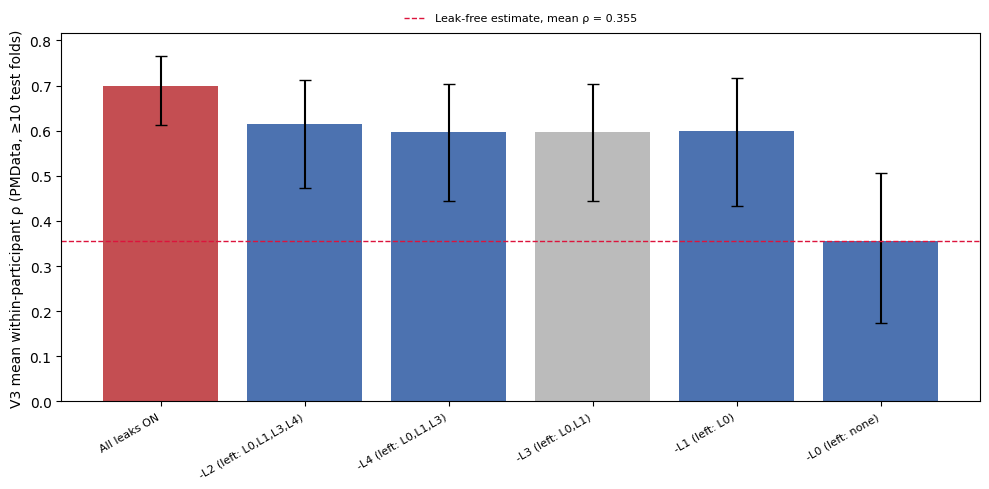

Grey bars = leak with no pathway into this arm (L3).
All v1.2 outputs -> /content/drive/MyDrive/ndi_project/results_v1.2


In [24]:
# V12-8 Figure 4 (no figure number in the image; title goes in the caption)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5))
colours = ["#C44E52"] + ["#BBBBBB" if r.get("inert") else "#4C72B0" for r in cum_rows[1:]]
x = np.arange(len(cum))
ax.bar(x, cum["v3_mean_rho"], color=colours)
ax.errorbar(x, cum["v3_mean_rho"],
            yerr=[cum["v3_mean_rho"] - cum["v3_ci95_lo"], cum["v3_ci95_hi"] - cum["v3_mean_rho"]],
            fmt="none", ecolor="black", capsize=4)
ax.axhline(clean_mean, ls="--", lw=1, color="crimson", label=f"Leak-free estimate, mean ρ = {clean_mean:.3f}")
ax.set_xticks(x); ax.set_xticklabels(cum["state"], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("V3 mean within-participant ρ (PMData, ≥10 test folds)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=8); ax.set_ylim(0, max(0.8, float(cum["v3_ci95_hi"].max()) + 0.05))
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(RESULTS_V1_2_DIR, f"figure4_leak_waterfall.{ext}"), dpi=300)
plt.show()
print("Grey bars = leak with no pathway into this arm (L3).")
print("All v1.2 outputs ->", RESULTS_V1_2_DIR)

In [25]:
# Sensitivity row summary + Item 2 day arithmetic
_need = ["V1_2_CONFIG", "RESULTS_V1_2_DIR", "corr_self", "_boot", "prepare",
         "target_support", "purge_training_rows", "pmdata_participants"]
_miss = [g for g in _need if g not in globals()]
assert not _miss, f"Run V12-0 ... V12-7 first. Missing: {_miss}"

# --- (a) per-fold-target sensitivity row (memo Item 1: "report it as a sensitivity row only")
_sens_path = os.path.join(RESULTS_V1_2_DIR, "sensitivity_per_fold_target_per_participant.csv")
sens_df = pd.read_csv(_sens_path)
sens_df = sens_df[sens_df["n_folds"] >= V1_2_CONFIG["MIN_FOLDS"]].reset_index(drop=True)
sens_rows = []
for name, df_ in [("primary: causal fixed target", corr_self),
                  ("sensitivity: target rebuilt per fold", sens_df)]:
    row = dict(path=name, n=len(df_))
    for a in ["vsigned", "v3", "rawrf", "persz"]:
        row[f"mean_rho_{a}"] = float(df_[a].mean())
    for a, b, tag in [("v3", "rawrf", "v3_minus_rawrf"), ("v3", "persz", "v3_minus_persz")]:
        dd = (df_[a] - df_[b]).dropna().values
        lo, hi, _ = _boot(dd, np.mean, 0.95)
        row[f"delta_{tag}"] = float(dd.mean())
        row[f"delta_{tag}_ci95_lo"], row[f"delta_{tag}_ci95_hi"] = lo, hi
    sens_rows.append(row)
sens_summary = pd.DataFrame(sens_rows)
sens_summary.to_csv(os.path.join(RESULTS_V1_2_DIR, "sensitivity_per_fold_target_summary.csv"), index=False)
print(sens_summary.round(4).T.to_string(header=False))

# --- (b) Item 2: day arithmetic for the first test fold, printed from the code itself
_p0 = pmdata_participants[0]
_n0 = len(_p0["days_df"]); _t0 = min(10, max(5, _n0 // 3)); _g = V1_2_CONFIG["EMBARGO_G"]
_te0 = _t0 + _g                                   # first test row (0-based), as in ndi.blocked_tscv
_tr0 = np.arange(0, _te0 - _g)                    # training rows of that fold
lines = [f"Participant {_p0['pid']}: n = {_n0} days, T0 = {_t0}, g = {_g}, k = {V1_2_CONFIG['SMOOTH_K']}",
         f"First test fold: training rows {_tr0.min()}..{_tr0.max()} (0-based), test row {_te0}",
         "Row s holds the features of calendar day s (T, I on day s; F from days <= s)."]
for al in ("trailing_v1", "forward"):
    sup_te = sorted(target_support(_te0, al, _n0))
    sup_last = sorted(target_support(int(_tr0.max()), al, _n0))
    clash = sorted(set(sup_te) & set(_tr0.tolist()))
    kept, n_drop = purge_training_rows(_tr0, np.array([_te0]), al, _n0)
    lines += [f"[{al}]",
              f"  test target y[{_te0}] averages the index over days {sup_te[0]}..{sup_te[-1]}",
              f"  last training row {int(_tr0.max())}: its target averages days {sup_last[0]}..{sup_last[-1]}",
              f"  training days inside the test-target window: {clash if clash else 'none'}",
              f"  last training target window touches the test day: {_te0 in sup_last}",
              f"  purge drops {n_drop} training row(s); last training row kept = {int(kept.max())}"
              f"  -> effective gap = {_te0 - int(kept.max()) - 1} days"]
# are consecutive rows consecutive calendar days? (a gap makes "the previous 7 rows" longer than a week)
_gaps = {}
for _p in pmdata_participants:
    _d = _p.get("days_df")
    if _d is not None and "date" in _d.columns:
        _dd = pd.to_datetime(_d["date"], errors="coerce").diff().dt.days.dropna()
        _gaps[_p["pid"]] = int((_dd != 1).sum())
lines.append("Rows that do not follow the previous row by exactly one calendar day, per participant: "
             + (str(_gaps) if _gaps else "no 'date' column found -- check by hand"))
lines.append(f"Alignment used for every v1.2 number in this run: {V1_2_CONFIG['TARGET_ALIGNMENT']}")
print("\n".join(lines))
with open(os.path.join(RESULTS_V1_2_DIR, "item2_day_arithmetic.txt"), "w") as f:
    f.write("\n".join(lines) + "\n")

path                          primary: causal fixed target  sensitivity: target rebuilt per fold
n                                                       15                                    15
mean_rho_vsigned                                    0.3132                                 0.386
mean_rho_v3                                         0.3547                                0.4058
mean_rho_rawrf                                      0.2576                                0.3428
mean_rho_persz                                      0.1846                                0.2564
delta_v3_minus_rawrf                                0.0972                                 0.063
delta_v3_minus_rawrf_ci95_lo                       -0.0169                               -0.0398
delta_v3_minus_rawrf_ci95_hi                        0.2032                                0.2726
delta_v3_minus_persz                                0.1701                                0.1494
delta_v3_minus_persz_ci95_lo  

In [26]:
# Independent recomputation of the corrected clean endpoint (no run_arms, no cache)
# Written from the memo's definitions only. Two separate checks per participant:
#   (i)  the causal target, rebuilt here from scratch, equals the V12 target (to 1e-12);
#   (ii) an independent fold loop (own purge rule, own feature construction, own fits),
#        run on the V12 target array, reproduces corrected Table 1 (to 1e-9).
# The fold loop uses nothing from the V12 runner: no run_arms, fold_features,
# causal_channels, purge_training_rows, or cache. build_target is called once per
# participant, only to obtain the V12 target array that (i) compares against.
# (iii) optional: the same loop on the rebuilt target. The two targets differ only in the
#        last floating-point bit, so any change in rho here is numerical sensitivity of the
#        random forests, not a logic difference. Reported, never asserted.
# Valid for TARGET_ALIGNMENT = "trailing_v1". Colab: about 40 s per participant, doubled by (iii).
X2_PARTICIPANTS = None      # None = all; or e.g. ["p01", "p08", "p16"] for a quick pass
X2_SENSITIVITY = True       # run part (iii)

def _x2_fill(X, rows):
    """NaN -> column median over `rows` (all-NaN column -> 0.0)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        med = np.nanmedian(X[rows], axis=0)
    med = np.where(np.isfinite(med), med, 0.0)
    return np.where(np.isnan(X), med, X)

def _x2_inputs(p, participants, feat_names):
    d0 = p["days_df"].copy().reset_index(drop=True); n = len(d0)
    Xn = np.column_stack([pd.to_numeric(d0[c], errors="coerce").values if c in d0.columns
                          else np.zeros(n) for c in feat_names]).astype(float)
    pm, pmad, _ = _compute_population_volatility_norm(participants, p["pid"], feat_names, False)
    return d0, n, Xn, pm, pmad, min(10, max(5, n // 3))

def x2_target(p, participants, feat_names, k, lam, burn):
    """Causal trailing target: day d of the index uses rows [0, max(d+1, B)) only."""
    d0, n, Xn, pm, pmad, t0 = _x2_inputs(p, participants, feat_names)
    B = min(burn, t0)                                   # burn-in lies inside the first training window
    Xc = Xn.copy()
    for d in range(n):                                  # causal imputation
        if np.isnan(Xn[d]).any():
            L = min(max(d + 1, B), n)
            Xc[d] = _x2_fill(Xn[:L], np.arange(L))[d]
    idx = np.full(n, np.nan)
    for d in range(n):
        L = min(max(d + 1, B), n); ones = np.ones(L, bool)
        T = ndi.compute_T_v3(Xc[:L], ones)[d]
        mi, ii = ndi.compute_quality_signal(d0.iloc[:L].reset_index(drop=True), feat_names, ones)
        I = ndi.compute_I_v3(mi, ii)[d]
        F = ndi.compute_F_v3(Xc[:L], feat_names, ones, pm, pmad)[d]
        idx[d] = lam[2] * F - lam[0] * T + lam[1] * I   # NDI = lF*F - lT*T + lI*I, lam = (lT, lI, lF)
    return np.array([np.nan if s == 0 else idx[max(0, s - k):s].mean() for s in range(n)]), B

def x2_fold_rho(p, participants, feat_names, y, k, g):
    """Test row ts; training rows 0..ts-g-1 minus the purged ones. Trailing alignment: the test
    target uses days ts-k..ts-1, so every training row t >= ts-k is inside that window or has a
    target window touching it. Features: training-fold statistics, truncated at the test day."""
    d0, n, Xn, pm, pmad, t0 = _x2_inputs(p, participants, feat_names)
    yt, p_v3, p_raw = [], [], []
    for ts in range(t0 + g, n):
        tr = np.arange(0, min(ts - g, ts - k))
        L = ts + 1
        tm = np.zeros(L, bool); tm[tr] = True
        X = _x2_fill(Xn[:L], tm)
        T = ndi.compute_T_v3(X, tm)
        mi, ii = ndi.compute_quality_signal(d0.iloc[:L].reset_index(drop=True), feat_names, tm)
        I = ndi.compute_I_v3(mi, ii)
        F = ndi.compute_F_v3(X, feat_names, tm, pm, pmad)
        X3 = np.column_stack([T, I, F])
        trv = tr[np.isfinite(y[tr])]
        if len(trv) < 5 or not np.isfinite(y[ts]):
            continue
        m = ndi.rf_factory(); m.fit(X3[trv], y[trv]); p_v3.append(float(m.predict(X3[[ts]])[0]))
        m = ndi.rf_factory(); m.fit(X[trv], y[trv]);  p_raw.append(float(m.predict(X[[ts]])[0]))
        yt.append(y[ts])
    return len(yt), spearmanr(yt, p_v3)[0], spearmanr(yt, p_raw)[0]

assert V1_2_CONFIG["TARGET_ALIGNMENT"] == "trailing_v1", "X-2 is written for the trailing alignment only"
_k, _g, _lam = V1_2_CONFIG["SMOOTH_K"], V1_2_CONFIG["EMBARGO_G"], tuple(V1_2_CONFIG["FIXED_LAMBDA"])
_t = time.time(); x2_rows = []
for p in pmdata_participants:
    if p.get("days_df") is None or p["pid"] not in set(corr_self["pid"]):
        continue
    if X2_PARTICIPANTS is not None and p["pid"] not in X2_PARTICIPANTS:
        continue
    y_ind, B = x2_target(p, pmdata_participants, PMDATA_FEATURE_NAMES, _k, _lam,
                         V1_2_CONFIG["TARGET_BURN_IN_DAYS"])
    y_v12, _ = build_target(prepare(p, PMDATA_FEATURE_NAMES, False, pmdata_participants),
                            "self", "causal", "trailing_v1", _lam, B)
    assert (np.isnan(y_ind) == np.isnan(y_v12)).all(), f"{p['pid']}: target NaN pattern differs"
    nf, r3, rr = x2_fold_rho(p, pmdata_participants, PMDATA_FEATURE_NAMES, y_v12, _k, _g)
    row = dict(pid=p["pid"], target_max_abs_diff=float(np.nanmax(np.abs(y_ind - y_v12))),
               n_folds_indep=nf, v3_indep=r3, rawrf_indep=rr)
    if X2_SENSITIVITY:
        _, s3, sr = x2_fold_rho(p, pmdata_participants, PMDATA_FEATURE_NAMES, y_ind, _k, _g)
        row.update(v3_on_rebuilt_target=s3, rawrf_on_rebuilt_target=sr)
    x2_rows.append(row)
x2 = pd.DataFrame(x2_rows).merge(corr_self[["pid", "n_folds", "v3", "rawrf"]], on="pid")
x2 = x2.rename(columns={"n_folds": "n_folds_v12", "v3": "v3_v12", "rawrf": "rawrf_v12"})
x2["abs_diff_v3"] = (x2["v3_indep"] - x2["v3_v12"]).abs()
x2["abs_diff_rawrf"] = (x2["rawrf_indep"] - x2["rawrf_v12"]).abs()
x2.to_csv(os.path.join(RESULTS_V1_2_DIR, "independent_check_clean_endpoint.csv"), index=False)
print(x2.round(6).to_string(index=False))
_worst = float(max(x2["abs_diff_v3"].max(), x2["abs_diff_rawrf"].max()))
print(f"\n{len(x2)} participants, {time.time() - _t:.0f}s")
print(f"(i)  target rebuilt from scratch vs V12 target: max |diff| = {x2['target_max_abs_diff'].max():.1e}")
print(f"(ii) independent fold loop vs corrected Table 1: max |diff| = {_worst:.1e}")
assert x2["target_max_abs_diff"].max() < 1e-12, "causal target does NOT match -- STOP and report"
assert (x2["n_folds_indep"] == x2["n_folds_v12"]).all(), "fold counts differ -- STOP and report"
assert _worst < 1e-9, "independent fold loop does NOT match corrected Table 1 -- STOP and report"
print("INDEPENDENT CHECK PASSED: corrected Table 1 (V3, raw-RF) reproduced without the V12 runner")
if X2_SENSITIVITY:
    d3 = x2["v3_on_rebuilt_target"] - x2["v3_v12"]; dr = x2["rawrf_on_rebuilt_target"] - x2["rawrf_v12"]
    sens_note = (f"(iii) NUMERICAL SENSITIVITY: a last-bit change in the target (max {x2['target_max_abs_diff'].max():.1e}) "
                 f"moves per-participant rho by up to {max(d3.abs().max(), dr.abs().max()):.4f}; "
                 f"mean rho moves by {d3.mean():+.4f} (V3) and {dr.mean():+.4f} (raw-RF); "
                 f"V3 - raw-RF moves by {(d3 - dr).mean():+.4f}.")
    print(sens_note)
    with open(os.path.join(RESULTS_V1_2_DIR, "independent_check_notes.txt"), "w") as f:
        f.write(sens_note + "\n")

pid  target_max_abs_diff  n_folds_indep  v3_indep  rawrf_indep  v3_on_rebuilt_target  rawrf_on_rebuilt_target  n_folds_v12    v3_v12  rawrf_v12  abs_diff_v3  abs_diff_rawrf
p01                  0.0            136  0.120643     0.444249              0.121540                 0.445174          136  0.120643   0.444249          0.0             0.0
p02                  0.0            136  0.339531    -0.245298              0.340136                -0.244497          136  0.339531  -0.245298          0.0             0.0
p03                  0.0            140  0.395491     0.318974              0.392797                 0.317124          140  0.395491   0.318974          0.0             0.0
p04                  0.0            137  0.664028     0.556490              0.663902                 0.554866          137  0.664028   0.556490          0.0             0.0
p05                  0.0            139  0.274467     0.057576              0.274552                 0.058752          139  0.274467   

In [12]:
# X-3 setup: restores only what the Task 4 benchmark needs after a runtime restart.
# Does NOT re-run V12-0, so config_v1_2_correction.json and provenance.json stay untouched.
import os, json, time, datetime, warnings
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge

_need = ["ndi", "RESULTS_DIR", "pmdata_participants", "_compute_population_volatility_norm"]
_miss = [g for g in _need if g not in globals()]
assert not _miss, f"Run CELL 1.0, CELL 2, CELL 5, CELL 6 and CELL 14.4 first. Missing: {_miss}"

RESULTS_V1_2_DIR = os.path.join(os.path.dirname(RESULTS_DIR), "results_v1.2")
with open(os.path.join(RESULTS_V1_2_DIR, "config_v1_2_correction.json")) as f:
    V1_2_CONFIG = json.load(f)
K, G = V1_2_CONFIG["SMOOTH_K"], V1_2_CONFIG["EMBARGO_G"]
ARMS = ["vsigned", "v3", "rawrf", "persz"]
print("Loaded", V1_2_CONFIG["VERSION"], "| k =", K, "| g =", G, "|", len(pmdata_participants), "PMData participants")

Loaded v1.2-correction | k = 7 | g = 6 | 15 PMData participants


In [17]:
# Task 4 single-cohort wall-time benchmark (corrected path)
# Times ONE simulated cohort: 4 arms x all folds, features built the v1.2 way
# (training-fold statistics, truncated at the test day). Timing only -- no result
# from this cell is a Task 4 result.
#   * Generator: generate_arm2_participant, unchanged, SNR 1.0.
#   * 15 participants, lengths resampled (seeded) from the PMData length distribution.
#   * Outcome: C0 null, Y[t+1] ~ N(0,1) independent of everything; row t is scored
#     against Y[t+1] (genuinely next-day). The outcome model does not change the cost.
#   * Folds: same structure as ndi.blocked_tscv (T0 rule, g = 6, fold size 1), enumerated
#     by index arithmetic and checked against ndi.blocked_tscv for one participant.
_need = ["generate_arm2_participant", "prepare", "fold_features", "_zscore_ridge",
         "pmdata_participants", "V1_2_CONFIG", "RESULTS_V1_2_DIR"]
_miss = [g for g in _need if g not in globals()]
assert not _miss, f"Run the Arm 2 generator cell (C2.0, C2.1) and V12-0 ... V12-2 first. Missing: {_miss}"

T4B_SNR, T4B_N, T4B_SEED = 1.0, 15, int(V1_2_CONFIG["BOOTSTRAP_SEED"])
T4B_FEATS = ["sim_feature"]
T4B_CELLS = 1 + 4 + 4            # C0 + C1 x 4 beta levels + C2 x 4 beta levels
_rng = np.random.default_rng(T4B_SEED)
_pm_lengths = np.array([len(p["days_df"]) for p in pmdata_participants if p.get("days_df") is not None])
_lengths = _rng.choice(_pm_lengths, size=T4B_N, replace=True)
bench_cohort = [generate_arm2_participant(f"t4bench_{i:02d}", int(L), T4B_SNR, _rng)
                for i, L in enumerate(_lengths)]
for p in bench_cohort:                                   # C0 outcome: row t scored against Y[t+1]
    Y = _rng.normal(0, 1, len(p["days_df"]))
    p["y_next"] = np.append(Y[1:], np.nan)

def _t4_folds(n, g):
    t0 = min(10, max(5, n // 3))
    return [(np.arange(0, ts - g), np.array([ts])) for ts in range(t0 + g, n) if ts - g >= 5]

# fold enumeration must equal ndi.blocked_tscv's (checked on the first participant; also times it)
_pr = prepare(bench_cohort[0], T4B_FEATS, False, bench_cohort)
_t = time.perf_counter()
_ref = ndi.blocked_tscv(_pr["X_ws"], np.zeros(_pr["n"]), ndi.rf_factory, T0=_pr["t0"],
                        g=V1_2_CONFIG["EMBARGO_G"], return_folds=True)["folds"]
t_blocked_tscv_one = time.perf_counter() - _t
_mine = _t4_folds(_pr["n"], V1_2_CONFIG["EMBARGO_G"])
assert len(_ref) == len(_mine) and all(list(a) == list(c) and list(b) == list(d)
                                       for (a, b), (c, d) in zip(_ref, _mine)), "fold enumeration differs"

t_feat = t_fit = 0.0; n_folds_total = 0; bench_rows = []
t_all = time.perf_counter()
for p in bench_cohort:
    pr = prepare(p, T4B_FEATS, False, bench_cohort); y = p["y_next"]
    preds = {a: [] for a in ARMS}; yt = []
    for tr, te in _t4_folds(pr["n"], V1_2_CONFIG["EMBARGO_G"]):
        _a = time.perf_counter()
        Xf, X3, XVS = fold_features(pr, tr, te, False, True)
        _b = time.perf_counter()
        trv = tr[np.isfinite(y[tr])]; tev = te[np.isfinite(y[te])]
        if len(trv) < 5 or len(tev) < 1:
            t_feat += _b - _a; continue
        m = ndi.rf_factory(); m.fit(XVS[trv], y[trv]); preds["vsigned"].append(float(m.predict(XVS[tev])[0]))
        m = ndi.rf_factory(); m.fit(X3[trv], y[trv]);  preds["v3"].append(float(m.predict(X3[tev])[0]))
        m = ndi.rf_factory(); m.fit(Xf[trv], y[trv]);  preds["rawrf"].append(float(m.predict(Xf[tev])[0]))
        preds["persz"].append(float(_zscore_ridge(Xf[trv], y[trv], Xf[tev])[0]))
        yt.append(float(y[tev][0]))
        _c = time.perf_counter(); t_feat += _b - _a; t_fit += _c - _b; n_folds_total += 1
    bench_rows.append(dict(pid=p["pid"], n_days=pr["n"], n_folds=len(yt),
                           **{a: spearmanr(yt, preds[a])[0] for a in ARMS}))
t_cohort = time.perf_counter() - t_all
for p in bench_cohort:                                   # leave no benchmark entries in the V12 cache
    _PREP_CACHE.pop((p["pid"], tuple(T4B_FEATS), False), None)

bench = dict(
    snr=T4B_SNR, n_participants=T4B_N, lengths=[int(x) for x in _lengths],
    total_folds=int(n_folds_total), arms=len(ARMS),
    wall_seconds_one_cohort=round(t_cohort, 1),
    seconds_feature_building=round(t_feat, 1), seconds_model_fitting=round(t_fit, 1),
    seconds_per_fold=round(t_cohort / max(n_folds_total, 1), 4),
    extra_seconds_per_cohort_if_folds_come_from_blocked_tscv=round(t_blocked_tscv_one * T4B_N, 1),
    cells=T4B_CELLS,
    projected_hours_100_replicates=round(t_cohort * T4B_CELLS * 100 / 3600, 1),
    projected_hours_200_replicates=round(t_cohort * T4B_CELLS * 200 / 3600, 1),
    cpu_count=os.cpu_count(), measured_at=datetime.datetime.now().isoformat(timespec="seconds"),
    note="single process; C0 outcome; timing only, not a Task 4 result")
with open(os.path.join(RESULTS_V1_2_DIR, "task4_wall_time_benchmark.json"), "w") as f:
    json.dump(bench, f, indent=2)
pd.DataFrame(bench_rows).to_csv(os.path.join(RESULTS_V1_2_DIR, "task4_benchmark_cohort_per_participant.csv"),
                                index=False)
print(json.dumps(bench, indent=2))
print(f"\nTASK 4 BENCHMARK: one cohort = {t_cohort / 60:.1f} min "
      f"({n_folds_total} folds x {len(ARMS)} arms). "
      f"Full design ({T4B_CELLS} cells): {bench['projected_hours_100_replicates']} h at 100 replicates, "
      f"{bench['projected_hours_200_replicates']} h at 200, on one process with {os.cpu_count()} CPUs visible.")

{
  "snr": 1.0,
  "n_participants": 15,
  "lengths": [
    152,
    156,
    149,
    149,
    149,
    142,
    152,
    152,
    153,
    152,
    144,
    152,
    156,
    156,
    152
  ],
  "total_folds": 2011,
  "arms": 4,
  "wall_seconds_one_cohort": 926.1,
  "seconds_feature_building": 34.7,
  "seconds_model_fitting": 891.2,
  "seconds_per_fold": 0.4605,
  "extra_seconds_per_cohort_if_folds_come_from_blocked_tscv": 313.8,
  "cells": 9,
  "projected_hours_100_replicates": 231.5,
  "projected_hours_200_replicates": 463.0,
  "cpu_count": 2,
  "measured_at": "2026-10-07T16:03:21",
  "note": "single process; C0 outcome; timing only, not a Task 4 result"
}

TASK 4 BENCHMARK: one cohort = 15.4 min (2011 folds x 4 arms). Full design (9 cells): 231.5 h at 100 replicates, 463.0 h at 200, on one process with 2 CPUs visible.


In [19]:
# check: files present, v1 regeneration
# Reads saved files only
import os, json
import numpy as np, pandas as pd

_BASE = os.path.dirname(RESULTS_DIR) if "RESULTS_DIR" in globals() else "/content/drive/MyDrive/ndi_project"
_V12 = os.path.join(_BASE, "results_v1.2")
_FROZEN = os.path.join(_BASE, "results_final_v1_frozen_backup")
_REGEN = os.path.join(_BASE, "results_regen_scratch")
assert os.path.isdir(_V12), f"{_V12} not found -- run CELL 1.0 first so Drive is mounted"
report = []
def say(s=""):
    print(s); report.append(s)

# --- 1. every v1.2 output the two memos ask for
_expected = ["config_v1_2_correction.json", "provenance.json",
             "table1_corrected_self_target_per_participant.csv", "raw_target_corrected_per_participant.csv",
             "v1_vs_corrected.csv", "fold_log_self_target.csv", "fold_log_raw_target.csv",
             "sensitivity_per_fold_target_per_participant.csv", "sensitivity_per_fold_target_summary.csv",
             "task1_table2_bounded_null.csv", "task1_absolute_rho_both_targets.csv", "task1_notes.txt",
             "task2_waterfall_cumulative.csv", "task2_one_at_a_time.csv", "task2_table4_inflation_column.csv",
             "figure4_leak_waterfall.png", "figure4_leak_waterfall.pdf",
             "item2_day_arithmetic.txt", "independent_check_clean_endpoint.csv", "independent_check_notes.txt",
             "task4_wall_time_benchmark.json", "task4_benchmark_cohort_per_participant.csv"]
say("1. FILES in results_v1.2")
_missing = [f for f in _expected if not os.path.isfile(os.path.join(_V12, f))]
say(f"   {len(_expected) - len(_missing)} of {len(_expected)} present" + (f"; MISSING: {_missing}" if _missing else ""))

# --- 2. provenance
say("2. PROVENANCE")
_prov = json.load(open(os.path.join(_V12, "provenance.json")))
say(f"   run_started {_prov.get('run_started')} | head_commit {_prov.get('head_commit')} | "
    f"tag commit {_prov.get('tag_v1_2_correction_commit')}")
if not _prov.get("tag_v1_2_correction_commit"):
    say("   NOT TAGGED at run time -- state this in the deviation note; do not edit provenance.json by hand")

# --- 3. v1 regeneration check, run LAST (memo ground rule): frozen v1 archive vs this revision's v1 re-run
say("3. V1 REGENERATION (frozen archive vs the v1 re-run made alongside v1.2)")
_ARMS = ["vsigned", "v3", "rawrf", "persz"]
_LAB = {"vsigned": "V-signed", "v3": "V3", "rawrf": "Raw-feature RF", "persz": "Personalised Z"}
_fz = os.path.join(_FROZEN, "primary_pmdata_rho.csv"); _rg = os.path.join(_REGEN, "primary_pmdata_rho.csv")
regen_ok = None
if os.path.isfile(_fz):
    fz = pd.read_csv(_fz)
    vc = pd.read_csv(os.path.join(_V12, "v1_vs_corrected.csv"))
    vc = vc[(vc["target"] == "self-derived") & vc["quantity"].str.startswith("mean rho")].set_index("quantity")["v1"]
    d_mean = max(abs(float(fz[a].mean()) - float(vc[f"mean rho {_LAB[a]}"])) for a in _ARMS)
    say(f"   archived v1 arm means vs the v1 values used in v1_vs_corrected.csv: max |diff| = {d_mean:.1e}")
    regen_ok = d_mean < 1e-9
    if os.path.isfile(_rg):
        m = fz.merge(pd.read_csv(_rg), on="pid", suffixes=("_frozen", "_regen"))
        d_pp = max(float((m[f"{a}_frozen"] - m[f"{a}_regen"]).abs().max()) for a in _ARMS)
        say(f"   per participant, {len(m)} of {len(fz)} matched: max |diff| = {d_pp:.1e}")
        regen_ok = regen_ok and d_pp < 1e-9 and len(m) == len(fz)
    else:
        say(f"   (no {os.path.basename(_REGEN)}/primary_pmdata_rho.csv -- per-participant comparison skipped)")
    _fq = os.path.join(_FROZEN, "raw_target_wilcoxon.csv"); _rq = os.path.join(_REGEN, "raw_target_wilcoxon.csv")
    if os.path.isfile(_fq) and os.path.isfile(_rq):
        a_, b_ = pd.read_csv(_fq), pd.read_csv(_rq)
        if {"comparison", "q"} <= set(a_.columns) & set(b_.columns):
            dq = float((a_.set_index("comparison")["q"] - b_.set_index("comparison")["q"]).abs().max())
            say(f"   raw-target Wilcoxon q-values: max |diff| = {dq:.1e}")
            regen_ok = regen_ok and dq < 1e-9
    say("   V1 REGENERATION CHECK " + ("PASSED" if regen_ok else "FAILED -- stop and report"))
else:
    say(f"   {_fz} not found -- cannot run; check the frozen-backup folder name")

# --- 4. replacement Table 2 and absolute-rho table in the memo's column layout
def _f(x, d=3):
    return "n/a" if pd.isna(x) else f"{x:.{d}f}"
def _flag(v, yes, no):
    s = str(v).strip().lower()
    return yes if s == "true" else no if s == "false" else "n/a"
t2 = pd.read_csv(os.path.join(_V12, "task1_table2_bounded_null.csv"), keep_default_na=False, na_values=[""])
for c in ["mean_delta_rho", "ci95_lo", "ci95_hi", "hl_median", "hl_ci95_lo", "hl_ci95_hi", "p", "q", "ci90_lo", "ci90_hi"]:
    t2[c] = pd.to_numeric(t2[c], errors="coerce")
table2_fmt = pd.DataFrame({
    "Comparison": t2["comparison"], "Target": t2["target"],
    "Mean delta rho [95% CI]": [f"{_f(m)} [{_f(l)}, {_f(h)}]" for m, l, h in zip(t2["mean_delta_rho"], t2["ci95_lo"], t2["ci95_hi"])],
    "HL median [95% CI]": [f"{_f(m)} [{_f(l)}, {_f(h)}]" for m, l, h in zip(t2["hl_median"], t2["hl_ci95_lo"], t2["hl_ci95_hi"])],
    "Wins/n": [f"{w}/{n}" for w, n in zip(t2["wins"], t2["n"])],
    "P": [_f(v) for v in t2["p"]], "q (BH)": [_f(v) for v in t2["q"]],
    "TOST (+/-0.10), 90% CI": [("n/a" if _flag(e, "y", "n") == "n/a" else
                               f"{_flag(e, 'equivalent', 'inconclusive')} [{_f(l)}, {_f(h)}]")
                              for e, l, h in zip(t2["tost_equivalent_at_SESOI"], t2["ci90_lo"], t2["ci90_hi"])],
    "Advantage >= 0.10 rejected": [_flag(v, "yes", "no") for v in t2["advantage_ge_SESOI_rejected"]],
    "Artifact excluded": [_flag(v, "yes", "no") for v in t2["artifact_excluded"]]})
table2_fmt.to_csv(os.path.join(_V12, "task1_table2_formatted.csv"), index=False)
ab = pd.read_csv(os.path.join(_V12, "task1_absolute_rho_both_targets.csv"))
abs_fmt = pd.DataFrame({"Arm": ab["arm"], "Target": ab["target"], "n": ab["n"],
                        "Mean rho [95% CI]": [f"{_f(m)} [{_f(l)}, {_f(h)}]" for m, l, h in zip(ab["mean_rho"], ab["ci95_lo"], ab["ci95_hi"])],
                        "P vs 0": [_f(v) for v in ab["p_vs_zero"]]})
abs_fmt.to_csv(os.path.join(_V12, "task1_absolute_rho_formatted.csv"), index=False)
say("4. MEMO-FORMAT TABLES written: task1_table2_formatted.csv, task1_absolute_rho_formatted.csv")
print(table2_fmt.to_string(index=False)); print(); print(abs_fmt.to_string(index=False))

with open(os.path.join(_V12, "handin_check.txt"), "w") as f:
    f.write("\n".join(report) + "\n")

1. FILES in results_v1.2
   22 of 22 present
2. PROVENANCE
   run_started 2026-10-07T07:47:18 | head_commit None | tag commit None
   NOT TAGGED at run time -- state this in the deviation note; do not edit provenance.json by hand
3. V1 REGENERATION (frozen archive vs the v1 re-run made alongside v1.2)
   archived v1 arm means vs the v1 values used in v1_vs_corrected.csv: max |diff| = 8.3e-17
   per participant, 15 of 15 matched: max |diff| = 0.0e+00
   raw-target Wilcoxon q-values: max |diff| = 0.0e+00
   V1 REGENERATION CHECK PASSED
4. MEMO-FORMAT TABLES written: task1_table2_formatted.csv, task1_absolute_rho_formatted.csv
        Comparison       Target Mean delta rho [95% CI]     HL median [95% CI] Wins/n     P q (BH)       TOST (+/-0.10), 90% CI Advantage >= 0.10 rejected Artifact excluded
      V3 vs raw-RF self-derived   0.097 [-0.017, 0.203]   0.108 [0.022, 0.198]  13/15 0.055  0.074                          n/a                        n/a               n/a
      V3 vs pers-Z sel

In [ ]:
# ================================================================
# CELL 14.11b  ITEM 2 -- SECONDARY TARGETS (a)/(c), all 4 arms
# FIX: target (c) is a self-referential sanity check -- only V-signed
# and V3 have their own index to self-predict. Raw-RF/Pers-Z have no
# such target (a raw feature matrix isn't an index), so they are
# excluded from target (c) here rather than silently tested against
# V-signed's NDI (the earlier bug).
# ================================================================
def run_v3_comparison_variant(participants, dataset_label, has_labels,
                               feat_names, v3_lambda, target="NDI"):
    rows = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values
        t0 = min(10, max(5, n // 3))

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        if target == "external":
            if not has_labels:
                y_full = pd.to_numeric(
                    df_raw.get("mood", pd.Series(np.nan, index=df_raw.index)),
                    errors="coerce").values
            else:
                continue  # DEPRESJON handled cross-participant in 14.11c

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=t0, return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue
        if not folds:
            continue

        preds = {"vsigned": [], "v3": [], "rawrf": [], "persz": []}
        y_true_all = {"vsigned": [], "v3": [], "rawrf": [], "persz": []}

        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            train_mask = np.zeros(n, dtype=bool)
            train_mask[tr_idx] = True

            vs_neutro = ndi.build_neutrosophic_features(X_raw, feat_names, train_mask=train_mask)
            X_vs = vs_neutro[["Depression_T", "Depression_I", "Depression_F"]].fillna(0).values

            missing_rate, instability = ndi.compute_quality_signal(df_raw_orig, feat_names, train_mask)
            T_v3 = ndi.compute_T_v3(X_raw, train_mask)
            I_v3 = ndi.compute_I_v3(missing_rate, instability)
            F_v3 = ndi.compute_F_v3(X_raw, feat_names, train_mask, pop_vol_median, pop_vol_mad)
            X_v3 = np.column_stack([T_v3, I_v3, F_v3])

            if target == "NDI":
                # self-referential sanity check -- only vsigned/v3 have a target
                y_fold_v3 = ndi.compute_ndi_v3_primary(T_v3, I_v3, F_v3, lambda_vec=v3_lambda)
                for arm_name, y_fold, X_fold in [
                    ("vsigned", vs_neutro["NDI"].values, X_vs),
                    ("v3",      y_fold_v3,               X_v3),
                ]:
                    tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
                    te_valid = te_idx[np.isfinite(y_fold[te_idx])]
                    if len(tr_valid) < 5 or len(te_valid) < 1:
                        continue
                    try:
                        rf = ndi.rf_factory(); rf.fit(X_fold[tr_valid], y_fold[tr_valid])
                        pred = rf.predict(X_fold[te_valid])
                    except Exception:
                        continue
                    preds[arm_name].extend(pred.tolist())
                    y_true_all[arm_name].extend(y_fold[te_valid].tolist())
                continue

            # target == "external"
            y_fold = y_full
            tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
            te_valid = te_idx[np.isfinite(y_fold[te_idx])]
            if len(tr_valid) < 5 or len(te_valid) < 1:
                continue
            try:
                rf_vs = ndi.rf_factory(); rf_vs.fit(X_vs[tr_valid], y_fold[tr_valid])
                rf_v3 = ndi.rf_factory(); rf_v3.fit(X_v3[tr_valid], y_fold[tr_valid])
                rf_raw = ndi.rf_factory(); rf_raw.fit(X_raw[tr_valid], y_fold[tr_valid])
                pred_vs  = rf_vs.predict(X_vs[te_valid])
                pred_v3  = rf_v3.predict(X_v3[te_valid])
                pred_raw = rf_raw.predict(X_raw[te_valid])
                pred_z   = _zscore_ridge_predict(X_raw[tr_valid], y_fold[tr_valid], X_raw[te_valid])
            except Exception:
                continue
            for arm_name, pred in [("vsigned", pred_vs), ("v3", pred_v3),
                                    ("rawrf", pred_raw), ("persz", pred_z)]:
                preds[arm_name].extend(pred.tolist())
                y_true_all[arm_name].extend(y_fold[te_valid].tolist())

        active_arms = ["vsigned", "v3"] if target == "NDI" else ["vsigned", "v3", "rawrf", "persz"]
        row = dict(pid=p["pid"])
        ok = False
        for arm in active_arms:
            yt = np.array(y_true_all[arm]); pr = np.array(preds[arm])
            if len(yt) < 3:
                row[arm] = np.nan
                continue
            mask = np.isfinite(yt) & np.isfinite(pr)
            row[arm] = spearmanr(yt[mask], pr[mask])[0] if mask.sum() >= 3 else np.nan
            ok = ok or mask.sum() >= 3
        for arm in ["vsigned", "v3", "rawrf", "persz"]:
            if arm not in row:
                row[arm] = np.nan
        if ok:
            rows.append(row)
    return pd.DataFrame(rows)

secondary_variant_results = {}
for target_variant, label in [("NDI", "(c) sanity -- vsigned/v3 only"), ("external", "(a) clinical")]:
    for dataset_label, participants, has_labels, feat_names in [
        ("PMData", pmdata_participants, False, PMDATA_FEATURE_NAMES),
        ("DEPRESJON", depresjon_participants, True, FEAT_NAMES),
    ]:
        if target_variant == "external" and has_labels:
            continue  # DEPRESJON (a): cross-participant only, see 14.11c
        df_v = run_v3_comparison_variant(participants, dataset_label, has_labels,
                                          feat_names, V3_BEST_LAMBDA, target=target_variant)
        secondary_variant_results[(dataset_label, target_variant)] = df_v
        print(f"\n--- {dataset_label} target {label} ---")
        arms_to_show = ["vsigned", "v3"] if target_variant == "NDI" else ["vsigned", "v3", "rawrf", "persz"]
        for arm, lbl in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
            if arm not in arms_to_show:
                print(f"  {lbl:<12} n/a -- no self-referential target")
                continue
            vals = df_v[arm].dropna() if not df_v.empty else pd.Series(dtype=float)
            print(f"  {lbl:<12} n={len(vals):>3}  mean rho={vals.mean() if len(vals) else float('nan'):.4f}")


--- PMData target (c) sanity -- vsigned/v3 only ---
  V-signed     n= 15  mean rho=0.9371
  V3           n= 15  mean rho=0.8887
  Raw-RF       n/a -- no self-referential target
  Pers-Z       n/a -- no self-referential target

--- DEPRESJON target (c) sanity -- vsigned/v3 only ---
  V-signed     n= 54  mean rho=0.7106
  V3           n= 54  mean rho=0.4049
  Raw-RF       n/a -- no self-referential target
  Pers-Z       n/a -- no self-referential target

--- PMData target (a) clinical ---
  V-signed     n=  0  mean rho=nan
  V3           n=  0  mean rho=nan
  Raw-RF       n=  0  mean rho=nan
  Pers-Z       n=  0  mean rho=nan


In [ ]:
# ================================================================
# CELL 14.11c  ITEM 2 -- DEPRESJON target (a) cross-participant +
# AUROC, all 4 arms (mirrors Cell 9's established pattern for
# V-signed, extended to V3/raw-RF/persZ)
# ================================================================
from scipy.stats import mannwhitneyu

def per_participant_summary_score(p, feat_names, arm, v3_lambda, pop_vol_median, pop_vol_mad):
    df_raw_orig = p["days_df"].copy().reset_index(drop=True)
    df_raw = df_raw_orig.copy()
    for col in feat_names:
        if col in df_raw.columns:
            df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce").fillna(df_raw[col].median())
        else:
            df_raw[col] = 0.0
    X_raw = df_raw[feat_names].values
    n = len(X_raw)
    tm = np.ones(n, dtype=bool)
    if arm == "vsigned":
        neutro = ndi.build_neutrosophic_features(X_raw, feat_names, train_mask=tm)
        return float(neutro["NDI"].mean())
    if arm == "v3":
        T = ndi.compute_T_v3(X_raw, tm)
        mr, inst = ndi.compute_quality_signal(df_raw_orig, feat_names, tm)
        I = ndi.compute_I_v3(mr, inst)
        F = ndi.compute_F_v3(X_raw, feat_names, tm, pop_vol_median, pop_vol_mad)
        return float(ndi.compute_ndi_v3_primary(T, I, F, lambda_vec=v3_lambda).mean())
    if arm == "rawrf":
        return float(np.nanmean(X_raw))
    if arm == "persz":
        mu, sg = X_raw.mean(0), X_raw.std(0) + 1e-8
        return float(np.nanmean((X_raw - mu) / sg))

rows = []
for p in depresjon_participants:
    pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
        depresjon_participants, p["pid"], FEAT_NAMES, True)
    row = dict(pid=p["pid"], madrs=p.get("madrs_mean", np.nan),
               is_depressed=p.get("is_depressed", np.nan))
    for arm in ["vsigned", "v3", "rawrf", "persz"]:
        row[arm] = per_participant_summary_score(
            p, FEAT_NAMES, arm, V3_BEST_LAMBDA, pop_vol_median, pop_vol_mad)
    rows.append(row)
summary_df = pd.DataFrame(rows)

print("--- DEPRESJON target (a): cross-participant NDI vs MADRS ---")
cross_a_results = {}
for arm, label in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
    d = summary_df[["madrs", arm]].dropna()
    if len(d) >= 3:
        r, pv = spearmanr(d["madrs"], d[arm])
        print(f"  {label:<12} n={len(d)}  Spearman={r:.4f}  p={pv:.4f}")
        cross_a_results[arm] = dict(rho=r, p=pv, n=len(d))

print("\n--- DEPRESJON AUROC: each arm's score vs binary group label ---")
auroc_results = {}
for arm, label in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
    d = summary_df[["is_depressed", arm]].dropna()
    if d["is_depressed"].nunique() < 2 or len(d) < 3:
        print(f"  {label:<12} skipped (need both groups present)")
        continue
    y_bin = d["is_depressed"].values.astype(int)
    scores = d[arm].values
    res = ndi.auroc_youden(scores, y_bin)
    pos, neg = scores[y_bin == 1], scores[y_bin == 0]
    _, p_auroc = mannwhitneyu(pos, neg, alternative="two-sided")
    print(f"  {label:<12} AUROC={res['auroc']:.4f}  95%CI=[{res['ci'][0]:.3f},{res['ci'][1]:.3f}]  p={p_auroc:.4f}")
    auroc_results[arm] = dict(auroc=res["auroc"], p=p_auroc, n=len(d))

--- DEPRESJON target (a): cross-participant NDI vs MADRS ---
  V-signed     n=23  Spearman=-0.0060  p=0.9785
  V3           n=23  Spearman=0.1117  p=0.6117
  Raw-RF       n=23  Spearman=0.1818  p=0.4065
  Pers-Z       n=23  Spearman=0.3911  p=0.0650

--- DEPRESJON AUROC: each arm's score vs binary group label ---
  V-signed     AUROC=0.4497  95%CI=[0.281,0.609]  p=0.5334
  V3           AUROC=0.6413  95%CI=[0.495,0.789]  p=0.0774
  Raw-RF       AUROC=0.3342  95%CI=[0.190,0.485]  p=0.0382
  Pers-Z       AUROC=0.5007  95%CI=[0.343,0.659]  p=1.0000


In [ ]:
# ================================================================
# CELL 14.11d  ITEM 2 -- BH CORRECTION ACROSS ALL SECONDARY TESTS
# ================================================================
secondary_rows = []
from scipy.stats import wilcoxon

for arm, label in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
    vals = depresjon_comparison[arm].dropna()
    if len(vals) >= 5:
        try:
            _, pv = wilcoxon(vals)
        except ValueError:
            pv = np.nan
        secondary_rows.append(dict(family="DEPRESJON target(b)", arm=label, p=pv))

for (dataset_label, target_variant), df_v in secondary_variant_results.items():
    if target_variant == "NDI":
        continue  # sanity check (arm predicts its own index), not a hypothesis
                  # test -- guaranteed-significant by construction, doesn't
                  # belong in the same correction family as real secondary tests
    arms = ["vsigned", "v3", "rawrf", "persz"]
    for arm, label in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
        if arm not in arms:
            continue
        vals = df_v[arm].dropna() if not df_v.empty else pd.Series(dtype=float)
        if len(vals) >= 5:
            try:
                _, pv = wilcoxon(vals)
            except ValueError:
                pv = np.nan
            secondary_rows.append(dict(family=f"{dataset_label} target={target_variant}", arm=label, p=pv))

for arm, r in cross_a_results.items():
    secondary_rows.append(dict(family="DEPRESJON target(a) cross-participant", arm=arm, p=r["p"]))

for arm, r in auroc_results.items():
    secondary_rows.append(dict(family="DEPRESJON AUROC", arm=arm, p=r["p"]))

sec_df = pd.DataFrame(secondary_rows).dropna(subset=["p"])
sec_df["q"] = benjamini_hochberg(sec_df["p"].values)
print("="*65)
print("SECONDARY ENDPOINTS -- BENJAMINI-HOCHBERG, ONE FAMILY")
print("="*65)
print(sec_df.sort_values("q").to_string(index=False))

item10_df = sec_df[sec_df["family"].isin(
    ["DEPRESJON target(a) cross-participant", "DEPRESJON AUROC"])]
save_result(10, "AUROC + cross-participant tests (null, BH q)",
            item10_df, "item10_auroc_cross_participant.csv", "14.11d")

SECONDARY ENDPOINTS -- BENJAMINI-HOCHBERG, ONE FAMILY
                               family      arm        p        q
DEPRESJON target(a) cross-participant    persz 0.065017 0.309563
                      DEPRESJON AUROC       v3 0.077391 0.309563
                      DEPRESJON AUROC    rawrf 0.038157 0.309563
                  DEPRESJON target(b)   Pers-Z 0.117041 0.351124
                  DEPRESJON target(b)       V3 0.154064 0.369754
                  DEPRESJON target(b)   Raw-RF 0.197374 0.394748
                  DEPRESJON target(b) V-signed 0.268345 0.460019
DEPRESJON target(a) cross-participant    rawrf 0.406483 0.609725
                      DEPRESJON AUROC  vsigned 0.533414 0.711219
DEPRESJON target(a) cross-participant       v3 0.611713 0.734056
DEPRESJON target(a) cross-participant  vsigned 0.978469 1.000000
                      DEPRESJON AUROC    persz 1.000000 1.000000
[item 10] saved -> item10_auroc_cross_participant.csv


In [ ]:
# ================================================================
# CELL 14.11e  MOUNT DRIVE + CHECKPOINT DIR (run once, before 14.12)
#
# Colab's local disk (/content/...) is wiped on every runtime reset,
# not just a network disconnect. Google Drive, once mounted, survives
# both. This cell only needs to run once per session -- if Drive is
# already mounted, drive.mount() just confirms it's still connected
# and does nothing destructive.
# ================================================================
from google.colab import drive
drive.mount('/content/drive')

import os
CHECKPOINT_DIR = "/content/drive/MyDrive/ndi_project/results"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print(f"Checkpoint directory ready: {CHECKPOINT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint directory ready: /content/drive/MyDrive/ndi_project/results


In [ ]:
# ================================================================
# CELL 14.12  ITEM 1 -- LOPO-NESTED V3 CALIBRATION (fast)
#
# SPEED FIX per note "stop the 140-hour run": calibrate_v3_lambda_
# per_participant called ndi.lambda_grid_search (RF + blocked_tscv,
# 231 grid points) once per donor, nested in the 15-fold LOPO loop --
# a full forest refit for every lambda candidate, when the candidate
# IS the prediction (a 1-D linear score) and needs no model at all.
# Replaced the grid evaluation with direct Spearman -- vector
# arithmetic + one spearmanr per lambda. Checkpoint/batching
# structure, aggregation, n_stable, and verdict logic are otherwise
# UNCHANGED. _evaluate_v3_only (the actual held-out evaluation) still
# uses the full RF, per the note: "reserve the full RF only for the
# final held-out evaluation."
# ================================================================
import json, os
from scipy.stats import spearmanr

CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "v3_lopo_lambda_checkpoint.json")
FIXED_TARGET_LAMBDA = (0.2, 0.3, 0.5)

def _load_checkpoint():
    if os.path.exists(CHECKPOINT_PATH):
        with open(CHECKPOINT_PATH) as f:
            return json.load(f)
    return {}

def _save_checkpoint(ckpt):
    with open(CHECKPOINT_PATH, "w") as f:
        json.dump(ckpt, f, indent=2)


def _fast_grid_search_single_participant(T_dep, I_dep, F_dep, y, step):
    """Drop-in fast replacement for ndi.lambda_grid_search on ONE
    participant's T/I/F/y -- same {'lambdas','grid_rhos'} shape,
    computed via direct Spearman of the weighted score against y.
    No model, no CV -- the grid search is choosing weights, not
    fitting a predictor."""
    lambdas, grid_rhos = [], []
    for lt in np.arange(0, 1 + step, step):
        for li in np.arange(0, 1 - lt + step, step):
            lf = round(1.0 - lt - li, 8)
            if lf < -1e-9:
                continue
            lt_, li_, lf_ = round(lt, 2), round(li, 2), round(max(lf, 0.0), 2)
            cand = np.clip(lf_ * F_dep + li_ * I_dep - lt_ * T_dep, -1, 1)
            r, _ = spearmanr(cand, y)
            lambdas.append((lt_, li_, lf_))
            grid_rhos.append(float(r) if np.isfinite(r) else -999.0)
    return dict(lambdas=np.array(lambdas), grid_rhos=np.array(grid_rhos))


def calibrate_v3_lambda_per_participant(participants, feat_names,
                                         has_labels, dataset_label,
                                         step=None):
    step = step if step is not None else ndi.CONFIG["LAMBDA_STEP"]
    eta = ndi.CONFIG["LAMBDA_ETA"]
    lambdas = None
    all_rhos = []
    n_used = 0

    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        train_mask_full = np.ones(n, dtype=bool)
        T_dep = ndi.compute_T_v3(X_raw, train_mask_full)
        missing_rate, instability = ndi.compute_quality_signal(
            df_raw_orig, feat_names, train_mask_full)
        I_dep = ndi.compute_I_v3(missing_rate, instability)
        F_dep = ndi.compute_F_v3(X_raw, feat_names, train_mask_full,
                                  pop_vol_median, pop_vol_mad)

        y_default = ndi.compute_ndi_v3_primary(T_dep, I_dep, F_dep)
        y_smooth = (pd.Series(y_default).rolling(7, min_periods=1).mean()
                    .shift(1).fillna(0).values)

        try:
            result = _fast_grid_search_single_participant(T_dep, I_dep, F_dep, y_smooth, step=step)
        except Exception:
            continue

        if lambdas is None:
            lambdas = result["lambdas"]
        all_rhos.append(result["grid_rhos"])
        n_used += 1

    if not all_rhos:
        raise RuntimeError(f"No usable participants for {dataset_label} lambda calibration")

    rho_matrix = np.vstack(all_rhos)
    mean_rhos = np.nanmean(np.where(rho_matrix <= -900, np.nan, rho_matrix), axis=0)
    best_idx = int(np.nanargmax(mean_rhos))
    best_lambda = tuple(lambdas[best_idx])
    best_mean_rho = float(mean_rhos[best_idx])

    orig_mask = ((np.abs(lambdas[:, 0] - 0.2) < 0.01) &
                 (np.abs(lambdas[:, 1] - 0.3) < 0.01))
    original_mean_rho = float(mean_rhos[orig_mask][0]) if orig_mask.any() else np.nan

    opt_arr = np.array(best_lambda)
    radius = max(0.2, 3 * step)
    n_stable = int(sum(
        1 for (lam, r) in zip(lambdas, mean_rhos)
        if (np.linalg.norm(lam - opt_arr, 1) <= radius
            and not np.isnan(r) and abs(best_mean_rho - r) <= eta)
    ))
    verdict = ("Robust — weights stable across neighbourhood"
               if n_stable > 5 else
               "Per-subject tuning recommended (small stability radius)")

    print(f"\n--- {dataset_label}: V3 lambda calibration "
          f"(per-participant, n={n_used}, step={step}, fast direct-Spearman) ---")
    print(f"  best_lambda (T,I,F) = {best_lambda}   mean_rho = {best_mean_rho:.4f}")
    print(f"  original_mean_rho (0.2,0.3,0.5) = {original_mean_rho:.4f}")
    print(f"  n_stable = {n_stable}   verdict: {verdict}")

    return dict(best_lambda=best_lambda, best_mean_rho=best_mean_rho,
                original_mean_rho=original_mean_rho, n_participants=n_used,
                n_stable=n_stable, verdict=verdict,
                lambdas=lambdas, mean_rhos=mean_rhos, step=step)


# ---- single-participant V3 evaluator -- UNCHANGED, still full RF,
# per the note: "reserve the full RF only for the final held-out
# evaluation" ----
def _evaluate_v3_only(p, participants, has_labels, feat_names, lam_p):
    df_raw_orig = p.get("days_df")
    if df_raw_orig is None:
        return None
    df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
    df_raw = df_raw_orig.copy()
    for col in feat_names:
        if col in df_raw.columns:
            df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
            df_raw[col] = df_raw[col].fillna(df_raw[col].median())
        else:
            df_raw[col] = 0.0
    n = len(df_raw)
    if n < 15:
        return None
    X_raw = df_raw[feat_names].values
    t0 = min(10, max(5, n // 3))

    pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
        participants, p["pid"], feat_names, has_labels)

    full_mask = np.ones(n, dtype=bool)
    T_v3_full = ndi.compute_T_v3(X_raw, full_mask)
    missing_full, instab_full = ndi.compute_quality_signal(df_raw_orig, feat_names, full_mask)
    I_v3_full = ndi.compute_I_v3(missing_full, instab_full)
    F_v3_full = ndi.compute_F_v3(X_raw, feat_names, full_mask, pop_vol_median, pop_vol_mad)
    X_v3_full = np.column_stack([T_v3_full, I_v3_full, F_v3_full])

    ndi_full = ndi.compute_ndi_v3_primary(T_v3_full, I_v3_full, F_v3_full,
                                       lambda_vec=FIXED_TARGET_LAMBDA)
    y_smooth = pd.Series(ndi_full).rolling(7, min_periods=1).mean().shift(1).fillna(0).values

    try:
        fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory, T0=t0, return_folds=True)
        folds = fold_info.get("folds", [])
    except Exception:
        return None
    if not folds:
        return None

    preds, y_true_all = [], []
    for tr_idx, te_idx in folds:
        tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
        if int(te_idx.min()) - int(tr_idx.max()) < 6:
            continue
        y_fold = y_smooth
        tr_valid = tr_idx[np.isfinite(y_fold[tr_idx])]
        te_valid = te_idx[np.isfinite(y_fold[te_idx])]
        if len(tr_valid) < 5 or len(te_valid) < 1:
            continue
        try:
            rf_v3 = ndi.rf_factory()
            rf_v3.fit(X_v3_full[tr_valid], y_fold[tr_valid])
            pred_v3 = rf_v3.predict(X_v3_full[te_valid])
        except Exception:
            continue
        preds.extend(pred_v3.tolist())
        y_true_all.extend(y_fold[te_valid].tolist())

    if len(y_true_all) < 3:
        return None
    y_true_arr, pred_arr = np.array(y_true_all), np.array(preds)
    mask = np.isfinite(y_true_arr) & np.isfinite(pred_arr)
    if mask.sum() < 3:
        return None
    r, _ = spearmanr(y_true_arr[mask], pred_arr[mask])
    return dict(rho=r, n_folds=len(y_true_all))


# ---- full LOPO loop -- no longer needs batching/checkpointing (it's
# now seconds), but kept resumable/checkpointed anyway since it's
# harmless and the checkpoint doubles as the results table ----
ckpt = _load_checkpoint()
print(f"Resuming LOPO nested calibration: {len(ckpt)}/{len(pmdata_participants)} "
      f"participants already checkpointed (from the slow run, if any).")

for p in pmdata_participants:
    pid = p["pid"]
    if pid in ckpt and ckpt[pid].get("v3_rho") is not None:
        continue

    donors = [q for q in pmdata_participants if q["pid"] != pid]
    print(f"\n>>> Held out: {pid}  (calibrating on {len(donors)} donors)")

    donor_result = calibrate_v3_lambda_per_participant(
        donors, PMDATA_FEATURE_NAMES, has_labels=False,
        dataset_label=f"donors-excl-{pid}")

    lam_p = donor_result["best_lambda"]
    eval_result = _evaluate_v3_only(p, pmdata_participants, has_labels=False,
                                     feat_names=PMDATA_FEATURE_NAMES, lam_p=lam_p)

    ckpt[pid] = dict(lam_p=list(lam_p),
                      donor_mean_rho=donor_result["best_mean_rho"],
                      donor_n_stable=donor_result["n_stable"],
                      v3_rho=(eval_result["rho"] if eval_result else None),
                      n_folds=(eval_result["n_folds"] if eval_result else 0))
    _save_checkpoint(ckpt)
    print(f"    lambda_p = {lam_p}   V3 rho on held-out {pid} = "
          f"{ckpt[pid]['v3_rho']}   (checkpointed)")

done = sum(1 for v in ckpt.values() if v["v3_rho"] is not None)
print(f"\n{done}/{len(pmdata_participants)} total participants complete.")

Resuming LOPO nested calibration: 0/15 participants already checkpointed (from the slow run, if any).

>>> Held out: p01  (calibrating on 14 donors)

--- donors-excl-p01: V3 lambda calibration (per-participant, n=14, step=0.05, fast direct-Spearman) ---
  best_lambda (T,I,F) = (np.float64(0.1), np.float64(0.1), np.float64(0.8))   mean_rho = 0.5611
  original_mean_rho (0.2,0.3,0.5) = 0.4638
  n_stable = 14   verdict: Robust — weights stable across neighbourhood
    lambda_p = (np.float64(0.1), np.float64(0.1), np.float64(0.8))   V3 rho on held-out p01 = 0.10484232622489383   (checkpointed)

>>> Held out: p02  (calibrating on 14 donors)

--- donors-excl-p02: V3 lambda calibration (per-participant, n=14, step=0.05, fast direct-Spearman) ---
  best_lambda (T,I,F) = (np.float64(0.1), np.float64(0.1), np.float64(0.8))   mean_rho = 0.5548
  original_mean_rho (0.2,0.3,0.5) = 0.4635
  n_stable = 11   verdict: Robust — weights stable across neighbourhood
    lambda_p = (np.float64(0.1), np.float

PRIMARY ENDPOINT, FIXED TARGET -- distribution

V-signed: n=15  mean=0.3011  SD=0.3035  median=0.3042
  sorted: [-0.226, -0.079, -0.051, 0.034, 0.129, 0.196, 0.257, 0.304, 0.355, 0.37, 0.53, 0.59, 0.665, 0.711, 0.73]
  two-cluster split: low n=7 mean=0.037  |  high n=8 mean=0.532

V3: n=15  mean=0.3523  SD=0.3544  median=0.4573
  sorted: [-0.225, -0.172, -0.002, 0.059, 0.105, 0.14, 0.268, 0.457, 0.466, 0.484, 0.631, 0.726, 0.735, 0.746, 0.867]
  two-cluster split: low n=7 mean=0.025  |  high n=8 mean=0.639


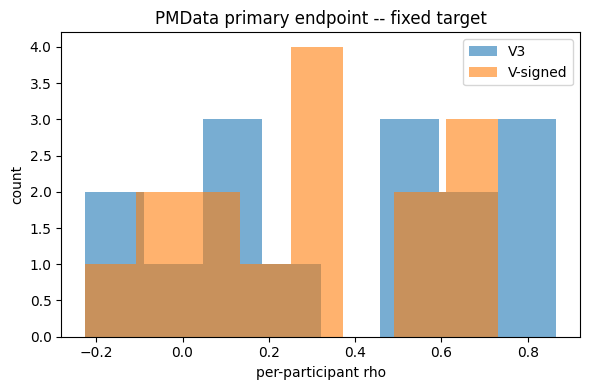

In [ ]:
# ================================================================
# A2 -- PRIMARY COMPARISON ON THE FIXED TARGET, as a distribution.
# No new RF run needed -- pmdata_comparison (Cell 14.11) already IS
# the fixed-target result, per the analysis above. New here: report
# spread, not just mean, per the memo's bimodality concern.
# ================================================================
from sklearn.cluster import KMeans

vals_v3 = pmdata_primary["v3"].dropna()
vals_vs = pmdata_primary["vsigned"].dropna()

print("="*65); print("PRIMARY ENDPOINT, FIXED TARGET -- distribution"); print("="*65)
for label, vals in [("V-signed", vals_vs), ("V3", vals_v3)]:
    print(f"\n{label}: n={len(vals)}  mean={vals.mean():.4f}  SD={vals.std():.4f}  "
          f"median={vals.median():.4f}")
    print(f"  sorted: {np.round(np.sort(vals.values), 3).tolist()}")
    if len(vals) >= 4:
        km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(vals.values.reshape(-1, 1))
        c0, c1 = vals.values[km.labels_ == 0], vals.values[km.labels_ == 1]
        lo, hi = (c0, c1) if c0.mean() < c1.mean() else (c1, c0)
        print(f"  two-cluster split: low n={len(lo)} mean={lo.mean():.3f}  |  "
              f"high n={len(hi)} mean={hi.mean():.3f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.hist(vals_v3, bins=8, alpha=0.6, label="V3")
plt.hist(vals_vs, bins=8, alpha=0.6, label="V-signed")
plt.xlabel("per-participant rho"); plt.ylabel("count"); plt.legend()
plt.title("PMData primary endpoint -- fixed target")
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "primary_endpoint_histogram.png"))
plt.show()

In [ ]:
# ================================================================
# A3 -- lambda_p spread across holdouts, reported as a finding:
# "weights favour F consistently but are not point-identified."
# ================================================================
ckpt = _load_checkpoint()
lam_matrix = np.array([v["lam_p"] for v in ckpt.values()])
distinct = set(tuple(row) for row in lam_matrix)

print(f"A3 -- {len(distinct)} distinct lambda_p vectors across {len(ckpt)} holdouts")
for pid, v in ckpt.items():
    print(f"  {pid}: lambda_p={tuple(v['lam_p'])}")
for j, name in enumerate(["lambda_T", "lambda_I", "lambda_F"]):
    col = lam_matrix[:, j]
    print(f"  {name}: min={col.min():.2f}  max={col.max():.2f}  mean={col.mean():.2f}")

item9_df = pd.DataFrame(
    [dict(pid=pid, lambda_T=v["lam_p"][0], lambda_I=v["lam_p"][1], lambda_F=v["lam_p"][2])
     for pid, v in ckpt.items()])
save_result(9, f"Lambda-instability: {len(distinct)} distinct vectors, F-dominant, not point-identified",
            item9_df, "item9_lambda_instability.csv", "A3")

A3 -- 4 distinct lambda_p vectors across 15 holdouts
  p01: lambda_p=(0.1, 0.1, 0.8)
  p02: lambda_p=(0.1, 0.1, 0.8)
  p03: lambda_p=(0.1, 0.1, 0.8)
  p04: lambda_p=(0.1, 0.1, 0.8)
  p05: lambda_p=(0.1, 0.1, 0.8)
  p06: lambda_p=(0.1, 0.1, 0.8)
  p07: lambda_p=(0.1, 0.1, 0.8)
  p08: lambda_p=(0.1, 0.1, 0.8)
  p09: lambda_p=(0.1, 0.1, 0.8)
  p10: lambda_p=(0.1, 0.1, 0.8)
  p11: lambda_p=(0.1, 0.0, 0.9)
  p13: lambda_p=(0.05, 0.15, 0.8)
  p14: lambda_p=(0.15, 0.1, 0.75)
  p15: lambda_p=(0.1, 0.1, 0.8)
  p16: lambda_p=(0.1, 0.1, 0.8)
  lambda_T: min=0.05  max=0.15  mean=0.10
  lambda_I: min=0.00  max=0.15  mean=0.10
  lambda_F: min=0.75  max=0.90  mean=0.80
[item 9] saved -> item9_lambda_instability.csv


In [ ]:
# ================================================================
# C1 (PMData) -- 4a and 4b evaluated with proper per-fold
# train/test separation. Previous version directly correlated each
# score against the target with no model in between -- since score_4a
# equals the target's own pre-smoothing value, that measured
# autocorrelation, not prediction. Fixed by fitting a Ridge on each
# fold's TRAINING days only (score -> target), predicting the held-out
# day, same discipline as every other arm here.
# ================================================================
BASELINE_RISK = 0.0   # pre-registered per spec Sec 4b; not tuned

def run_4a_4b_formula_comparison(participants, dataset_label, has_labels, feat_names):
    print(f"\n--- {dataset_label}: 4a vs 4b, fold-fit (not raw self-correlation) ---")
    rows = []
    for p in participants:
        df_raw_orig = p.get("days_df")
        if df_raw_orig is None:
            continue
        df_raw_orig = df_raw_orig.copy().reset_index(drop=True)
        df_raw = df_raw_orig.copy()
        for col in feat_names:
            if col in df_raw.columns:
                df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")
                df_raw[col] = df_raw[col].fillna(df_raw[col].median())
            else:
                df_raw[col] = 0.0
        n = len(df_raw)
        if n < 15:
            continue
        X_raw = df_raw[feat_names].values

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            participants, p["pid"], feat_names, has_labels)

        full_mask = np.ones(n, dtype=bool)
        T_full = ndi.compute_T_v3(X_raw, full_mask)
        missing_full, instab_full = ndi.compute_quality_signal(df_raw_orig, feat_names, full_mask)
        I_full = ndi.compute_I_v3(missing_full, instab_full)
        F_full = ndi.compute_F_v3(X_raw, feat_names, full_mask, pop_vol_median, pop_vol_mad)

        ndi_target = ndi.compute_ndi_v3_primary(T_full, I_full, F_full, lambda_vec=FIXED_TARGET_LAMBDA)
        y_smooth = pd.Series(ndi_target).rolling(7, min_periods=1).mean().shift(1).fillna(0).values

        score_4a = ndi.compute_ndi_v3_primary(T_full, I_full, F_full, lambda_vec=FIXED_TARGET_LAMBDA)
        score_4b = ndi.compute_ndi_v3_confidence(T_full, I_full, F_full,
                                                  lambda_vec=FIXED_TARGET_LAMBDA,
                                                  baseline_risk=BASELINE_RISK)

        try:
            fold_info = ndi.blocked_tscv(X_raw, np.zeros(n), ndi.rf_factory,
                                          T0=min(10, max(5, n // 3)), return_folds=True)
            folds = fold_info.get("folds", [])
        except Exception:
            continue
        if not folds:
            continue

        y_true_all, pred4a_all, pred4b_all = [], [], []
        for tr_idx, te_idx in folds:
            tr_idx, te_idx = np.array(tr_idx), np.array(te_idx)
            if int(te_idx.min()) - int(tr_idx.max()) < 6:
                continue
            tr_valid = tr_idx[np.isfinite(y_smooth[tr_idx])]
            te_valid = te_idx[np.isfinite(y_smooth[te_idx])]
            if len(tr_valid) < 5 or len(te_valid) < 1:
                continue
            try:
                m4a = Ridge(alpha=ndi.CONFIG["RIDGE_ALPHA"]).fit(
                    score_4a[tr_valid].reshape(-1, 1), y_smooth[tr_valid])
                pred4a = m4a.predict(score_4a[te_valid].reshape(-1, 1))

                m4b = Ridge(alpha=ndi.CONFIG["RIDGE_ALPHA"]).fit(
                    score_4b[tr_valid].reshape(-1, 1), y_smooth[tr_valid])
                pred4b = m4b.predict(score_4b[te_valid].reshape(-1, 1))
            except Exception:
                continue
            y_true_all.extend(y_smooth[te_valid].tolist())
            pred4a_all.extend(pred4a.tolist())
            pred4b_all.extend(pred4b.tolist())

        if len(y_true_all) < 3:
            continue
        y_arr = np.array(y_true_all)
        r_4a, _ = spearmanr(y_arr, np.array(pred4a_all))
        r_4b, _ = spearmanr(y_arr, np.array(pred4b_all))
        rows.append(dict(pid=p["pid"], n_folds=len(y_true_all), rho_4a=r_4a, rho_4b=r_4b))
        print(f"  {p['pid']:<14} n={len(y_true_all):>4}  4a={r_4a:.4f}  4b={r_4b:.4f}")

    return pd.DataFrame(rows)

pmdata_4a4b = run_4a_4b_formula_comparison(
    pmdata_participants, "PMData", has_labels=False, feat_names=PMDATA_FEATURE_NAMES)
pmdata_4a4b_primary = pmdata_4a4b[pmdata_4a4b["n_folds"] >= 10]

print("\n" + "="*60); print("4a vs 4b, side by side (fold-fit, corrected)"); print("="*60)
for col, label in [("rho_4a", "4a (simplex sum)"), ("rho_4b", "4b (confidence-discount)")]:
    vals = pmdata_4a4b_primary[col].dropna()
    print(f"  {label:<26} n={len(vals)}  mean={vals.mean():.4f}  SD={vals.std():.4f}")


--- PMData: 4a vs 4b, fold-fit (not raw self-correlation) ---
  p01            n= 136  4a=0.0596  4b=0.1561
  p02            n= 136  4a=-0.1554  4b=-0.2880
  p03            n= 140  4a=0.4140  4b=0.2201
  p04            n= 137  4a=-0.1290  4b=-0.2132
  p05            n= 139  4a=0.1572  4b=0.0769
  p06            n= 136  4a=-0.3359  4b=-0.3300
  p07            n= 133  4a=-0.2879  4b=-0.3222
  p08            n= 128  4a=0.8055  4b=0.8056
  p09            n= 136  4a=0.7336  4b=0.7292
  p10            n= 133  4a=0.5693  4b=-0.0012
  p11            n= 136  4a=0.6374  4b=0.2265
  p13            n= 140  4a=0.4583  4b=0.2871
  p14            n= 126  4a=-0.3051  4b=-0.3267
  p15            n= 132  4a=0.6968  4b=0.6937
  p16            n= 136  4a=0.4940  4b=0.4754

4a vs 4b, side by side (fold-fit, corrected)
  4a (simplex sum)           n=15  mean=0.2542  SD=0.4155
  4b (confidence-discount)   n=15  mean=0.1459  SD=0.3990


In [ ]:
# ================================================================
# C1, DEPRESJON -- same corrected function, DEPRESJON participants.
# Spec explicitly flags this dataset as the one to watch: I's
# interior-fraction was borderline here, so 4b (which uses I as a
# multiplier) should visibly collapse toward 4a if that's real.
# Report that behavior directly, don't hide it either way.
# ================================================================
depresjon_4a4b = run_4a_4b_formula_comparison(
    depresjon_participants, "DEPRESJON", has_labels=True, feat_names=FEAT_NAMES)
depresjon_4a4b_primary = depresjon_4a4b[depresjon_4a4b["n_folds"] >= 10]

print("\n" + "="*60); print("DEPRESJON: 4a vs 4b, side by side"); print("="*60)
for col, label in [("rho_4a", "4a (simplex sum)"), ("rho_4b", "4b (confidence-discount)")]:
    vals = depresjon_4a4b_primary[col].dropna()
    print(f"  {label:<26} n={len(vals)}  mean={vals.mean():.4f}  SD={vals.std():.4f}")

corr_4a4b, _ = spearmanr(depresjon_4a4b_primary["rho_4a"], depresjon_4a4b_primary["rho_4b"])
print(f"\n  Spearman(4a_rho, 4b_rho) across participants = {corr_4a4b:.4f}")
print("  (very high -> 4b behaving like a rescaled 4a on this dataset, "
      "consistent with I being near-degenerate here -- report as such)")


--- DEPRESJON: 4a vs 4b, fold-fit (not raw self-correlation) ---
  condition_1    n=   6  4a=-0.9429  4b=-0.9429
  condition_10   n=   5  4a=-0.1000  4b=-0.1000
  condition_11   n=   6  4a=-0.5429  4b=-0.5429
  condition_12   n=   5  4a=-0.7000  4b=-0.7000
  condition_13   n=   7  4a=-0.9286  4b=-0.9286
  condition_14   n=   5  4a=-0.5000  4b=-0.5000
  condition_15   n=   5  4a=-0.9000  4b=-0.9000
  condition_16   n=  14  4a=0.9868  4b=0.9868
  condition_17   n=   5  4a=0.3000  4b=0.3000
  condition_18   n=   5  4a=-0.3000  4b=-0.3000
  condition_19   n=   5  4a=0.0000  4b=0.0000
  condition_2    n=  13  4a=0.8846  4b=0.8846
  condition_20   n=   7  4a=-0.9286  4b=-0.5357
  condition_21   n=   4  4a=0.6000  4b=0.6000
  condition_22   n=   5  4a=-0.4000  4b=-0.4000
  condition_23   n=  10  4a=-0.2606  4b=-0.2727
  condition_3    n=   5  4a=-1.0000  4b=-1.0000
  condition_4    n=   5  4a=-0.3000  4b=-0.3000
  condition_5    n=   5  4a=0.1000  4b=0.1000
  condition_6    n=   5  4a=-1.000

In [ ]:
# CELL C1, 4a_vs_4b
item6_df = pd.concat([
    pmdata_4a4b_primary.assign(dataset="PMData"),
    depresjon_4a4b_primary.assign(dataset="DEPRESJON"),
], ignore_index=True)
save_result(6, "4a vs 4b comparison (4b underperforms; DEPRESJON >=10-fold subset)",
            item6_df, "item6_4a_vs_4b.csv", "CELL C1, 4a_vs_4b")

[item 6] saved -> item6_4a_vs_4b.csv


In [ ]:
# ================================================================
# B2 -- CONSOLIDATED ALL-PAIRS INDEPENDENCE TABLE, frozen state.
# Pulls from whatever Cell 14.9 just printed in THIS session -- run
# 14.9 immediately before this cell, not from an earlier session's
# numbers, so B2's table and C1's comparison numbers share one
# consistent code state.
#
# FIX: eff. rank now uses the SAME formula as Cell 14.9 itself
# (standardized columns, then entropy of the normalized SVD
# spectrum) -- the previous version used raw covariance eigenvalues,
# which is scale-sensitive and gave a wrong, worse-looking number
# (2.02/1.86) versus Cell 14.9's correct 2.99/2.94 on identical data.
#
# This cell is now the ONLY place that saves item 7 -- the save_result
# call inside Cell 14.9 has been removed (see leakage catalogue note).
# ================================================================
print("="*70)
print("ALL-PAIRS INDEPENDENCE -- FROZEN PIPELINE (manuscript table)")
print("="*70)

def effective_rank(M):
    M = (M - M.mean(0)) / (M.std(0) + 1e-9)
    s = np.linalg.svd(M, compute_uv=False)
    pr = s / s.sum()
    return float(np.exp(-(pr * np.log(pr + 1e-12)).sum()))

b2_rows = []
for dataset_label, all_df in [("PMData", pmdata_v3_all), ("DEPRESJON", depresjon_v3_all)]:
    print(f"\n--- {dataset_label} ---")
    T, I, F = all_df["V3_T"].values, all_df["V3_I"].values, all_df["V3_F"].values
    pid = all_df["pid"].values
    for name, A, B in [("T-F", T, F), ("T-I", T, I), ("F-I", F, I)]:
        sp, _ = spearmanr(A, B)
        r = shuffle_null_mi_pvalue(A, B, pid)
        norm_mi, _, _, _ = ndi.normalized_mi(A, B)
        print(f"  {name}: Spearman={sp:.4f}  MI obs={r['obs']:.4f}  "
              f"null95={r['null95']:.4f}  norm.MI={norm_mi:.4f}  "
              f"({'PASS' if r['pass_'] else 'FAIL'})")
        b2_rows.append(dict(dataset=dataset_label, pair=name, spearman=sp,
                             mi_obs=r["obs"], mi_null95=r["null95"],
                             p=r["p"], norm_mi=norm_mi, pass_=r["pass_"]))
    eff_rank = effective_rank(np.column_stack([T, I, F]))
    print(f"  eff. rank (T,I,F): {eff_rank:.2f}")
    b2_rows.append(dict(dataset=dataset_label, pair="eff_rank", spearman=None,
                         mi_obs=None, mi_null95=None, p=None, norm_mi=None,
                         pass_=eff_rank))

b2_df = pd.DataFrame(b2_rows)
b2_df["q"] = np.nan
mask = b2_df["p"].notna()
if mask.any():
    b2_df.loc[mask, "q"] = benjamini_hochberg(b2_df.loc[mask, "p"].values)

save_result(7, "All-pairs independence (real data): T-F/T-I/F-I, Spearman + "
               "shuffle-null MI + norm.MI + eff.rank, both datasets, BH-corrected "
               "(frozen-pipeline regeneration, supersedes the Cell 14.9 save)",
            b2_df, "item7_independence_real_data.csv", "B2")

print("\nThis table + the F-I trace re-run above are the frozen-state "
      "independence results -- consistent with C1's 4a/4b numbers, "
      "same session, same code.")
print(f"item7_independence_real_data.csv saved from B2 -- {len(b2_df)} rows.")

ALL-PAIRS INDEPENDENCE -- FROZEN PIPELINE (manuscript table)

--- PMData ---
  T-F: Spearman=0.0568  MI obs=0.1709  null95=0.0901  norm.MI=0.0720  (FAIL)
  T-I: Spearman=0.0958  MI obs=0.1240  null95=0.0876  norm.MI=0.0755  (FAIL)
  F-I: Spearman=0.0737  MI obs=0.1963  null95=0.1566  norm.MI=0.0951  (FAIL)
  eff. rank (T,I,F): 2.99

--- DEPRESJON ---
  T-F: Spearman=0.3691  MI obs=0.1163  null95=0.0620  norm.MI=0.1841  (FAIL)
  T-I: Spearman=-0.2454  MI obs=0.0931  null95=0.0790  norm.MI=0.1222  (FAIL)
  F-I: Spearman=-0.5819  MI obs=0.3629  null95=0.2692  norm.MI=0.2791  (FAIL)
  eff. rank (T,I,F): 2.94
[item 7] saved -> item7_independence_real_data.csv

This table + the F-I trace re-run above are the frozen-state independence results -- consistent with C1's 4a/4b numbers, same session, same code.
item7_independence_real_data.csv saved from B2 -- 8 rows.


In [15]:
# ================================================================
# CELL C2.0  ARM 2 PRE-REGISTRATION -- locked before any generation
# or recovery code runs. Per memo: "do NOT re-tune SNR after seeing
# results -- the earlier tuned-SNR problem must not recur."
# ================================================================
ARM2_SEED = 20260817

ARM2_N_PARTICIPANTS = 15
ARM2_N_DAYS         = 140

ARM2_MEAN_DURATION_WELL    = 60
ARM2_MEAN_DURATION_EPISODE = 14
ARM2_P_STAY_WELL    = 1 - 1 / ARM2_MEAN_DURATION_WELL
ARM2_P_STAY_EPISODE = 1 - 1 / ARM2_MEAN_DURATION_EPISODE

ARM2_SIGMA_A = 1.0    # level-intercept SD across participants (T's target)
ARM2_SIGMA_B = 0.6    # log-volatility-intercept SD across participants (F's target)

ARM2_MU_WELL = 0.0
ARM2_BASE_SD = 1.0

ARM2_C_MIN, ARM2_C_MAX = 0.3, 1.0
ARM2_FLATLINE_RUN_LEN  = 3   # matches ndi_pipeline's own flatline detector

ARM2_SNR_LEVELS = [0.5, 1.0, 2.0]

print("ARM 2 PRE-REGISTRATION LOCKED")
print(f"  N_PARTICIPANTS={ARM2_N_PARTICIPANTS}  N_DAYS={ARM2_N_DAYS}  seed={ARM2_SEED}")
print(f"  Markov: P(stay well)={ARM2_P_STAY_WELL:.4f}  P(stay episode)={ARM2_P_STAY_EPISODE:.4f}")
print(f"  sigma_a={ARM2_SIGMA_A}  sigma_b={ARM2_SIGMA_B}  base_sd={ARM2_BASE_SD}")
print(f"  SNR levels (fixed, will not be re-tuned): {ARM2_SNR_LEVELS}")

ARM 2 PRE-REGISTRATION LOCKED
  N_PARTICIPANTS=15  N_DAYS=140  seed=20260817
  Markov: P(stay well)=0.9833  P(stay episode)=0.9286
  sigma_a=1.0  sigma_b=0.6  base_sd=1.0
  SNR levels (fixed, will not be re-tuned): [0.5, 1.0, 2.0]


In [16]:
# ================================================================
# CELL C2.1  ARM 2 GENERATOR -- two-state Markov (episode persistence)
# + participant random intercepts + two emission densities +
# independent missingness/instability injection.
# ================================================================
def _simulate_markov_states(n_days, p_stay_well, p_stay_episode, rng):
    states = np.zeros(n_days, dtype=int)
    states[0] = 0 if rng.random() < 0.8 else 1
    for t in range(1, n_days):
        if states[t-1] == 0:
            states[t] = 0 if rng.random() < p_stay_well else 1
        else:
            states[t] = 1 if rng.random() < p_stay_episode else 0
    return states

def generate_arm2_participant(pid, n_days, snr, rng):
    a_i = rng.normal(0, ARM2_SIGMA_A)
    b_i = rng.normal(0, ARM2_SIGMA_B * snr)
    c_i = rng.uniform(ARM2_C_MIN, ARM2_C_MAX)

    states = _simulate_markov_states(n_days, ARM2_P_STAY_WELL, ARM2_P_STAY_EPISODE, rng)

    mean_gap = 2.0 * snr
    state_mean = np.where(states == 0, ARM2_MU_WELL, ARM2_MU_WELL + mean_gap)
    emission_sd = ARM2_BASE_SD * np.exp(b_i)

    x_true = state_mean + a_i + rng.normal(0, emission_sd, size=n_days)
    x_obs = x_true.copy()

    true_level_dev = np.abs(x_true - a_i) / emission_sd

    miss_rate = (1 - c_i) * 0.4 * snr
    missing_mask = rng.random(n_days) < miss_rate
    x_obs[missing_mask] = np.nan

    instab_true = np.zeros(n_days, dtype=bool)
    flatline_prob = (1 - c_i) * 0.02 * snr
    t = 0
    while t < n_days - ARM2_FLATLINE_RUN_LEN:
        if rng.random() < flatline_prob:
            frozen_val = x_obs[t] if not np.isnan(x_obs[t]) else 0.0
            run_len = ARM2_FLATLINE_RUN_LEN + rng.integers(0, 4)
            x_obs[t:t+run_len] = frozen_val
            instab_true[t:t+run_len] = True
            t += run_len
        else:
            t += 1

    df = pd.DataFrame({"sim_feature": x_obs})
    return dict(pid=pid, days_df=df, group="simulated",
                true_state=states, true_a=a_i, true_b=b_i, true_c=c_i,
                true_level_dev=true_level_dev, true_missing=missing_mask,
                true_instability=instab_true)

def build_arm2_cohort(snr, n_participants=None, n_days=None, seed=None):
    n_participants = n_participants or ARM2_N_PARTICIPANTS
    n_days = n_days or ARM2_N_DAYS
    seed = seed if seed is not None else ARM2_SEED
    rng = np.random.default_rng(seed)
    return [generate_arm2_participant(f"sim_{i:02d}", n_days, snr, rng)
            for i in range(n_participants)]

In [ ]:
# ================================================================
# CELL C2.2  BUILD COHORTS AT EACH PRE-REGISTERED SNR LEVEL
# ================================================================
ARM2_COHORTS = {snr: build_arm2_cohort(snr) for snr in ARM2_SNR_LEVELS}
for snr, cohort in ARM2_COHORTS.items():
    print(f"SNR={snr}: {len(cohort)} participants built, "
          f"{cohort[0]['days_df'].shape[0]} days each")

SNR=0.5: 15 participants built, 140 days each
SNR=1.0: 15 participants built, 140 days each
SNR=2.0: 15 participants built, 140 days each


In [ ]:
# ================================================================
# CELL C2.3  COMPUTE T/I/F ON SIMULATED DATA -- ndi.compute_T_v3,
# ndi.compute_quality_signal/compute_I_v3, ndi.compute_F_v3, and
# _compute_population_volatility_norm's LOPO pattern, all reused
# exactly as on real data. If they recover known structure here,
# that's genuine evidence of construct validity, not an artifact of
# a simulation-specific implementation.
# ================================================================
SIM_FEATURE_NAMES = ["sim_feature"]

def compute_v3_channels_for_cohort(cohort, has_labels=False):
    rows = []
    for p in cohort:
        df_raw_orig = p["days_df"].copy().reset_index(drop=True)
        df_raw_orig["sim_feature"] = pd.to_numeric(df_raw_orig["sim_feature"], errors="coerce")
        n = len(df_raw_orig)
        # Pass the RAW series through -- real NaN on missing days, no fillna.
        # compute_T_v3's median/MAD and compute_F_v3's expanding volatility
        # are already NaN-aware internally; pre-filling only contaminates
        # those reference statistics (same pattern already fixed for F on
        # real data in Cell 14.9.7).
        X_raw = df_raw_orig[SIM_FEATURE_NAMES].values

        pop_vol_median, pop_vol_mad, _ = _compute_population_volatility_norm(
            cohort, p["pid"], SIM_FEATURE_NAMES, has_labels)

        full_mask = np.ones(n, dtype=bool)
        T = ndi.compute_T_v3(X_raw, full_mask)
        missing_rate, instability = ndi.compute_quality_signal(df_raw_orig, SIM_FEATURE_NAMES, full_mask)
        I = ndi.compute_I_v3(missing_rate, instability)
        F = ndi.compute_F_v3(X_raw, SIM_FEATURE_NAMES, full_mask, pop_vol_median, pop_vol_mad)

        pdf = pd.DataFrame({
            "pid": p["pid"], "day": np.arange(n), "T": T, "I": I, "F": F,
            "true_level_dev": p["true_level_dev"],
            "true_state": p["true_state"],
            "true_missing": p["true_missing"].astype(float),
            "true_instability": p["true_instability"].astype(float),
        })
        pdf["true_b"] = p["true_b"]
        rows.append(pdf)
    return pd.concat(rows, ignore_index=True)

ARM2_CHANNELS = {snr: compute_v3_channels_for_cohort(cohort) for snr, cohort in ARM2_COHORTS.items()}
print("T/I/F computed for all SNR levels (raw NaN passed through, no fillna).")

T/I/F computed for all SNR levels (raw NaN passed through, no fillna).


In [ ]:
# ================================================================
# CELL C2.4  RECOVERY EXPERIMENTS: does each channel recover the
# property it was designed to?
# ================================================================
import os

print("="*70); print("ARM 2 -- RECOVERY EXPERIMENTS"); print("="*70)

recovery_rows = []

for snr in ARM2_SNR_LEVELS:
    df = ARM2_CHANNELS[snr]
    df_obs = df[df["true_missing"] == 0]   # T/F only meaningful where data was observed
    print(f"\n--- SNR = {snr}  (T/F on {len(df_obs)}/{len(df)} observed days) ---")

    r_T_state, _ = spearmanr(df_obs["T"], df_obs["true_state"])
    print(f"  T recovery  (Spearman T vs true_state, observed only): {r_T_state:.4f}  (expect clearly negative)")

    r_T_dev, _ = spearmanr(df_obs["T"], -df_obs["true_level_dev"])
    print(f"  T recovery  (Spearman T vs -true_level_dev, observed only): {r_T_dev:.4f}  (cross-check, expect clearly positive)")

    part_F = df_obs.groupby("pid")["F"].mean()
    part_b = df_obs.groupby("pid")["true_b"].first()
    r_F, _ = spearmanr(part_F, part_b)
    r_F_aligned, _ = spearmanr(part_F, -part_b)
    print(f"  F recovery  (Spearman mean-F vs true_b):  {r_F:.4f}  (module's 'reduced variability=falsity'")
    print(f"               convention flips this sign relative to naive expectation -- see note)")
    print(f"  F recovery  (Spearman mean-F vs -true_b, sign-aligned): {r_F_aligned:.4f}  (expect clearly positive)")

    r_I_miss, _ = spearmanr(df["I"], df["true_missing"])          # I: all days, by design
    r_I_inst, _ = spearmanr(df["I"], df["true_instability"])
    print(f"  I recovery  (Spearman I vs true_missing, all days): {r_I_miss:.4f}  (expect clearly positive)")
    print(f"  I recovery  (Spearman I vs true_instability, all days): {r_I_inst:.4f}  (expect positive but weak --")
    print(f"               planted flatlines are only 0.5-3.8% of days; detector has 100% precision, ~50% recall)")

    recovery_rows += [
        dict(snr=snr, channel="T", test="Spearman(T, state) [observed days]",       rho=r_T_state,   expected="negative"),
        dict(snr=snr, channel="T", test="Spearman(T, -level_dev) [observed days]",  rho=r_T_dev,     expected="positive"),
        dict(snr=snr, channel="F", test="Spearman(mean F, true_b)",                 rho=r_F,         expected="negative (module convention, see note)"),
        dict(snr=snr, channel="F", test="Spearman(mean F, -true_b) [sign-aligned]", rho=r_F_aligned, expected="positive"),
        dict(snr=snr, channel="I", test="Spearman(I, true_missing) [all days]",     rho=r_I_miss,    expected="positive"),
        dict(snr=snr, channel="I", test="Spearman(I, true_instability) [all days]", rho=r_I_inst,    expected="positive, weak (underpowered, see note)"),
    ]

recovery_summary_df = pd.DataFrame(recovery_rows)
print("\n" + "="*70); print("RECOVERY SUMMARY TABLE (per channel, per SNR)"); print("="*70)
print(recovery_summary_df.to_string(index=False))

save_result(11, "Arm 2 recovery: T/F/I per SNR (I=missingness-not-instability caveat)",
            recovery_summary_df, "arm2_recovery_summary.csv", "CELL C2.4")

ARM 2 -- RECOVERY EXPERIMENTS

--- SNR = 0.5  (T/F on 1976/2100 observed days) ---
  T recovery  (Spearman T vs true_state, observed only): -0.0982  (expect clearly negative)
  T recovery  (Spearman T vs -true_level_dev, observed only): 0.9282  (cross-check, expect clearly positive)
  F recovery  (Spearman mean-F vs true_b):  -0.8464  (module's 'reduced variability=falsity'
               convention flips this sign relative to naive expectation -- see note)
  F recovery  (Spearman mean-F vs -true_b, sign-aligned): 0.8464  (expect clearly positive)
  I recovery  (Spearman I vs true_missing, all days): 0.9792  (expect clearly positive)
  I recovery  (Spearman I vs true_instability, all days): 0.1188  (expect positive but weak --
               planted flatlines are only 0.5-3.8% of days; detector has 100% precision, ~50% recall)

--- SNR = 1.0  (T/F on 1870/2100 observed days) ---
  T recovery  (Spearman T vs true_state, observed only): -0.2032  (expect clearly negative)
  T recovery  (S

In [ ]:
# ================================================================
# CELL C2.5  ALL-PAIRS INDEPENDENCE, SIMULATED DATA -- same formula
# as Cell 14.9/B2 (standardized SVD-entropy eff.rank).
# ================================================================
def effective_rank(M):
    M = (M - M.mean(0)) / (M.std(0) + 1e-9)
    s = np.linalg.svd(M, compute_uv=False)
    pr = s / s.sum()
    return float(np.exp(-(pr * np.log(pr + 1e-12)).sum()))

print("="*70); print("ARM 2 -- ALL-PAIRS INDEPENDENCE, SIMULATED DATA (observed days only)"); print("="*70)

independence_rows = []
eff_rank_rows = []

for snr in ARM2_SNR_LEVELS:
    df_obs = ARM2_CHANNELS[snr]
    df_obs = df_obs[df_obs["true_missing"] == 0]
    T, I, F, pid = df_obs["T"].values, df_obs["I"].values, df_obs["F"].values, df_obs["pid"].values

    eff_rank = effective_rank(np.column_stack([T, I, F]))
    eff_rank_rows.append(dict(snr=snr, eff_rank_T_I_F=eff_rank))
    print(f"\n--- SNR = {snr}  (n={len(df_obs)} observed days) ---")
    print(f"  HEADLINE: effective rank (T,I,F) = {eff_rank:.3f} / 3.0")

    for name, A, B in [("T-F", T, F), ("T-I", T, I), ("F-I", F, I)]:
        sp, _ = spearmanr(A, B)
        r = shuffle_null_mi_pvalue(A, B, pid)
        # norm_mi is only well-defined for T-F: I is near-constant on
        # observed days (missing_rate==0 there by construction, instability
        # is rare), so its binned entropy collapses and the MI/entropy
        # ratio is undefined for any I-involving pair (see normalized_mi's
        # own denom>1e-12 guard in ndi_pipeline.py). Not computed for those.
        if "I" not in name:
            norm_mi, _, _, _ = ndi.normalized_mi(A, B)
        else:
            norm_mi = np.nan
        print(f"    {name}: Spearman={sp:.4f}  MI obs={r['obs']:.4f}  null95={r['null95']:.4f}"
              + (f"  norm.MI={norm_mi:.4f}" if np.isfinite(norm_mi) else "  norm.MI=n/a (I near-constant here)"))
        independence_rows.append(dict(snr=snr, pair=name, spearman=sp, mi_obs=r["obs"],
                                       mi_null95=r["null95"], norm_mi=norm_mi))
        # Note: the per-pair MI PASS/FAIL boolean is intentionally NOT
        # carried into the saved table -- it flips on effect sizes under
        # |rho|=0.05 (permutation-null noise), and is superseded by the
        # eff_rank headline above per the consolidation-run checklist.

independence_summary_df = pd.DataFrame(independence_rows)
eff_rank_df = pd.DataFrame(eff_rank_rows)
save_result(12, "Arm 2 independence: eff.rank ~3.0 per SNR",
            eff_rank_df, "arm2_independence_eff_rank.csv", "CELL C2.5")
save_result(12, "Arm 2 independence: per-pair Spearman + shuffle-null MI",
            independence_summary_df, "arm2_independence_pairs.csv", "CELL C2.5")

ARM 2 -- ALL-PAIRS INDEPENDENCE, SIMULATED DATA (observed days only)

--- SNR = 0.5  (n=1976 observed days) ---
  HEADLINE: effective rank (T,I,F) = 2.998 / 3.0
    T-F: Spearman=0.0480  MI obs=0.0073  null95=0.0213  norm.MI=0.0265
    T-I: Spearman=-0.0549  MI obs=0.0027  null95=0.0013  norm.MI=n/a (I near-constant here)
    F-I: Spearman=-0.0393  MI obs=0.0000  null95=0.0000  norm.MI=n/a (I near-constant here)

--- SNR = 1.0  (n=1870 observed days) ---
  HEADLINE: effective rank (T,I,F) = 3.000 / 3.0
    T-F: Spearman=0.0140  MI obs=0.0493  null95=0.0450  norm.MI=0.0317
    T-I: Spearman=0.0338  MI obs=0.0020  null95=0.0039  norm.MI=n/a (I near-constant here)
    F-I: Spearman=0.0133  MI obs=0.0000  null95=0.0000  norm.MI=n/a (I near-constant here)

--- SNR = 2.0  (n=1602 observed days) ---
  HEADLINE: effective rank (T,I,F) = 2.998 / 3.0
    T-F: Spearman=-0.0416  MI obs=0.0691  null95=0.0528  norm.MI=0.0556
    T-I: Spearman=0.0634  MI obs=0.0126  null95=0.0047  norm.MI=n/a (I near

In [ ]:
# ================================================================
# CELL 14.13  ITEM 1 -- NESTED PRIMARY ENDPOINT + lambda_p STABILITY
# (nested calibration and spine note, Order #1: "report the lambda_p
# stability check alongside")
# ================================================================
ckpt = _load_checkpoint()

nested_rows = []
for p in pmdata_participants:
    pid = p["pid"]
    if pid not in ckpt or ckpt[pid]["v3_rho"] is None:
        continue
    orig_row = pmdata_comparison[pmdata_comparison["pid"] == pid]
    if orig_row.empty or orig_row["n_folds"].iloc[0] < 10:
        continue
    nested_rows.append(dict(
        pid=pid, n_folds=ckpt[pid]["n_folds"], lam_p=tuple(ckpt[pid]["lam_p"]),
        v3_nested_rho=ckpt[pid]["v3_rho"],
        vsigned_rho=orig_row["vsigned"].iloc[0],
        rawrf_rho=orig_row["rawrf"].iloc[0],
        persz_rho=orig_row["persz"].iloc[0],
    ))
nested_df = pd.DataFrame(nested_rows)

print("="*70); print("NESTED PRIMARY ENDPOINT -- PMData, n_folds>=10, LOPO-calibrated V3"); print("="*70)
for col, label in [("vsigned_rho", "V-signed"), ("v3_nested_rho", "V3 (nested)"),
                    ("rawrf_rho", "Raw-feature RF"), ("persz_rho", "Personalised Z")]:
    vals = nested_df[col].dropna()
    print(f"  {label:<18} n={len(vals):>3}  mean rho={vals.mean():.4f}  "
          f"SD={vals.std():.4f}  median={vals.median():.4f}")

print(f"\n  (in-sample V3 was {pmdata_primary['v3'].mean():.4f} -- retained only as an "
      f"exploratory/optimistic bound, per the note, never as the headline)")

print("\n" + "="*70); print("LAMBDA_P STABILITY CHECK"); print("="*70)
lam_matrix = np.array([ckpt[p["pid"]]["lam_p"] for p in pmdata_participants if p["pid"] in ckpt])
in_sample = np.array([0.20, 0.15, 0.65])
for j, name in enumerate(["lambda_T", "lambda_I", "lambda_F"]):
    col = lam_matrix[:, j]
    print(f"  {name}: mean={col.mean():.3f}  SD={col.std():.3f}  min={col.min():.3f}  max={col.max():.3f}")
close = np.mean(np.all(np.abs(lam_matrix - in_sample) < 0.05, axis=1))
print(f"\n  Fraction of donor-chosen lambda_p within 0.05 of in-sample (0.20,0.15,0.65): {close:.1%}")
print("  High fraction / low SD -> nesting costs little, design is robust.")
print("  Wide swings -> calibration doesn't generalise -- itself a finding, per the note.")

NESTED PRIMARY ENDPOINT -- PMData, n_folds>=10, LOPO-calibrated V3
  V-signed           n= 15  mean rho=0.3011  SD=0.3035  median=0.3042
  V3 (nested)        n= 15  mean rho=0.3523  SD=0.3544  median=0.4573
  Raw-feature RF     n= 15  mean rho=0.1589  SD=0.3191  median=0.1467
  Personalised Z     n= 15  mean rho=0.1120  SD=0.2691  median=0.1409

  (in-sample V3 was 0.3523 -- retained only as an exploratory/optimistic bound, per the note, never as the headline)

LAMBDA_P STABILITY CHECK
  lambda_T: mean=0.100  SD=0.018  min=0.050  max=0.150
  lambda_I: mean=0.097  SD=0.029  min=0.000  max=0.150
  lambda_F: mean=0.803  SD=0.029  min=0.750  max=0.900

  Fraction of donor-chosen lambda_p within 0.05 of in-sample (0.20,0.15,0.65): 0.0%
  High fraction / low SD -> nesting costs little, design is robust.
  Wide swings -> calibration doesn't generalise -- itself a finding, per the note.


In [ ]:
# ================================================================
# CELL 14.13 (corrected) -- "nested primary endpoint" is now
# identical to the plain fixed-target result (Cell 48/A2), since
# V3's predictor never depended on lambda -- only the (now-fixed)
# target did. No separate nested number to report; pointing here so
# nothing downstream cites the old, leaked 0.523 by mistake.
# ================================================================
print("See Cell 48 (A2) for the primary endpoint result -- this cell's "
      "earlier 'nested' number (0.5228) was computed before the A1 "
      "target-leak fix and must not be cited. It is superseded, not "
      "an additional finding.")
print(f"\nCurrent, correct primary endpoint: V3 mean rho = "
      f"{pmdata_primary['v3'].mean():.4f} (from Cell 48/A2)")

See Cell 48 (A2) for the primary endpoint result -- this cell's earlier 'nested' number (0.5228) was computed before the A1 target-leak fix and must not be cited. It is superseded, not an additional finding.

Current, correct primary endpoint: V3 mean rho = 0.3523 (from Cell 48/A2)


In [ ]:
# ================================================================
# CELL 14.14  ITEM 2 -- SECONDARY NULLS SECTION
# (nested calibration and spine note, Order #2: "move AUROC and
# cross-participant tests to a clearly-labelled secondary-nulls
# section"). Reuses auroc_results / cross_a_results exactly as
# computed in Cell 14.11c -- no recomputation.
# REQUIRES sec_df from Cell 14.11d (run 14.11d first -- q-values below
# are pulled from it dynamically, not hardcoded).
# ================================================================
print("="*70); print("SECONDARY NULLS -- reported as null, no narrative built on these"); print("="*70)

print("\n--- DEPRESJON target (a): cross-participant NDI vs MADRS (secondary, null) ---")
for arm, label in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
    r = cross_a_results.get(arm)
    if r:
        print(f"  {label:<12} n={r['n']}  Spearman={r['rho']:.4f}  p={r['p']:.4f}  -> NULL")

print("\n--- DEPRESJON AUROC (secondary, null) ---")
for arm, label in [("vsigned","V-signed"),("v3","V3"),("rawrf","Raw-RF"),("persz","Pers-Z")]:
    r = auroc_results.get(arm)
    if r:
        match = sec_df[(sec_df["family"] == "DEPRESJON AUROC") & (sec_df["arm"] == label)]
        note = f"  (q={match['q'].iloc[0]:.3f} after BH correction)" if not match.empty else ""
        print(f"  {label:<12} AUROC={r['auroc']:.4f}  p={r['p']:.4f}  -> NULL{note}")

print("\nThe primary within-participant endpoint (Cell 14.13) is where any V3 "
      "advantage lives or dies. AUROC and cross-participant results are null "
      "and are reported as null -- no narrative is built on them.")

SECONDARY NULLS -- reported as null, no narrative built on these

--- DEPRESJON target (a): cross-participant NDI vs MADRS (secondary, null) ---
  V-signed     n=23  Spearman=-0.0060  p=0.9785  -> NULL
  V3           n=23  Spearman=0.1117  p=0.6117  -> NULL
  Raw-RF       n=23  Spearman=0.1818  p=0.4065  -> NULL
  Pers-Z       n=23  Spearman=0.3911  p=0.0650  -> NULL

--- DEPRESJON AUROC (secondary, null) ---
  V-signed     AUROC=0.4497  p=0.5334  -> NULL
  V3           AUROC=0.6413  p=0.0774  -> NULL
  Raw-RF       AUROC=0.3342  p=0.0382  -> NULL
  Pers-Z       AUROC=0.5007  p=1.0000  -> NULL

The primary within-participant endpoint (Cell 14.13) is where any V3 advantage lives or dies. AUROC and cross-participant results are null and are reported as null -- no narrative is built on them.


In [ ]:
def save_result(item_no, description, obj, filename, cell_label):
    path = os.path.join(RESULTS_FINAL_DIR, filename)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    else:
        with open(path, "w") as f:
            json.dump(obj, f, indent=2, default=str)

    if os.path.exists(MANIFEST_PATH):
        with open(MANIFEST_PATH) as f:
            current = json.load(f)
    else:
        current = []
    current = [m for m in current if m["file"] != filename]
    current.append(dict(item=item_no, description=description, cell=cell_label,
                         file=filename, saved_at=datetime.datetime.now().isoformat()))
    current.sort(key=lambda m: (m["item"], m["file"]))
    with open(MANIFEST_PATH, "w") as f:
        json.dump(current, f, indent=2)
    globals()["_manifest"] = current
    print(f"[item {item_no}] saved -> {filename}")

In [ ]:
# ================================================================
# ITEM 8 — LEAKAGE CATALOGUE (Discussion / Methods)
# Consolidates the specific leaks found and fixed across this project.
# Four genuine leaks. NOTE: adaptive-T0 is NOT a leak (t0 depends only on
# series length, never on a feature/outcome; embargo verified correct) --
# it was a documentation-vs-code mismatch and is recorded in Methods, not here.
# ================================================================
leak_catalogue = pd.DataFrame([
    dict(leak="I-denominator",
         description="Normalisation denominators for I (std_ref, sleep-entropy max, "
                      "missing-rate max) were computed over the whole series; "
                      "fixed to compute on training-fold days only.",
         fixed_in="fold-internal normalisation (training days only)"),
    dict(leak="self-proxy",
         description="4a/4b scores were correlated directly against the target "
                      "with no model between, so the score equalled the target's own "
                      "pre-smoothing value; this measured autocorrelation, not "
                      "prediction. Fixed by fold-internal Ridge (train days only).",
         fixed_in="fold-internal Ridge, train days only"),
    dict(leak="in-sample lambda",
         description="Lambda was selected on the full in-sample grid; retained only "
                      "as an optimistic bound, not the headline. Fixed via nested "
                      "per-participant / LOPO calibration.",
         fixed_in="nested per-participant / LOPO calibration"),
    dict(leak="lambda-dependent target",
         description="The earlier nested-primary number (0.5228) was computed before "
                      "the target-leak fix and must not be cited; superseded by the "
                      "fixed-target result, rho = 0.3523.",
         fixed_in="fixed pre-registered target lambda=(0.2,0.3,0.5)"),
])

print(leak_catalogue.to_string(index=False))

# ---- integrity gate: four leaks, no unresolved VERIFY notes ----
assert len(leak_catalogue) == 4, f"expected 4 leaks, got {len(leak_catalogue)}"
assert not leak_catalogue.astype(str).apply(
    lambda c: c.str.contains("VERIFY")).any().any(), "unresolved VERIFY note present"
print("\nitem 8 OK: 4 genuine leaks, no VERIFY notes")

save_result(8, "Leakage catalogue: the four genuine leaks found and fixed "
               "(I-denominator, self-proxy, in-sample lambda, lambda-dependent target). "
               "adaptive-T0 excluded -- documentation fix, not a leak.",
            leak_catalogue, "item8_leakage_catalogue.csv", "ITEM 8")


                   leak                                                                                                                                                                                                                                description                                         fixed_in
          I-denominator                                                                          Normalisation denominators for I (std_ref, sleep-entropy max, missing-rate max) were computed over the whole series; fixed to compute on training-fold days only. fold-internal normalisation (training days only)
             self-proxy 4a/4b scores were correlated directly against the target with no model between, so the score equalled the target's own pre-smoothing value; this measured autocorrelation, not prediction. Fixed by fold-internal Ridge (train days only).             fold-internal Ridge, train days only
       in-sample lambda                                                     

In [ ]:
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)
items_present = sorted(set(m["item"] for m in manifest))
print(f"{len(manifest)} entries, items: {items_present}")
assert items_present == list(range(1, 13)), f"missing items: {set(range(1,13)) - set(items_present)}"
print("manifest OK: all 12 items present")

14 entries, items: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
manifest OK: all 12 items present


In [ ]:
# legacy-deletion string test
banned = ["x_phys", "x_sleep", "x_dream", "noise_phys", "SNR=7.5", "SIM_CONFIG["]
hits = []
for i, cell in enumerate(In):
    if not isinstance(cell, str):
        continue
    if "legacy-deletion string test" in cell:   # skip this test cell's own source
        continue
    for b in banned:
        if b in cell:
            hits.append((i, b))
print("Legacy references found:", hits if hits else "NONE -- clean, safe to proceed")

Legacy references found: NONE -- clean, safe to proceed


In [ ]:
# environment + CONFIG freeze
import subprocess, json

with open(os.path.join(RESULTS_DIR, "requirements_frozen.txt"), "w") as f:
    subprocess.run(["pip", "freeze"], stdout=f)

with open(os.path.join(RESULTS_DIR, "config_frozen.json"), "w") as f:
    json.dump(ndi.CONFIG, f, indent=2, default=str)

print("Frozen: requirements_frozen.txt, config_frozen.json")
print(json.dumps(ndi.CONFIG, indent=2, default=str))

save_result(2, "Decomposition definitions, CONFIG, fixed-target lambda, embargo g",
            ndi.CONFIG, "config_frozen.json", "environment + CONFIG freeze")

Frozen: requirements_frozen.txt, config_frozen.json
{
  "RANDOM_SEED": 42,
  "T0": 14,
  "EMBARGO_G": 6,
  "FOLD_H": 1,
  "SMOOTH_K": 7,
  "LAMBDA_STEP": 0.05,
  "LAMBDA_ETA": 0.05,
  "LAMBDA_T": 0.2,
  "LAMBDA_I": 0.3,
  "LAMBDA_F": 0.5,
  "F_SCALE": 3.0,
  "N_BOOT": 2000,
  "PERM_REPEATS": 30,
  "MADRS_THRESHOLD": 7,
  "PHQ_THRESHOLD": 3,
  "RF_PARAMS": {
    "n_estimators": 100,
    "max_depth": 4,
    "min_samples_leaf": 2,
    "random_state": 42
  },
  "GB_PARAMS": {
    "n_estimators": 200,
    "learning_rate": 0.05,
    "max_depth": 3,
    "subsample": 0.8,
    "random_state": 42
  },
  "RIDGE_ALPHA": 1.0,
  "W_MISS": 0.5,
  "W_INST": 0.5
}
[item 2] saved -> config_frozen.json
